# 誰が一家離散するのか
## ── シミュレーション仏教の経済と、裾の重い運

## 第 0 章 このノートについて

文責: JRF ( http://jrf.cocolog-nifty.com/statuses/ )<br>
解析・執筆・Lean の証明の補助: Claude Opus 5.5 (Anthropic)<br>
2026年10月

---

### この文書について

この文書は、同じ作者の古い考えを読み直すシリーズの一冊である。

この文書の材料は、作者が 2021 年に作った**シミュレーション仏教**(simbd、https://github.com/JRF-2018/simbd )の、**経済の部分**である。シミュレーション仏教は、「古代」風の社会に、結婚・不倫・相続・支配・災害・戦争・僧・犯罪を組み込み、宗教(仏教)がなぜ生まれ、どう社会を支えるかを見ようとした大きなシミュレーションである。作者はそれを電子本『「シミュレーション仏教」の試み』にまとめた。全体はこのシリーズで扱うには重すぎるので、ここでは経済の部分だけを取り出す。

simbd の経済は、作者のほかの経済モデルとまったく違う作り方をしている。電子本にはこうある。

> このシミュレーションの経済は、本稿の最初のほうで説明した経済シミュレーションと違い、最適化を使っていない。家族単位で、現在の資産を元にランダムに所得が手に入るようにして、資産の変動を表している。そのため、支出と収入のバランスが経済全体で合う…といったような望ましい性格は、このシステムにおいては存在しない。

ノート 1 の micro_economy は、価格を最適化で決め、**平均**の価格と生産を見ていた。simbd の経済には、価格も市場もない。家族が資産を「債券」「株式」「大バクチ」「死蔵」「農地」に分け、それぞれから**裾の重い運**で所得が入る。見ているのは、分布の**裾**、つまり、誰が全財産を失うか、である。作者は 2021 年の 10 月に、構想のログにこう書いた。

> そういう面において私が今、一番気になっているのは、経済において資産を失い、一家離散になるところ。この数が多いのが気になっている。その数を減らす何か良い考え方はないものか…。

この文書の題は、この問いから取った。

### このシリーズ

同じ作者(JRF)の、AI 以前の経済の模型と構想を、今の目で読み直すシリーズである。書かれた順に並べる(読む順の勧めも同じ)。ノート O の O は Origin(始まり)で、作者の経済のシミュレーションの始まりにあたる 2011 年の模型を扱う。

- ノート 1「価格を最適化で決める経済 ── 2020年までの micro_economy モデルの解剖」(`micro_economy_anatomy.ipynb`)
- ノート O「経済の中で経済が育つ ── 2011年の外作用モデルと『埋め込み』の遷移」(`embedded_economy.ipynb`)
- ノート 2「土地と知財と借金 ── 2019年の資産市場シミュレーションの解剖」(`asset_market.ipynb`)
- ノート P「ポイントと年金と信用 ── ネットの小さな通貨の設計(2006〜2018)」(`points_pension.ipynb`)
- ノート I「必需品と贅沢品の宇宙的独立関係 ── 絶滅の確率、0 × ∞、ナイト的不確実性、そして学習」(`cosmic_independence.ipynb`)
- ノート 3「誰が一家離散するのか ── シミュレーション仏教の経済と、裾の重い運」(`simbd_economy.ipynb`) ← **この文書**
- ノート M「雑多なモデルの再検討 ── 必需品と贅沢品、縁故主義、投票、AI と弾圧」(`misc_models.ipynb`)
- ノート 4「2026年の経済モデル統合 ── 価格と信用と土地と災害、そして一人の暮らし」(`integrated_model.ipynb`)

### この文書で考える問い

1. 「正規分布 + マイナスのレヴィ分布」の運は、経済に何をもたらすか。
2. 「大バクチ → 株式 → 大バクチ → 債券 → 死蔵」という資産配分の滝は、合理的か。
3. 一家離散はなぜ起き、誰に起きるか。どうすれば減らせるか。経済的な憎しみと教化は、どう効くか。
4. 「法定準備率を下げると、まず大バクチが増え、次に死蔵が増える」(作者、2025 年)は、模型にできるか。それは、信用循環モデル(credit_simulation)の実効準備率 ρ_eff = ρ + μ·max(0, Φ − θ) と、どうつながるか。
5. simbd の家族の経済は、作者のほかのモデル(micro_economy、資産市場、信用循環)の、どこに当たるか。
6. 災害は、家族の経済に何をするか。災害を内生化する(守りと記憶で被害が決まる)と、何がわかるか。
7. どうすれば、よりリアルな simbd の経済になるか(シミュレーション仏教への提案)。

### 答えの見通し

結論を先に書いておく(詳しくは各章と、第 9 章のまとめで)。

1. **裾の重い運は、それだけで「金持ちほど効率よく増える」性質を生む**(第 2 章、Lean)。レヴィ分布には平均がなく、元手で切り捨てると平均ができるが、その損失は元手 K の平方根でしか伸びない。元手あたりの損失は 1/√K で減る。作者が見た「資産が途方もなく大きくなっていく」は、運の分布の形から来る。また、simbd の実際の乱数は、大バクチの設計の表と違う作り方をしていて、大バクチは設計より 4〜8 倍ほど損になっていた(第 2.5 節)。
2. **滝は、期待値の最適化ではない**(第 3 章)。株式と債券の期待値は正、死蔵と大バクチは負なので、期待値や対数の最適化なら大バクチは選ばれない。大バクチの値打ちは、上の裾(跳躍)だけにある。「下に壁があると賭けが得になる」は正しい(Lean)が、この模型では生活保護の床がほとんど効かず、その合理化は働いていない。一方、種類ごとに損失を切り捨てるしくみは**有限責任**と同じ形で、それだけで期待値を上げる(Lean)。作者の「分散投資の根拠は何か」への一つの答えである。
3. **一家離散が起きうるのは、子どものいない働き手だけの家族、とくに一人暮らしだけである**(第 4 章)。帳簿から、年末の資産の底が −25.5 × 労働力 と決まり、線 −20 × 人数 を割り込めるのは、労働力 / 人数 > 0.78 の家族だけになる。作者が「必要最低限」として選んだロスカット 27.5 は、この臨界値(22)のすぐ上にある。そのうえで、
   - **元の simbd 全体では、数えられた一家離散の大半は、年の途中で死んだ一人暮らしの、帳簿の清算である**。資産の所得を一年の平均の資産で計算し、損を年末の(相続で空になった)資産で清算するずれから、**死者が一家離散する**(第 4.5 節)。
   - **経済だけを取り出した ec3 では、くじで農地を割り当てられ、借金で買わされた、独り身の小農が一家離散する**(第 4.3〜4.4 節)。
   - 元のコードの一行(資産の所得を年末の資産で計算する。帳簿の時計を一つにする)で、死者の一家離散は消える(第 8.2 節)。
   - 減らす案のうち、いちばん安くて効くのは家族全体の有限責任(免責)、貧しい層の底上げまでするのは「口分田」(払えない農地の代金の払い下げ)である。相互扶助(頼母子講)は、家族ごとの有限責任の値打ちを壊して、富を半分近くに減らす。
   - 経済的な憎まれは、裾を太らせて一家離散を増やす経路で効くが、教化による宥めがそれをほぼ塞いでいる(作者の「思うほどそうなっていなかった」の説明)。教化は憎しみを減らすが、酷使をやめた地主の取り分も減らす。
4. **お金がだぶつくと、まず大バクチが増えて上限で頭打ちになり、次に死蔵が増える**(第 5 章)。死蔵の割合は、上位への富の集中度の**折れ線**になり、傾きはほぼ 1、閾値は上限の和 / 富になる(数値と Lean)。上位の富を利子の所得の元本とみると、ρ_eff = ρ + μ·max(0, Φ − θ) と同じ形が出る(μ = Y/(rW)、θ = rmB/Y)。上位に厚みがあれば、角は丸まる(softplus 型)。credit_creation_v6 のノートで銀行の貸倒れから導いたのとは別の、**主体の側からの二つ目の根拠**になる。ただし、上位の富を利子の元本とみる仮定は、simbd の中では確かめられない。また、だぶついたお金は死蔵と損な大バクチに入り、20 年ほどで消える。作者の「総資産が膨れるのは違う」は正しい。
5. **simbd の家族は、v6b の「標本」の家計に使える**(第 6 章、第 9 章)。simbd の経済は独立な家族のくじの集まりで、家族の間の相互作用がないので、人口や上昇志向を変えても一人あたりの量はわずかしか動かない(作者の「変わるはずが変わらない」の説明)。標本としては、死蔵の割合は標本 500 家族で 1 割弱の誤差で推定できるが、一家離散は危険のある層の外では起きないので、その層だけを標本にとると、分散が 1 桁小さくなる。
6. **災害は富を減らし、回復は遅いが、一家離散の数はかえって減ることがある**(第 7 章)。怪我で働けなくなった独り身は、帳簿の式のとおり、もう一家離散できない。一家離散の数は、災害の害の物差しにならない。打撃の相関で、効く安全網が変わる(家族ごとの打撃には有限責任、局地の打撃には相互の保険、共通の打撃には年をまたぐ国の蓄えと守り。共通の打撃に相互扶助をすると、かえって害になる)。災害は、守りの資本と記憶で内生化できる。守りの量は頻度の信念とともに増え、信念は記録から学ばれる。**忘れる社会は、記録の実効の年数が頭打ちになり、信念の区間が縮まない**(Lean)。静かな時代に守りを手放し、大災害で大きく損をする。ノート I の「社会が経済を学習する」の、具体的な形である。
7. **よりリアルにするには、帳簿の時計を一つにし、支払いを誰かの所得にし、収益率を内生化する**(第 8 章)。一人暮らしでない家族の一家離散は、一家離散の基準(首が回らない状態が 3 年続く)に、借金の利子、子の養育の費用、借りて商売をする道を組み合わせると出る。子沢山の貧しい家族や、運の悪い商人の破産である。災害のあとに固まって起き、親族の助けがあると、子のある家族の一家離散は消える(第 8.5 節)。地主の払う賃金を雇い人の所得にするだけで、Gini は 0.62 → 0.45、中央の富は 3 倍、一家離散は 1/10 になる。調整の数は、目標の統計量に合わせて選ぶ(作者の「最適化で書く」を、模型の調整に使う)。どの部品も、切れば元と同じ数になる。

### Lean による証明

議論の要の命題を、定理証明支援系 **Lean 4**(と数学ライブラリ Mathlib)で証明する。証明は、章ごとに `%%writefile -a breakup.lean` でファイルに書き足していき、第 9 章の付録 A で一括して Lean に確かめさせる。

| 章 | 定理 | 中身 |
|---|---|---|
| 2 | `truncated_loss_mean`、`loss_per_capital`、`two_sqrt_sub_mono`、`increasing_returns_to_scale` | 切り捨てたレヴィの損失の期待値は 2√(θK) − θ。元手あたりの損失は、元手が大きいほど小さい |
| 3 | `limited_liability`、`limited_liability_expect` | 損失を種類ごとに切り捨てた和は、まとめて切り捨てた値以上(有限責任の値打ち) |
| 3 | `floor_convexity` | 下に壁があると、平均が同じなら、ばらついた賭けの期待値は下がらない |
| 5 | `hoard_equal_split`、`hoard_ratio`、`hoard_as_rho_eff`、`hoard_lower_bound`、`hoard_concentration` | 上限を超えた富(死蔵)の割合は、集中度の折れ線。v6 の言葉では ρ_eff の形になる。集中が進むと死蔵は増える |
| 7 | `protection_amgm`、`protection_monotone`、`posterior_mean_mix`、`forgetting_bound` | 守りの最適な量と、その頻度の信念への単調性。記録からの学習(事後の平均は事前と記録の混ぜ合わせ)。忘れる社会は、記録の実効の年数が 1/(1 − ω) を超えない |

### 読み方

- 各章は、作者の設計、今の数学での読み方、Lean の定理、シミュレーション、の順に進む。
- コードのセルは、`%%writefile` でモジュールのファイルを書き出し、そのあとのセルで使う。上から順に実行すれば、すべての結果が再現される。元のコードは、GitHub から版を固定して取ってくる(インターネットへの接続が要る)。
- 計算は、乱数の種を固定してある(元の simbd 全体だけは、完全には再現しない。付録 A)。並列に計算するので、CPU の数が多いほど速い(28 コアの計算機で全体 25 分ほど)。
- Lean の確かめには、Lean 4(v4.34.1)と Mathlib の入った lake のプロジェクトが要る。`.leandir` というファイルにその場所が書いてなければ、付録 A の「Lean の準備」のセルが elan と Mathlib を入れる(Google Colab でもそのまま通る。初めは 10 分ほど。付録 A)。

### 目次

- 第 0 章 このノートについて
- 第 1 章 価格のない経済 ── simbd の経済のしくみ
- 第 2 章 裾の重い運 ── 正規分布 + マイナスのレヴィ分布
- 第 3 章 資産配分の滝
- 第 4 章 誰が一家離散するのか
- 第 5 章 法定準備率と大バクチと死蔵
- 第 6 章 戦争・人口・上昇志向の実験の読み直し
- 第 7 章 災害と経済 ── 共通の打撃、守りの資本、記憶と学習
- 第 8 章 シミュレーション仏教への提案 ── よりリアルな版
- 第 9 章 四つの層の対応表、v6b の標本、そしてまとめ
- 付録 A: 再現のために
- 付録 B: 用語集
- 付録 C: 過去の議論
- 参考文献

### 準備

In [1]:
import os, sys, shutil, subprocess, importlib, random, time
import numpy as np
import matplotlib, matplotlib.pyplot as plt

PAL = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': INK2, 'axes.labelcolor': INK, 'xtick.color': INK2, 'ytick.color': INK2,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False,
    'lines.linewidth': 2.0, 'font.size': 10, 'axes.titlesize': 11, 'legend.frameon': False,
    'figure.dpi': 100,
})
print('Python', sys.version.split()[0], '/ numpy', np.__version__, '/ matplotlib', matplotlib.__version__)
print('CPU の数:', os.cpu_count())
LEANDIR = open('.leandir').read().strip() if os.path.exists('.leandir') else None
print('Lean のプロジェクト:', 'あり(.leandir に書いた場所)' if LEANDIR else 'なし(第 9 章の確かめの前に、elan と Mathlib を入れる)')
T0 = time.time()
if os.path.exists('exp3_cache.pkl'):
    os.remove('exp3_cache.pkl')     # 実験の覚え書き(同じ計算の使い回し)は、このノートの実行の中だけで使う

Python 3.14.4 / numpy 2.5.4 / matplotlib 3.11.2
CPU の数: 28
Lean のプロジェクト: あり(.leandir に書いた場所)


Lean のファイルの頭を書いておく(定理は、章ごとに書き足す)。

In [2]:
%%writefile breakup.lean
/-
  「誰が一家離散するのか ── シミュレーション仏教の経済と、裾の重い運」の Lean による定式化
  文責: JRF / 定式化・証明: Claude Opus 5.5
  Lean 4 v4.34.1 + Mathlib
-/
import Mathlib

open Finset

namespace SimbdEconomy

Writing breakup.lean


---

## 第 1 章 価格のない経済 ── simbd の経済のしくみ

### 1.1 simbd の中での経済

シミュレーション仏教は、一か月を一期として進む。人々は生まれ、結婚し、不倫し、子を産み、相続し、病気や災害や戦争で傷つき、死ぬ。僧になる者もいれば、罪を犯して牢に入る者もいる。経済は、その中で**一年に一度**、十二月に清算される(電子本「経済」の章)。

経済の単位は**家族**である。扶養の関係で家族をまとめ、家族ごとに一年の所得と消費を決める。一年の流れは、次のとおり。

1. **家族の値を作る**(元の `make_families`)。家族の商業資産は一年の平均、農地は和。上昇志向(ambition)・教化(education)・熱心さ(eagerness)は、働く者の最大の 2/3 と、労働で重みをつけた平均の 1/3。商業の経験・農業の経験は、家族の中の最大。
2. **資産の所得**(元の `calc_asset_income`)。商業資産を、債券・株式・大バクチ・死蔵に分け(資産配分の滝。第 3 章)、それぞれから「正規分布 + マイナスのレヴィ分布」の運で損益が出る(第 2 章)。農地は一単位ずつ運で収益が出て、雇い人の賃金が引かれる。
3. **労働の所得**(元の `calc_labor_income`)。労働力に比例し、仕事運で上下する。仕事運が高いとシビアな仕事を求められ、**経済的な憎しみ**が増える。
4. **安全網と消費**(元の `calc_income`)。資産の損失の全体の上限(ロスカット)、生活保護、強い消費、家族の中での分け方、**一家離散**、寄付。
5. **農商比率を保つ**(元の `keep_merchant_peasant_ratio`)。農民と商人の比を 68 : 20 に、農地の数の分布の形を負の二項分布に保つよう、農地を割り当て直す。

価格はどこにも出てこない。財の需要と供給もない。所得は運で決まり、消費は所得と資産の関数で決まる。だから、ノート 1 の micro_economy のような「価格を最適化で決める」部分は、ここにはない。代わりにあるのは、**分布**を作る仕掛けである。

### 1.2 元のコードを取ってくる

元のコード(public domain)は、作者の GitHub のリポジトリ JRF-2018/simbd にある。版を固定し(commit e602dfd、2022-03-17)、sha256 で中身を確かめてから使う。中身は変えない。

In [3]:
%%writefile orig3.py
"""orig3.py -- 元のコード(JRF-2018/simbd)を取ってきて、そのまま走らせる道具。

- 取ってくるのは commit e602dfd(2022-03-17)の版。sha256 で中身が同じことを確かめる。
- 中身は変えない。print の出力は捨てる。
"""
import os, sys, io, random, hashlib, contextlib, urllib.request, importlib, importlib.util
import numpy as np

COMMIT = 'e602dfd85fbc818e1d30dbfea01659438cc7a7b4'
URL = f'https://raw.githubusercontent.com/JRF-2018/simbd/{COMMIT}/'
SHA256 = {
    'test_of_income_1.py': '6b8144f6f43c9b2f2e411a2c28017e393d47128d3fc79177831b3f9ffd65604b',
    'normal_levy_1.0.csv': 'e4ba21dbb64212e664f5024aefacad539f5ab86e46428e9c00c6298296e16bac',
    'generate_normal_levy_csv.py': '52d2ba11fd4e02e9cd8413477eb9378df8c060ebb2e8eaa07d447a13072c3c62',
    'simbdp3/__init__.py': 'e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855',
    'simbdp3/base.py': '67e8b4129fe0ca1023758c8117c90b572fd842e9483184305b4c9ed4a723e3f3',
    'simbdp3/common.py': '70f7c25eddc0a49329f46be610de6afbaa89b7efcfca35cdce2c2d660aaaf3dd',
    'simbdp3/random.py': 'ae2ec789bad226ffa69d1c0cb05447afdb21c58776849ff2a30ec7dceb3688b6',
    'simbdp3/moving.py': 'f9118e7dc5e15e9d5eaaf33a08d8de2a2935e4881a8b180507ddc3e633fb44b5',
    'simbdp3/economy.py': '72834509d81177a1f0f1fd17ec6cc0b5b71b285bd4560ff12286b7e866e4d688',
    # simbd 全体を走らせるときに要るもの
    'simbdp3.py': '1022918f48b11e2278f9162bc92bc2701d62a88636160b7d27e62eedf387f2d6',
    'simbdp3/adultery.py': '4aba37e1544569075920a03e8cb00a9bddc7eb4d6d53428635d9e976ab1a9805',
    'simbdp3/birth.py': '27bdc75ead8908a42f9165190e23bc3375b3a85ac28990bf8f9330a4ccf55065',
    'simbdp3/calamity.py': '2ab658af621bc6449cb6c5f27c3375888ad8b69f3cba5596d5ab307080cd0d0d',
    'simbdp3/crime.py': '25b53d59d9f3a406bd91ca8dc32eeaffefa9d10e22f53a74946d604c1e48c77a',
    'simbdp3/death.py': '70353fbfd74638a17a80b8e9758d1fdcf1a1dff665b09b607b00f3f59e76b681',
    'simbdp3/domination.py': 'e07a072e319c2cc03156366bb5e88d770b794195837096823c3e3016ba176664',
    'simbdp3/inherit.py': 'efe2b13453b9c88ee49d8f3968b4ff4ac93b814ce40b0c4207fb5a35473913cb',
    'simbdp3/init.py': 'f9581edb0da02a4f41af233e200fad5ddc2c3fa4a24f9f88aafea8c923a02915',
    'simbdp3/marriage.py': '2ff8c7dec748a258ea43bf1a2cbd32f8f192882adbbdffca16868213fa41bd73',
    'simbdp3/misc.py': '0de7247022b9609795b3b1cbabd4d51501bfea9ff5ca8cc38f689d3702078bf6',
    'simbdp3/priest.py': '17918acb17e77fa44692b2bb84476da762df4171272c1d2f2c07615340f7d3e6',
    'simbdp3/support.py': 'efcc7098b91729d5a699c25e0565603900295426b9e46c88ec82191e685e53df',
}
CACHE = os.path.abspath('orig_simbd')
ECONOMY_FILES = ('simbdp3/__init__.py', 'simbdp3/base.py', 'simbdp3/common.py', 'simbdp3/random.py',
                 'simbdp3/moving.py', 'simbdp3/economy.py')


def fetch(name):
    """CACHE になければ GitHub から取ってくる。sha256 が合わなければ止める。"""
    path = os.path.join(CACHE, name)
    if not os.path.exists(path):
        os.makedirs(os.path.dirname(path), exist_ok=True)
        with urllib.request.urlopen(URL + name, timeout=60) as r:
            data = r.read()
        import threading
        tmp = f'{path}.{os.getpid()}.{threading.get_ident()}.tmp'   # 並列に走らせても壊れないよう、書いてから置き換える
        with open(tmp, 'wb') as f:
            f.write(data)
        os.replace(tmp, path)
    data = open(path, 'rb').read()
    h = hashlib.sha256(data).hexdigest()
    if h != SHA256[name]:
        raise ValueError(f'{name}: sha256 が違う ({h})')
    return data.decode('utf-8')

Writing orig3.py


In [4]:
%%writefile -a orig3.py
def load_test1(argv=()):
    """test_of_income_1.py をモジュールとして読み込む(main は呼ばない。argparse に argv を渡す)。"""
    src = fetch('test_of_income_1.py')
    fetch('normal_levy_1.0.csv')
    m = importlib.util.module_from_spec(importlib.util.spec_from_loader('test_of_income_1', loader=None))
    exec(compile(src, 'test_of_income_1.py', 'exec'), m.__dict__)
    m.ARGS.normal_levy_csv = os.path.join(CACHE, 'normal_levy_1.0.csv')
    sys.argv = ['test_of_income_1.py'] + list(argv)
    m.parse_args()
    return m


def load_simbdp3_economy():
    """simbdp3/economy.py を、元のパッケージのまま読み込む。ARGS は空なので、使う側で埋める。"""
    for n in ECONOMY_FILES:
        fetch(n)
    fetch('normal_levy_1.0.csv')
    if CACHE not in sys.path:
        sys.path.insert(0, CACHE)
    E = importlib.import_module('simbdp3.economy')
    B = importlib.import_module('simbdp3.base')
    return E, B


@contextlib.contextmanager
def quiet():
    """元のコードの print を捨てる。"""
    with contextlib.redirect_stdout(io.StringIO()):
        yield


def run_t1(argv=(), trials=50, seed=0):
    """作者の test_of_income_1.py を、そのまま走らせる(main の絵を描く部分だけを除き、同じ順に initialize と step を呼ぶ)。"""
    m = load_test1(argv)
    random.seed(seed); np.random.seed(seed)
    e = m.Economy()
    m.initialize(e)
    rows = [(0, np.mean([p.prop for p in e.people]), np.max([p.prop for p in e.people]))]
    with quiet():
        for i in range(trials):
            m.step(e)
            rows.append((i + 1, np.mean([p.prop for p in e.people]), np.max([p.prop for p in e.people])))
    return np.array(rows)

Appending to orig3.py


### 1.3 作者の経済だけのテスト: test_of_income_1.py

作者は、simbd に経済を組み込む前に、経済だけを切り出したテスト `test_of_income_1.py` を作り、分布の形を確かめていた(2021 年 1〜10 月、構想のログ)。一人ずつ(家族ではない)、1000 人、生活保護も一家離散もない版である。これを、そのまま走らせる(絵を描く部分だけを除き、元の `initialize` と `step` を同じ順に呼ぶ)。

作者のオプションのうち、「強い消費」(`--strong-consumption`)と「強い寄付」(`--strong-donation`)を切り替える。

年                      standard        strong consumption           strong donation                      both
  0     平均      81 最大    321   平均      81 最大    321   平均      81 最大    321   平均      81 最大    321
 10     平均     257 最大   1114   平均     115 最大    698   平均      74 最大    290   平均      40 最大    215
 20     平均     714 最大   2463   平均     188 最大   1237   平均      80 最大    309   平均      34 最大    239
 30     平均    1476 最大   4105   平均     294 最大   1644   平均      80 最大    316   平均      33 最大    195
 40     平均    2376 最大   5809   平均     419 最大   2057   平均      82 最大    269   平均      31 最大    228
 50     平均    3352 最大   6773   平均     568 最大   2296   平均      82 最大    303   平均      30 最大    194


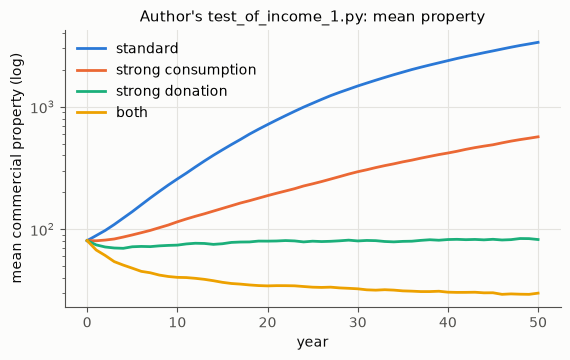

In [5]:
import orig3
T1 = {}
for lab, argv in (('standard', []), ('strong consumption', ['--strong-consumption']),
                  ('strong donation', ['--strong-donation']),
                  ('both', ['--strong-consumption', '--strong-donation'])):
    T1[lab] = orig3.run_t1(argv, trials=50)
print('年    ' + ''.join(f'{lab:>26s}' for lab in T1))
for t in (0, 10, 20, 30, 40, 50):
    print(f'{t:3d}  ' + ''.join(f'   平均 {r[t, 1]:7.0f} 最大 {r[t, 2]:6.0f}' for r in T1.values()))
fig, ax = plt.subplots(figsize=(6.4, 3.6))
for c, (lab, r) in zip(PAL, T1.items()):
    ax.semilogy(r[:, 0], r[:, 1], color=c, label=lab)
ax.set(xlabel='year', ylabel='mean commercial property (log)', title="Author's test_of_income_1.py: mean property")
ax.legend(); plt.show()

標準の設定では、平均の資産が 50 年で 81 から 3000 を超えるまで増え続ける。作者の言う「全財産を摩る可能性があるから、平均化されるかというとそんなことはなく、人々の資産が途方もなく大きくなっていく」である。強い消費(所得の多い者も 4〜5 割を消費し、資産の 6% を毎年消費する)を入れると伸びは鈍るが、止まらない。強い寄付(商業資産が多いほど、確率的に資産の一部を寄付する)を入れると、平均 80 ほどで止まる。この「寄付と強い消費」が、simbd の経済に入った。なぜ止めないと発散するのかは、第 2 章で式にする。

### 1.4 書き直し: ec3.py

simbd の経済は、simbd 全体(人の生死、結婚、扶養、支配、災害)の上で動く。全体を回すと遅く、経済の仕掛けだけを調べるのに向かない。そこで、経済の部分を読める大きさに書き直す(`ec3.py`)。方針は、ノート 1 と同じ二本立てである。

- **一年の経済の計算は、元と同じ数になる**ように書く。乱数も、元と同じく Python の `random` と numpy の `np.random` を、同じ順に引く。同じ乱数の状態から始めれば、元と同じ数が出ることを、テストで示す(1.5 節)。
- 結婚・不倫・支配・犯罪・災害・僧は除き、**人口の動き**だけを簡単なもので置き換える(子どもは 15〜18 歳で資産 0 で独立し、8 割は同じ年に独立した者と結婚する。死ぬと配偶者が引き継ぎ、二人とも死ねば子どもたちで均分に相続する。出生は人口の目標で調整する)。ここは一致テストの外である。

まず、パラメータ。既定値は simbdp3.py の値と同じで、ec3 で足した仕掛け(第 4・5・7・8 章の実験)は、既定値では切ってあり、切れば元と同じ計算になる。

In [6]:
%%writefile ec3.py
"""ec3.py -- シミュレーション仏教(simbd、simbdp3 v0.0.11)の経済の部分の書き直し。

- 元: JRF-2018/simbd の simbdp3/economy.py(calc_asset_income、calc_labor_income、calc_income、
  keep_merchant_peasant_ratio_1)。結婚・不倫・支配・犯罪・災害・僧は除き、家族の顔ぶれは簡単な世代交代で動かす。
- 一年の計算は、同じ乱数の状態から始めれば元と同じ数になる(test_ec3.py で確かめる)。
  そのため、乱数は元と同じく Python の random と numpy の np.random を、同じ順に引く。
- 元にない仕掛け(第 4・5 章の実験)は、P の既定値では切ってあり、既定値のままなら元と同じ計算になる。
"""
import math
import random
from dataclasses import dataclass, field, replace
import numpy as np


@dataclass
class P:
    """パラメータ。既定値は simbdp3.py の ARGS と同じ(人口だけ小さい)。"""
    n_families: int = 1000
    peasant_ratio: float = 68.0 / (68.0 + 20.0)  # 農商比率 68 : 20
    prop_value_of_land: float = 10.0             # 農地一単位 = 商業資産 10
    init_prop_sigma: float = 100.0
    land_r: float = 1.5                          # 農地の数の分布(負の二項分布)
    land_theta: float = 0.2
    land_max_growth: int = 5
    consumption: float = 3.0                     # 成人一人の最低の消費
    prop_theta_mag: float = 1.0                  # レヴィの裾の大きさの倍率
    hated_mag: float = 1.0
    stress_mag: float = 1.0
    donation_rate: float = 0.3                   # 寄付は商業資産の 0〜30%
    donation_limit: float = 1000.0               # 商業資産がこれを超えると必ず寄付する
    donation_education: float = 0.3
    donation_education_2: float = 0.3
    consumption_education: float = 0.1
    consumption_education_2: float = 0.1
    consumption_education_3: float = 0.1
    bond_max: float = 1000.0                     # 債券・株式・大バクチの上限
    stock_max: float = 300.0
    gamble_max: float = 50.0
    no_landlord_thrift: bool = False
    debt_slack: float = 20.0                     # 一家離散の線: −20 × 家族の人数
    cut_slack_rate: float = 1.1                  # 種類ごとの損失の上限: 元手の 1.1 倍
    whole_cut_slack: float = 27.5                # 資産の損失の全体の上限: −27.5 × 労働力
    merchant_hated_update: float = 0.1
    merchant_hated_down_mag: float = 0.2
    merchant_hating_update: float = 0.1
    merchant_hating_down_mag: float = 0.2
    # --- ここから下は ec3 で足したもの(既定値では元と同じ) ---
    levy_z: str = 'uniform'       # レヴィの部分の作り方。元の simbdp3 は θ/U²(U 一様)。'normal' は θ/Z²(表と test_of_income_1 の作り方)
    gamble_mu: dict = None        # 大バクチの μ の表(cut → μ)。None なら元の normal_levy_1.0.csv
    soothe: bool = True           # 教化による憎しみの宥め(元の priest.py の soothe_nation_hating を一年ぶんに縮めたもの)
    family_liability: bool = False    # 第 4 章の案 (c): 家族全体の有限責任(負の富を免責して、一家離散にしない)
    pool_luck: bool = False           # 第 4 章の案 (b): 頼母子講(貧しい家族どうしで資産の所得を平均する)
    crowding: dict = None             # 第 5 章: 種類ごとの商売のネタの量 {'bond': A, 'stock': A, 'gamble': A}(一家族あたり)。
                                      # 前の年の総額がこれを超えると、収益の μ が (ネタの量 / 総額) 倍に下がる(大バクチは平均が負に寄る)
    land_grant: bool = False          # 第 4 章の案 (d): 口分田。農地を割り当てられた者が払えない分を、国が払い下げる(借金で買わせない)
    # --- 第 7 章: 災害(既定値では切ってある。切れば乱数も引かない) ---
    disaster: object = None           # Disaster(下)を与えると、災害が起きる
    protect_share: float = 0.0        # 国の予算(寄付)のうち、守りの資本に回す割合
    protect_scale: float = 20.0       # 守りの資本が一家族あたりこれだけあると、被害が半分になる
    protect_decay: float = 0.05       # 守りの資本の一年の劣化
    relief: str = 'none'              # 'none' / 'state'(予算の残りを救済の蓄えにし、災害の被害を埋める)/ 'mutual'(その年の被害を全家族で分け合う)
    fund_cap: float = 3.0             # 救済の蓄えの上限(その年の予算の何年分か)。超えた分は使われない(元と同じく消える)
    learning: dict = None             # 災害の頻度を記録から学び、守りに回す割合を決める(下の update_learning)
    # --- 第 8 章: よりリアルな版の部品(既定値では切ってある) ---
    wage_to_workers: bool = False     # 地主の払う賃金を、農地のない家族の労働の所得にする(一年遅れ)
    sales_margin: float = 0.0         # 消費のこの割合を、商人(株式で商売をする家族)の売り上げにする(一年遅れ)
    # --- 第 8.5 節: 一家離散が起きる基準(既定値では元と同じ) ---
    breakup_rule: str = 'members'     # 'members': 線は −debt_slack × 人数(元)。'labor': 線は −debt_slack × 労働力(返す力)。
                                      # 'streak': 資産の合計が負の年が streak_years 年続いたら(首が回らない状態が続く)
    streak_years: int = 3
    leverage: float = 0.0             # 経験 10 年以上の商人が、株式の額のこの倍を借りて商売を大きくする(借りた分の損益はロスカットで消えない)
    loan_rate: float = 0.1            # 借りた分の利子(一年)
    debt_rate: float = 0.0            # 商業資産が負の家族が払う、借金の利子(一年)
    child_cost: float = 0.0           # 15 歳未満の子一人あたり、最低の消費に上乗せする養育の費用
    kin_rescue: float = 0.0           # 子のある家族が一家離散しそうなとき、親の家族が富のこの割合までで借金を肩代わりする
    kin_take: bool = False            # 一家離散のとき、15 歳未満の子は親の家族(祖父母)に引き取られる
    two_clocks: bool = False          # 元の simbd の「二つの時計」を再現する: 死は年の途中に起き、遺産はその場で相続され、
                                      # 資産の所得は一年の平均の資産で、損の上限は年末の資産で計算される(切れば時計は一つ)
    education_range: tuple = (0.0, 1.0)   # 教化の分布の範囲(一様)。第 4.6 章
    ambition_range: tuple = (0.0, 1.0)    # 上昇志向の分布の範囲(一様)。第 6 章(元の --change-ambition の代わり)
    land_vector: bool = False         # test_of_income_1 の農地の計算(一単位ごとの切り捨てなし、乱数をまとめて引く)


def np_clip(x, a, b):
    return a if x < a else (b if x > b else x)

Writing ec3.py


裾の重い乱数(第 2 章で詳しく見る)と、大バクチの μ の表。

In [7]:
%%writefile -a ec3.py
# 正規分布 + マイナスのレヴィ分布。元の simbdp3/random.py の normal_levy_rand(size=None の道)と同じ順に乱数を引く。
def normal_levy_rand(mu, sigma, theta, cut, z_kind='uniform'):
    if z_kind == 'uniform':
        z = random.random()                  # 元の simbdp3: 一様乱数 U で θ / U²
    else:
        z = np.random.normal(0, 1)           # 表と test_of_income_1: 正規乱数 Z で θ / Z²
    y = - mu / 2 + theta * (1e100 if z == 0.0 else 1 / (z ** 2))
    z2 = random.gauss(mu / 2, sigma) if z_kind == 'uniform' else np.random.normal(mu / 2, sigma)
    return z2 - y if z2 - y > cut else cut


GAMBLE_TABLE = None


def gamble_mu(cut, table=None):
    """大バクチの μ: 期待値がほぼ 0 になる μ を、切り捨ての線 cut ごとに引いた表(元の normal_levy_1)。"""
    global GAMBLE_TABLE
    if table is None:
        if GAMBLE_TABLE is None:
            import csv
            from orig3 import fetch
            rows = list(csv.reader(fetch('normal_levy_1.0.csv').splitlines(), quoting=csv.QUOTE_NONNUMERIC))
            GAMBLE_TABLE = np.array(rows).T.tolist()
        table = GAMBLE_TABLE
    import bisect
    a = bisect.bisect_left(table[0], cut)
    if a >= len(table[0]):
        raise ValueError(f'{cut} は表の範囲の外')
    if a == 0:
        a = 1
    x0, x1, y0, y1 = table[0][a], table[0][a - 1], table[1][a], table[1][a - 1]
    return ((y1 - y0) / (x1 - x0)) * (cut - x0) + y0

Appending to ec3.py


家族と、家族の値。

In [8]:
%%writefile -a ec3.py
@dataclass
class Member:
    prop: float = 0.0          # 商業資産
    land: int = 0              # 農地(整数)
    labor: float = 1.0         # 労働力(0.1〜1。子どもは 0.1)
    age: int = 30
    leader: bool = False
    married: bool = False
    education: float = 0.5     # 教化
    ambition: float = 0.5      # 上昇志向
    eagerness: float = 0.5     # 熱心さ
    stock_exp: int = 0         # 商業の経験(年)
    land_exp: int = 0          # 農業の経験(年)
    merchant_hated: float = 0.0    # 経済的な憎まれ(農地で人を使うときに生じる)
    merchant_hating: float = 0.0   # 経済的な憎しみ(シビアな労働から生じる)
    cum_donation: float = 0.0
    consumption: float = 0.0
    tmp_land_damage: float = 0.0   # その年の農地の被害の割合(災害。元の tmp_land_damage)

    def asset_value(self, lv):
        return self.prop + self.land * lv


@dataclass
class Family:
    members: list = field(default_factory=list)   # members[0] が家長
    # 一年の計算のときに作る家族の値(元の make_families)
    prop: float = 0.0
    land: int = 0
    education: float = 0.0
    ambition: float = 0.0
    eagerness: float = 0.0
    stock_exp: int = 0
    land_exp: int = 0
    merchant_hated: float = 0.0
    tmp_land_damage: float = 0.0

    @property
    def leader(self):
        return self.members[0]

    def asset_value(self, lv):
        return self.prop + self.land * lv

    def trained_ambition(self):
        if self.ambition > 0.5:
            return (1 - 0.2 * self.education) * self.ambition
        return 1 - (1 - 0.2 * self.education) * (1 - self.ambition)

    def trained_eagerness(self):
        if self.eagerness > 0.5:
            return self.eagerness
        return 1 - (1 - 0.2 * self.education) * (1 - self.eagerness)


def make_family_values(f):
    """元の make_families の、家族の値を作る部分。元は 12 か月の記録の平均だが、ここでは一年の値を使う。"""
    f.prop = sum(p.prop for p in f.members)
    f.land = sum(p.land for p in f.members)
    f.tmp_land_damage = (sum(p.land * p.tmp_land_damage for p in f.members) / f.land) if f.land > 0 else 0.0
    f.merchant_hated = f.leader.merchant_hated
    aged = [p for p in f.members if p.age > 1]
    if aged:
        f.stock_exp = max(p.stock_exp for p in aged)
        f.land_exp = max(p.land_exp for p in aged)
        for n in ('education', 'ambition', 'eagerness'):
            q = sum(p.labor for p in aged)
            a = sum(getattr(p, n) * p.labor for p in aged) / q if q > 0 else 0
            l2 = [p for p in aged if p.labor > 0]
            m = max(getattr(p, n) for p in (l2 if l2 else aged))
            setattr(f, n, m * (2 / 3) + a * (1 / 3))   # 働く者の最大の 2/3 と、労働で重みをつけた平均の 1/3

Appending to ec3.py


資産の所得。資産配分の滝(`allocate`、第 3 章)と、種類ごとの運。熱心さが低いほど、経済的な**憎まれ**(農地で人を使うときに生じる恨み)が高いほど、レヴィの裾 θ が太る(`stress`)。農地では、教化が低い地主ほど一人に多くの農地を任せて酷使し、憎まれる。

In [9]:
%%writefile -a ec3.py
def allocate(f, P, prop=None):
    """資産配分の滝(乱数を使わない部分)。prop を与えれば、家族の商業資産をその値に置きかえて配分を計算する。"""
    if prop is None:
        prop = f.prop
    # 農地の維持に要る商業資産
    land_prop = (100 / 50) * f.land if f.land > 50 else 0.04 * (f.land ** 2)
    prop = prop - land_prop
    dprop = 0
    if prop < 0:
        prop = 0
    land_prop_effect = 0
    if f.land > 0:
        q = min((land_prop + prop / 3) / f.land, 100 / 50)
        land_prop_effect = q / (100 / 50)
        r = q * f.land - land_prop
        if r > 0:
            prop = max(prop - r, 0)
    # 資産配分の滝: 上昇志向の分を株式(経験しだい)と大バクチへ、残りを債券へ。上限を超えれば次へ、最後は死蔵
    aprop = f.trained_ambition() * prop
    bprop = prop - aprop
    srat = 1.0 if f.stock_exp >= 10 else f.stock_exp / 10.0
    sprop = aprop * srat if aprop * srat >= 5 else 0
    gprop = aprop - sprop
    if gprop < 5:
        bprop += gprop
        gprop = 0
    k = 1 + 0.3 * (len(f.members) - 1)       # 上限は家族の人数で少し広がる
    if sprop > P.stock_max * k:
        gprop += sprop - P.stock_max * k
        sprop = P.stock_max * k
    if gprop > P.gamble_max * k:
        bprop += gprop - P.gamble_max * k
        gprop = P.gamble_max * k
    if bprop > P.bond_max * k:
        dprop += bprop - P.bond_max * k
        bprop = P.bond_max * k
    return land_prop, land_prop_effect, srat, (bprop, sprop, gprop, dprop)


def asset_income(f, P, stat=None):
    """資産の所得(元の calc_asset_income)。資産配分の滝と、種類ごとの正規 + レヴィの収益。"""
    lv = P.prop_value_of_land
    stock_exp = land_exp = 0
    hated_update = 0
    land_prop, land_prop_effect, srat, (bprop, sprop, gprop, dprop) = allocate(f, P)
    seagerness = f.trained_eagerness() * 0.5 + srat * 0.5
    stress = 0.7 * (1 - seagerness) + 0.3 * f.merchant_hated * P.hated_mag   # 熱心さが低く、憎まれが高いほど裾が太る
    cr = getattr(P, '_mult', None) or {}
    zk = P.levy_z

    bincome = sincome = gincome = dincome = lincome = 0
    if bprop >= 1:   # 債券
        cut = - bprop * P.cut_slack_rate
        mu = - cut / 5 * 0.3
        sigma = 0.01 * 10 * mu * 0.5
        theta = 0.01 + 0.01 * P.stress_mag * stress
        mu = - cut / 5 * (0.2 + (0.3 - 0.2) * srat) * cr.get('bond', 1.0)
        bincome = normal_levy_rand(mu, sigma, P.prop_theta_mag * theta, cut, zk)
    if sprop >= 5:   # 株式
        stock_exp = 1
        cut = - sprop * P.cut_slack_rate
        mu = - cut / 5 * 1.0
        sigma = 0.1 * 10 * mu * 0.5
        theta = 0.1 + 0.1 * P.stress_mag * stress
        mu = - cut / 5 * (0.8 + (1.0 - 0.8) * srat) * cr.get('stock', 1.0)
        sincome = normal_levy_rand(mu, sigma, P.prop_theta_mag * theta, cut, zk)
    f._loan_income = 0.0
    f._loan = 0.0
    if P.leverage > 0 and srat >= 1.0 and sprop >= 5:   # 借りて商売を大きくする(第 8.5 節)
        loan = P.leverage * sprop
        lcut = - loan * P.cut_slack_rate
        lmu = - lcut / 5 * 1.0 * cr.get('stock', 1.0)
        lsigma = 0.1 * 10 * (- lcut / 5 * 1.0) * 0.5
        ltheta = 0.1 + 0.1 * P.stress_mag * (0.7 * (1 - (f.trained_eagerness() * 0.5 + srat * 0.5)) + 0.3 * f.merchant_hated * P.hated_mag)
        x = normal_levy_rand(lmu, lsigma, P.prop_theta_mag * ltheta, lcut, zk)
        x -= loan * min(1.0, getattr(f, '_dis_frac', 0.0))      # 災害は、借りて持っていた商売の資産も壊す
        f._loan_income = x - P.loan_rate * loan
        f._loan = loan
    if gprop >= 5:   # 大バクチ
        stock_exp = 1
        cut = - gprop * P.cut_slack_rate
        mu = gamble_mu(cut, P.gamble_mu) * 0.9
        if 'gamble' in cr:
            mu += - cut / 5 * (cr['gamble'] - 1.0)
        sigma = 1 * 10
        theta = 1 + 1 * P.stress_mag * stress
        gincome = normal_levy_rand(mu, sigma, P.prop_theta_mag * theta, cut, zk)
    if dprop > 0:    # 死蔵
        cut = - dprop * P.cut_slack_rate
        theta = 0.01 + 0.01 * P.stress_mag * stress
        dincome = normal_levy_rand(0, 0.01 * 10, P.prop_theta_mag * theta, cut, zk)
    worker_num = 0
    if f.land >= 1:  # 農地: 一単位ずつ収益が出て、そこから雇い人の賃金を引く
        land_exp = 1
        lrat = 1.0 if f.land_exp >= 10 else f.land_exp / 10
        leagerness = f.trained_eagerness() * 0.5 + lrat * 0.5
        cut = - lv * P.cut_slack_rate
        mu = - cut / 5 * 2.0
        sigma = 0.08 * 10 * mu * 0.5
        theta = 0.08 + 0.08 * P.stress_mag * (0.7 * (1 - leagerness) + 0.3 * f.merchant_hated * P.hated_mag)
        mu = - cut / 5 * (1.5 + (2.0 - 1.5) * (land_prop_effect * (0.5 + 0.5 * lrat)))
        land_per_worker = 1 + (2.0 - 1.0) * (1 - f.education)          # 教化が低いと、一人に多くの農地を任せる(酷使)
        wage_per_worker = (6 + (7.5 - 6) * (1 - f.education)) / 5
        dmg = f.tmp_land_damage                                         # 災害による農地の被害(元と同じ扱い)
        virtual_land = f.land * (1 - dmg) + 0.5 * f.land * dmg
        worker_num = virtual_land / land_per_worker
        wage = wage_per_worker * worker_num
        f._wage = wage
        if P.land_vector:   # test_of_income_1: まとめて引き、賃金は合計から引く
            z = np.random.normal(0, 1, size=f.land)
            y = - mu / 2 + theta * np.where(z == 0, 1e100, 1 / (z ** 2))
            z2 = np.random.normal(mu / 2, sigma, size=f.land)
            lincome = float(np.sum(np.where(z2 - y > cut, z2 - y, cut))) - wage
        else:
            for i in range(f.land):
                x = normal_levy_rand(mu, sigma, theta, cut, zk)
                if x > 0:
                    x *= (1 - dmg)
                x -= wage / f.land
                if x < cut:
                    x = cut
                lincome += x
        # 憎まれ: 教化が 0.5 より低い地主は酷使して憎まれ、高い地主は少しずつ許される
        w = 1.0 if worker_num > 5 else worker_num / 5
        if f.education < 0.5:
            hated_update += P.merchant_hated_update * ((1 - f.education) - 0.5) / 0.5 * w
        else:
            hated_update -= P.merchant_hated_update * P.merchant_hated_down_mag * (f.education - 0.5) / 0.5 * w
    f._alloc = (bprop, sprop, gprop, dprop)
    f._inc = (bincome, sincome, gincome, dincome, lincome)
    if stat is not None:
        for key, v in (('bond', bprop), ('stock', sprop), ('gamble', gprop), ('dead', dprop), ('land', f.land * lv)):
            stat['amt_' + key] += v
        for key, v in (('bond', bincome), ('stock', sincome), ('gamble', gincome), ('dead', dincome), ('land', lincome)):
            stat['inc_' + key] += v
    return bincome + sincome + gincome + dincome + lincome, stock_exp, land_exp, hated_update

Appending to ec3.py


労働の所得。仕事運が高いと収入が多いが、シビアな仕事を求められ、経済的な**憎しみ**が増える。資産の所得が十分にない家族は、上昇志向が高いとシビアな仕事を選ぶ。

In [10]:
%%writefile -a ec3.py
def labor_income(f, aincome, P):
    """労働の所得(元の calc_labor_income)。仕事運が高いとシビアな仕事を求められ、経済的な憎しみが増える。"""
    base = P.consumption
    income_luck = random.random()
    if len(f.members) > 1:
        income_luck = (income_luck + random.random()) / 2      # 二人以上なら運が平均に寄る
    infant = sum(((1 - 0) / (0 - 10) * (p.age - 10)) ** 2 for p in f.members if p.age <= 10)
    labor = max(sum(p.labor for p in f.members) - np_clip(infant, 0, 1), 0)
    ta = f.trained_ambition()
    if f.asset_value(P.prop_value_of_land) < 0:     # 負の資産の家族は、シビアな仕事をする代わりに収入が少し高い
        if aincome >= 10.0 * labor:
            severeness = 0.2 + 0.8 * (random.random() * (0.5 * (1 - income_luck) + 0.5))
            income = labor * (base * (5 / 3) + (0.5 * income_luck + 0.1) * base * (3 / 3))
        else:
            severeness = 0.2 + 0.8 * np_clip((0.5 * ta + random.random()) * (0.5 * (1 - income_luck) + 0.5), 0.0, 1.0)
            income = labor * (base * (7 / 3) + (0.5 * income_luck + 0.5 * ta) * base * (5 / 3))
    else:
        if aincome >= 6.0 * labor:                    # 資産の所得が多ければ、労働の必要が薄れる
            severeness = random.random() * (0.5 * (1 - income_luck) + 0.5)
            income = labor * (base * (5 / 3) + (0.5 * income_luck + 0.1) * base * (3 / 3))
        else:
            severeness = np_clip((0.5 * ta + random.random()) * (0.5 * (1 - income_luck) + 0.5), 0.0, 1.0)
            income = labor * (base * (5 / 3) + (0.5 * income_luck + 0.5 * ta) * base * (3 / 3))
    if severeness > 0.5:
        hating_update = P.merchant_hating_update * (severeness - 0.5) / 0.5
    else:
        hating_update = - P.merchant_hating_update * P.merchant_hating_down_mag * ((1 - severeness) - 0.5) / 0.5
    return income, hating_update

Appending to ec3.py


一年の所得・消費・寄付・一家離散。安全網は三層ある。

1. **ロスカット**: 資産の損失は、全体で「資産の価値 + 27.5 × 労働力」まで(資産が正の家族)。
2. **生活保護**: 労働の所得も、資産と所得の和も最低の消費(労働力 × 2 + 人数 × 1)に届かなければ、最低の消費を満たす所得を得る。
3. **借金の余裕**: 家族の資産の合計が負でも、−20 × 人数 までは、家族で借金を分け合って続ける。それを割り込むと**一家離散**して、土地と商業資産をすべて失う。

In [11]:
%%writefile -a ec3.py
def new_stat():
    keys = ['breakup', 'breakup_multi', 'rescue', 'rescue_amt', 'breakup_dead', 'escheat', 'wages', 'dis_n', 'dis_loss', 'relief_paid', 'protect', 'fund', 'phi', 'belief', 'welfare', 'welfare_amt', 'donation', 'consumption', 'income_asset', 'income_labor', 'debt_relief']
    keys += [a + k for a in ('amt_', 'inc_') for k in ('bond', 'stock', 'gamble', 'dead', 'land')]
    return dict.fromkeys(keys, 0.0)


def year_income(families, P, stat):
    """一年の所得・消費・寄付・一家離散(元の calc_income)。"""
    lv = P.prop_value_of_land
    for f in families:
        labor = sum(np_clip(p.labor, 0.1, 1.0) for p in f.members)
        tfprop = sum(p.prop for p in f.members)
        i1, se, le, hu = asset_income(f, P, stat)
        if P.pool_luck:
            i1 = f._pooled_i1 if hasattr(f, '_pooled_i1') else i1
        # ロスカット: 資産の損失は、全体で −27.5 × 労働力 まで
        wsl = P.whole_cut_slack * labor
        if tfprop + f.land * lv >= 0:
            if i1 + tfprop + f.land * lv < - wsl:
                i1 = - tfprop - f.land * lv - wsl
        else:
            if i1 < - wsl:
                i1 = - wsl
        if P.leverage > 0:
            i1 += f._loan_income        # 借りた分の損益は、ロスカットの外(借金として残る)
            if f._loan > 0:
                f._loan_year = getattr(P, '_t', 0)
        if P.debt_rate > 0 and tfprop < 0:
            interest = P.debt_rate * (- tfprop)       # 借金の利子(ロスカットの外)
            i1 -= interest
            stat['debt_interest'] = stat.get('debt_interest', 0) + interest
        i2, hu2 = labor_income(f, i1, P)
        if P.wage_to_workers and f.land == 0 and getattr(P, '_landless_labor', 0) > 0:
            i2 += P._wage_pool * labor / P._landless_labor          # 地主の払った賃金が、雇い人の所得になる
        if P.sales_margin > 0 and getattr(P, '_stock_total', 0) > 0:
            i1 += P._sales_pool * f._alloc[1] / P._stock_total     # 消費の一部が、商人の売り上げになる
        stat['wages'] += getattr(f, '_wage', 0.0) if f.land >= 1 else 0.0
        f.leader.stock_exp += se
        f.leader.land_exp += le
        f.leader.merchant_hated = np_clip(f.leader.merchant_hated + hu, 0.0, 1.0)
        f.leader.merchant_hating = np_clip(f.leader.merchant_hating + hu2, 0.0, 1.0)
        # 生活保護(最低の消費を満たす所得)
        minincome = labor * P.consumption * (2 / 3) + len(f.members) * P.consumption * (1 / 3)
        if i2 < minincome and tfprop + f.land * lv + i1 + i2 < minincome:
            stat['welfare_amt'] += minincome - i2
            i2 = minincome
            stat['welfare'] += 1
        i = i1 + i2
        stat['income_asset'] += i1
        stat['income_labor'] += i2
        mfa = min(f.asset_value(lv), 0)
        # 強い消費: 貧しい者は所得の 8〜9 割、所得の多い者も 4〜5 割を消費する
        if i + mfa <= P.consumption * labor:
            c = P.consumption * labor
        elif i + mfa < 10 * labor:
            c = i + mfa - ((i + mfa - P.consumption * labor) * (0.1 + P.consumption_education * f.education))
        else:
            c = i + mfa - ((10 * labor - P.consumption * labor) * (0.1 + P.consumption_education * f.education)
                           + (i + mfa - 10 * labor) * (0.5 + P.consumption_education_2 * f.education))
        # 資産からの消費(資産の 10% と農地の 5% に、教化で減る係数)
        pr = max(tfprop + i, 0)
        c2 = pr * 0.1 * (0.6 - P.consumption_education_3 * f.education) \
            + f.land * lv * 0.05 * (0.6 - P.consumption_education_3 * f.education)
        if (not P.no_landlord_thrift) and f.asset_value(lv) + i - c2 < 0:
            c2 = c
        c = max(c, c2)
        if P.child_cost > 0:
            c = max(c, P.consumption * labor + P.child_cost * sum(1 for m in f.members if m.age < 15))
        stat['consumption'] += c

        labs = [np_clip(p.labor, 0.1, 1.0) for p in f.members]
        assets = [max(p.asset_value(lv), 10) for p in f.members]
        asset = sum(assets)
        pl = []
        mns = 0
        for p, tl, ta_ in zip(f.members, labs, assets):
            p.consumption = c * tl / labor
            p.prop += (i1 * ta_ / asset) + (i2 * tl / labor) - p.consumption
            if p.asset_value(lv) <= 0:
                mns = - p.asset_value(lv)      # (元のまま: 足し合わせず、最後の者の値で上書きされる)
                p.prop = 0
            else:
                pl.append(p)
        pls = sum(p.asset_value(lv) for p in pl)
        ok = True
        if pls < mns:
            nw = pls - mns
            if P.breakup_rule == 'streak':
                f._neg_years = getattr(f, '_neg_years', 0) + 1
                ok = f._neg_years < P.streak_years
            elif P.breakup_rule == 'labor':
                ok = nw >= - P.debt_slack * labor
            else:
                ok = nw >= - P.debt_slack * len(f.members)
            if not ok and P.kin_rescue > 0 and any(m.age < 15 for m in f.members):
                par = family_of(P, getattr(f, 'parent', None))      # 親の家族が、富の一部で借金を肩代わりする
                if par is not None and getattr(par, 'alive', True) and par.members:
                    pw = max(sum(m.asset_value(lv) for m in par.members), 0.0)
                    pay = min(- nw, P.kin_rescue * pw)
                    if pay >= - nw - 1e-9:
                        par.leader.prop -= pay
                        mns -= pay
                        stat['rescue'] = stat.get('rescue', 0) + 1
                        stat['rescue_amt'] = stat.get('rescue_amt', 0) + pay
                        ok = True
                        f._neg_years = 0
        else:
            f._neg_years = 0
        if pls >= mns:
            for p in pl:
                p.prop -= mns * p.asset_value(lv) / pls
        elif ok:
            for p in pl:
                p.prop = - p.asset_value(lv)
            mns -= pls
            ad = [p for p in f.members if p.age > 10] or list(f.members)
            for p in ad:
                p.prop -= mns / len(ad)
        elif P.family_liability:
            # 案 (c): 家族全体の有限責任。負の富を免責し、資産 0 からやり直す(土地は残す)
            stat['debt_relief'] += mns - pls
            for p in pl:
                p.prop = - p.land * lv
            for p in f.members:
                if p not in pl:
                    p.prop = 0
        else:
            # 一家離散: 家族の土地と商業資産をすべて失う(15 歳以上の独立は、人口の動きのほうで行う)
            stat['breakup'] += 1
            if len(f.members) > 1:
                stat['breakup_multi'] = stat.get('breakup_multi', 0) + 1     # 一人暮らしでない家族の一家離散
            if all(getattr(m, '_dead_midyear', False) for m in f.members):
                stat['breakup_dead'] += 1        # 家族の全員が、すでに死んでいる(二つの時計のときだけ起きる)
            f._broken = True
            if 'log' in stat:
                stat['log'].append(dict(kids=sum(1 for m in f.members if m.age < 15), loan=getattr(f, '_loan', 0.0),
                                        loan5=(getattr(P, '_t', 0) - getattr(f, '_loan_year', -99)) <= 5,
                                        year=getattr(P, '_t', 0), dis=getattr(P, '_dis_this_year', False),
                                        dead=sum(1 for m in f.members if getattr(m, '_dead_midyear', False)), n=len(f.members), labor=labor, age=f.leader.age, stock_exp=f.stock_exp,
                                        land=f.land, start=tfprop + f.land * lv, ambition=f.trained_ambition(),
                                        education=f.education, hated=f.merchant_hated, i1=i1, i2=i2, c=c,
                                        alloc=f._alloc, inc=f._inc, welfare=(i2 == minincome)))
            for p in f.members:
                p.prop = 0
                p.land = 0
        # 寄付(個人ごと)。商業資産が多いほど、教化が高いほど寄付しやすい
        for p in f.members:
            if random.random() * (1 + P.donation_education * p.education) \
                    < p.prop / (P.donation_limit * (1 + P.donation_education_2 * p.education)):
                donation = p.prop * P.donation_rate * random.random()
                p.cum_donation += donation
                stat['donation'] += donation
                p.prop -= donation

Appending to ec3.py


農地の割り当て(農商比率と、農地の数の分布の形を保つ)。土地は市場で売り買いされない。毎年、くじつきの資産の順位で一単位ずつ増減させ、代金(一単位 10)を商業資産でやりとりする。第 4 章で、これが一家離散の陰の主役であることを見る。

In [12]:
%%writefile -a ec3.py
def negative_binominal_distribution(r, theta, x):
    return (math.gamma(r + x) / (math.gamma(r) * math.factorial(x))) * (theta ** r) * ((1 - theta) ** x)


def land_gate_func_1(x):
    if x < 5:
        return 0
    if x > 30:
        return 5
    return (5 / 25) * (x - 5)


def land_gate_func_2(x):
    return x + np.log(np.exp(10) + 1) - 10 if x > 10 else np.log(np.exp(x) + 1)


def tmp_asset_score(p, lv):
    """農地を割り当てるときの順位の点(元の PersonEC.tmp_asset_score)。資産が多いほど高いが、くじを引く。"""
    u = np.random.uniform()
    prop = p.prop
    if p.tmp_land > p.land:
        prop += land_gate_func_1((prop / lv) + p.tmp_land) * (p.tmp_land - p.land)
        prop -= (p.tmp_land - p.land) * lv
    elif p.tmp_land < p.land:
        prop += land_gate_func_1((prop / lv) + p.land) * (p.land - p.tmp_land)
        prop += (p.land - p.tmp_land) * lv
    prop += p.tmp_land * lv
    return land_gate_func_2(prop) * u


def _ideal(ideal_num_peasant, P, land_size, acc_distr):
    """端数を持ち越しながら、農地の数ごとの理想の人数を整数にする(元の処理をそのまま)。"""
    ideal_num = ideal_num_peasant * negative_binominal_distribution(P.land_r, P.land_theta, land_size - 1)
    ideal_num_int = int(ideal_num)
    frac = ideal_num - ideal_num_int
    if int(acc_distr + frac) >= 1:
        ideal_num_int += int(acc_distr + frac)
        frac = acc_distr + frac - int(acc_distr + frac)
        acc_distr = 0
    elif acc_distr <= 0 and acc_distr + frac > 0:
        frac = acc_distr + frac
        acc_distr = 0
    if acc_distr + frac > 0:
        if np.random.uniform() < frac / (1 - acc_distr):
            ideal_num_int += 1
            acc_distr = (acc_distr + frac) - 1
        else:
            acc_distr += frac
    else:
        acc_distr += frac
    return ideal_num_int, acc_distr


def keep_merchant_peasant_ratio(people, P):
    """農商比率と農地の数の分布の形を保つ割り当て(元の keep_merchant_peasant_ratio_1)。
    土地は市場で売り買いされず、分布の形を保つように、くじつきの資産の順位で動く。"""
    lv = P.prop_value_of_land
    peasant, merchant = [], []
    for p in people:
        p.tmp_land = p.land
        (merchant if p.land == 0 else peasant).append(p)
    ideal_num_peasant = int(len(people) * P.peasant_ratio)
    size_array = [[] for i in range(1 + max([p.tmp_land for p in peasant]))]
    for p in peasant:
        size_array[p.tmp_land].append(p)
    # まず、各農地数の人数が分布以下になるよう、上から順に一単位ずつ減らす
    acc_distr = ideal_num_peasant * (1 - sum(negative_binominal_distribution(P.land_r, P.land_theta, x - 1)
                                             for x in range(1, len(size_array))))
    for land_size in range(len(size_array) - 1, 0, -1):
        ideal_num_int, acc_distr = _ideal(ideal_num_peasant, P, land_size, acc_distr)
        if len(size_array[land_size]) > ideal_num_int:
            for p in size_array[land_size]:
                p.tmp_score = tmp_asset_score(p, lv)
            l = sorted(size_array[land_size], key=lambda p: p.tmp_score, reverse=True)
            r, l = l[ideal_num_int:], l[:ideal_num_int]
            for p in r:
                p.tmp_land -= 1
            size_array[land_size] = l
            size_array[land_size - 1].extend(r)
    merchant.extend(size_array[0])
    size_array[0] = []
    peasant = sum(size_array, [])
    # 次に、商人から農民になる者を、くじで選ぶ
    if ideal_num_peasant > len(peasant):
        for p in merchant:
            p.tmp_score = np.random.uniform()
        l = sorted(merchant, key=lambda p: p.tmp_score, reverse=True)
        r, l = l[ideal_num_peasant - len(peasant):], l[:ideal_num_peasant - len(peasant)]
        for p in l:
            p.tmp_land = 1
        merchant = r
        size_array[1].extend(l)
        peasant = sum(size_array, [])
    # 次に、下から順に、各農地数の人数が分布どおりになるよう一単位ずつ増やす(資産の点の低い者から押し上げる)
    acc_distr = 0
    lmax = max([p.land for p in peasant] + [p.tmp_land for p in peasant])
    for land_size in range(1, lmax + P.land_max_growth):
        while len(size_array) <= land_size + 1:
            size_array.append([])
        ideal_num_int, acc_distr = _ideal(ideal_num_peasant, P, land_size, acc_distr)
        if len(size_array[land_size]) > ideal_num_int:
            for p in size_array[land_size]:
                p.tmp_score = tmp_asset_score(p, lv)
            l = sorted(size_array[land_size], key=lambda p: p.tmp_score, reverse=False)
            r, l = l[ideal_num_int:], l[:ideal_num_int]
            for p in r:
                p.tmp_land += 1
            size_array[land_size] = l
            size_array[land_size + 1].extend(r)
        elif len(size_array[land_size]) < ideal_num_int:
            acc_distr += ideal_num_int - len(size_array[land_size])
    # 最後に、売買の代金を清算する(大地主は売っても買っても少し得をする: land_gate_func_1)
    for p in people:
        prop = p.prop
        if p.tmp_land > p.land:
            prop += land_gate_func_1((prop / lv) + p.tmp_land) * (p.tmp_land - p.land)
            cost = (p.tmp_land - p.land) * lv
            if P.land_grant:                       # 案 (d): 払えるだけ払い、残りは払い下げ
                pay = min(cost, max(prop, 0.0))
                P._land_grant = getattr(P, '_land_grant', 0.0) + cost - pay
                cost = pay
            prop -= cost
        elif p.tmp_land < p.land:
            prop += land_gate_func_1((prop / lv) + p.land) * (p.land - p.tmp_land)
            prop += (p.land - p.tmp_land) * lv
        p.prop = prop
        p.land = p.tmp_land
        p.tmp_land = None
        p.tmp_score = None


def land_people(families):
    """農地の割り当ての対象(元と同じく、扶養されている未婚の 18 歳未満を除く)。"""
    return [p for f in families for p in f.members if p.leader or p.married or p.age >= 18]

Appending to ec3.py


人口の動き(ec3 の簡単なもの)と、教化による憎しみの宥め。元の simbd では、国全体の憎しみの平均が閾値を超えるたびに、教化の高い者ほど宥められる(`soothe_nation_hating`)。ここでは、それを一年に 12 回の宥めに縮めた。

In [13]:
%%writefile -a ec3.py
# ec3 の人口の動き(元の結婚・出生・相続・扶養の代わりの、簡単なもの)。経済の一年の計算とは別で、一致テストの外。
# 元(simbd)で大事なのは、子どもが資産 0 で独立すること、遺産が子どもたちに分けられること、一家離散で 15 歳以上が独立すること。
def new_member(rng, age, role, labor=None, P=None):
    m = Member(age=age, leader=(role == 'leader'), married=False,
               labor=(0.1 if age < 15 else 1.0) if labor is None else labor)
    m.role = role
    m.leave_age = int(rng.integers(15, 19))   # 15〜18 歳で独立する(元と同じ)
    m.education, m.ambition, m.eagerness = rng.random(), rng.random(), rng.random()
    if P is not None:
        (a, b), (c, d) = P.education_range, P.ambition_range
        m.education, m.ambition = a + (b - a) * m.education, c + (d - c) * m.ambition
    m.merchant_hated, m.merchant_hating = rng.random() * 0.2, rng.random() * 0.2
    return m


def register(P, f, parent=None):
    """家族に番号を振り、番号から家族を引く表(P._fam)に入れる。家族の間のつながり(親の家族 parent、
    独立した子の家族 heirs)は、simbd と同じく番号(ID)で持つ。死んだ家族も、墓のように表に残る。"""
    if not hasattr(P, '_fam'):
        P._fam, P._next_fid = {}, 0
    f.fid = P._next_fid
    P._next_fid += 1
    P._fam[f.fid] = f
    f.heirs = []          # 独立した子どもの家族の番号(遺産を分ける相手)
    f.parent = parent     # 親の家族の番号(なければ None)
    return f


def family_of(P, fid):
    """番号から家族を引く(なければ None)。"""
    return None if fid is None else getattr(P, '_fam', {}).get(fid)


def new_family(rng, P, init=True):
    """家族を一つ作る(初期化用)。大人 1〜2 人(夫婦)と、子ども 0〜3 人。属性は一様乱数(元の初期化と同じ)。"""
    ms = [new_member(rng, int(rng.integers(20, 50)), 'leader', P=P)]
    if rng.random() < 0.7:
        ms.append(new_member(rng, int(rng.integers(20, 50)), 'spouse', P=P))
        ms[0].married = ms[1].married = True
    for j in range(int(rng.integers(0, 4))):
        ms.append(new_member(rng, int(rng.integers(0, 15)), 'child', P=P))
    L = ms[0]
    L.stock_exp = int(rng.integers(0, 11)) if init else 0
    L.land_exp = int(rng.integers(0, 11)) if init else 0
    if init:
        L.prop = abs(rng.normal(0, P.init_prop_sigma))
        if rng.random() < P.peasant_ratio:
            L.land = int(rng.poisson(rng.gamma(P.land_r, 1 / P.land_theta - 1))) + 1
    return register(P, Family(members=ms))


def mortality(age):
    """一年の死亡率(ゴンペルツ型。平均寿命はおよそ 70 歳)。"""
    if age == 0:
        return 0.02
    return min(1.0, 0.0005 * math.exp(0.085 * max(age - 20, 0)))


def make_leader(f, m):
    f.members.remove(m)
    f.members.insert(0, m)
    for x in f.members:
        x.leader = (x is m)
    m.role = 'leader'


def demography(families, P, rng, stat=None):
    """一年の人口の動き: 年をとる・働けなくなる → 死亡と相続 → 一家離散の後の独立 → 子どもの独立と結婚 → 出生。"""
    lv = P.prop_value_of_land
    pop = sum(len(f.members) for f in families)
    target = getattr(P, '_target_pop', None) or pop
    P._target_pop = target
    leavers = []
    for f in families:
        f.alive = True
        for m in f.members:
            m.age += 1
            m.eagerness = rng.random()                  # 熱心さは毎年ゆらぐ(元と同じく、意味のない乱数)
            if m.age == 15 and m.role == 'child':
                m.labor = 1.0
            if m.age >= 60:
                m.labor = max(0.1, m.labor - 0.02)      # 老いて働けなくなる
            if rng.random() < 0.005:
                m.labor = max(0.1, m.labor * 0.5)       # 障害
        # 死亡と相続
        if P.two_clocks:      # 死は年の初めに決めて、年の途中に起きている(midyear_deaths)
            dead = [m for m in f.members if m.age >= 1000]
        else:
            dead = [m for m in f.members if rng.random() < mortality(m.age)]
        for m in dead:
            f.members.remove(m)
            adults = [x for x in f.members if x.role in ('leader', 'spouse')]
            if adults:                                    # 配偶者が残れば、配偶者が引き継ぐ
                adults[0].prop += m.prop
                adults[0].land += m.land
                if m.leader:
                    make_leader(f, adults[0])
                    adults[0].married = False
                continue
            # 大人がいなくなれば、遺産を子どもたち(家にいる子と、独立した子の家族)で等しく分ける(均分相続)
            kids = [x for x in f.members if x.role == 'child']
            heirs = [g for g in (family_of(P, i) for i in f.heirs) if g is not None and getattr(g, 'alive', False) and g.members]
            n = len(kids) + len(heirs)
            if n == 0:
                if stat is not None:
                    stat['escheat'] = stat.get('escheat', 0) + m.prop + m.land * lv
                continue
            shares = [m.prop / n] * n
            lands = [m.land // n + (1 if k < m.land % n else 0) for k in range(n)]
            for k, g in enumerate(heirs):
                g.leader.prop += shares[len(kids) + k]
                g.leader.land += lands[len(kids) + k]
            for k, x in enumerate(kids):
                x.prop += shares[k]
                x.land += lands[k]
            if kids:                                      # 年長の子が家長になる
                make_leader(f, max(kids, key=lambda x: x.age))
        if not f.members:
            f.alive = False
            continue
        # 一家離散の後: 家長と配偶者以外の 15 歳以上は独立する
        if getattr(f, '_broken', False):
            for m in [x for x in f.members if x.role == 'child' and x.age >= 15]:
                f.members.remove(m)
                leavers.append((m, f))
            par = family_of(P, getattr(f, 'parent', None))
            if P.kin_take and par is not None and getattr(par, 'alive', True) and par.members:
                for m in [x for x in f.members if x.role == 'child' and x.age < 15]:
                    f.members.remove(m)       # 年少の子は、祖父母の家族に引き取られる
                    par.members.append(m)
            f._broken = False
        # 子どもの独立
        for m in [x for x in f.members if x.role == 'child' and x.age >= x.leave_age and not x.leader]:
            f.members.remove(m)
            leavers.append((m, f))
    families[:] = [f for f in families if f.alive and f.members]
    # 独立した者は、資産 0 で家族を作る。8 割は、その年に独立した者どうしで結婚する
    order = rng.permutation(len(leavers))
    k = 0
    while k < len(order):
        m, parent = leavers[order[k]]
        m.role, m.leader, m.married = 'leader', True, False
        m.stock_exp = m.land_exp = 0
        g = register(P, Family(members=[m]), parent=parent.fid)
        parent.heirs.append(g.fid)
        if k + 1 < len(order) and rng.random() < 0.8:
            s, parent2 = leavers[order[k + 1]]
            s.role, s.leader = 'spouse', False
            m.married = s.married = True
            s.stock_exp = s.land_exp = 0
            g.members.append(s)
            m.prop += s.prop; s.prop = 0
            m.land += s.land; s.land = 0
            parent2.heirs.append(g.fid)
            k += 2
        else:
            k += 1
        families.append(g)
    # 出生: 夫婦の家族で、家長が 20〜44 歳。人口が目標から外れれば、出生率を調整する(元の人口目標の代わり)
    pb = 0.2 * float(np.clip((target / max(pop, 1)) ** 4, 0.05, 3.0))
    for f in families:
        roles = [m.role for m in f.members]
        if 'spouse' in roles and 20 <= f.leader.age <= 44 and roles.count('child') < 6 and rng.random() < pb:
            c = new_member(rng, 0, 'child', P=P)
            pe = np.mean([m.education for m in f.members if m.role in ('leader', 'spouse')])
            c.education = float(np.clip(0.5 * pe + 0.5 * c.education, 0, 1))   # 教化は親に少し似る
            f.members.append(c)


def midyear_deaths(families, P, rng, stat):
    """二つの時計(元の simbd): 死は年の途中に起き、遺産はその場で相続人に配られる。死者は年末まで家族に残り、
    その年の労働力は生きていた月の割合になる。年末の人口の動きで清算される(age = 1000)。"""
    lv = P.prop_value_of_land
    for f in families:
        for m in f.members:
            m._prop_before = m.prop
            m._dead_midyear = False
    for f in families:
        for m in list(f.members):
            if rng.random() >= mortality(m.age):
                continue
            m._dead_midyear = True
            m.labor = m.labor * rng.random()          # 死ぬまでの月の割合
            m.age = 1000
            alive = [x for x in f.members if not getattr(x, '_dead_midyear', False)]
            adults = [x for x in alive if x.role in ('leader', 'spouse')]
            kids = [x for x in alive if x.role == 'child']
            heirs = [g for g in (family_of(P, i) for i in getattr(f, 'heirs', [])) if g is not None and g.members]
            to = adults[:1] or kids or [g.leader for g in heirs]
            if to:
                for x in to:
                    x.prop += m.prop / len(to)
                for k in range(m.land):
                    to[k % len(to)].land += 1
            else:
                stat['escheat'] = stat.get('escheat', 0) + m.prop + m.land * lv
            m.prop, m.land = 0.0, 0


def soothe(families, P, rng):
    """教化による宥め(元の soothe_nation_hating の経済的な憎しみの部分)。元は国全体の憎しみの平均が閾値を超えるたびに
    何度も呼ばれる。ここでは一年に 12 回(月ごと)、教化で決まる確率 y で、憎しみに 0.75、憎まれに 0.9 をかける。"""
    ms = [p for f in families for p in f.members]
    y = 1 / 6 + (1 / 3 - 1 / 6) * np.array([p.education for p in ms])
    k1 = rng.binomial(12, y)                 # 一年 12 回のうち、宥めが効いた回数
    k2 = rng.binomial(12, y * 0.75)
    for p, a, b in zip(ms, k1, k2):
        p.merchant_hating *= 0.75 ** a
        p.merchant_hated *= 0.9 ** b

Appending to ec3.py


一年の進め方と、統計。

In [14]:
%%writefile -a ec3.py
def init_families(P, seed=0):
    rng = np.random.default_rng(seed)
    random.seed(seed)
    np.random.seed(seed)
    return [new_family(rng, P) for _ in range(P.n_families)], rng


def year(families, P, rng, log=None):
    """一年: 家族の値 → 所得・消費・寄付・一家離散 → 農地の割り当て → 人口の動き。"""
    stat = new_stat()
    if log is not None:
        stat['log'] = log
    if P.disaster is not None:
        disasters(families, P, stat)
    if P.two_clocks:
        midyear_deaths(families, P, rng, stat)
    for f in families:
        make_family_values(f)
        if P.two_clocks:      # 家族の商業資産は一年の平均(死ぬ前と後の半々)。損の上限は年末の資産で計算される
            f.prop = sum(0.5 * getattr(m, '_prop_before', m.prop) + 0.5 * m.prop for m in f.members)
    if P.wage_to_workers:
        P._landless_labor = sum(sum(np_clip(m.labor, 0.1, 1.0) for m in f.members) for f in families if f.land == 0)
        P._wage_pool = getattr(P, '_last_wages', 0.0)
    if P.sales_margin > 0:
        P._stock_total = sum(allocate(f, P)[3][1] for f in families)
        P._sales_pool = P.sales_margin * getattr(P, '_last_consumption', 0.0)
    if P.pool_luck:
        pool(families, P)
    if P.crowding and hasattr(P, '_last_amt'):
        n = len(families)
        P._mult = {k: min(1.0, P.crowding[k] * n / max(P._last_amt[k], 1e-9)) for k in P.crowding}
    year_income(families, P, stat)
    P._last_amt = {k: stat['amt_' + k] for k in ('bond', 'stock', 'gamble')}
    stat.update({'mult_' + k: v for k, v in (getattr(P, '_mult', None) or {}).items()})
    P._last_wages, P._last_consumption = stat['wages'], stat['consumption']
    if P.disaster is not None:
        budget(families, P, stat)
    keep_merchant_peasant_ratio(land_people(families), P)
    if P.soothe:
        soothe(families, P, rng)
    demography(families, P, rng, stat)
    stat['land_grant'] = getattr(P, '_land_grant', 0.0)
    P._land_grant = 0.0
    stat['n_families'] = len(families)
    stat['pop'] = sum(len(f.members) for f in families)
    return stat


def pool(families, P):
    """案 (b): 頼母子講。資産(土地を除く)が 50 未満の家族の資産の所得を、その中で平均する(乱数は同じ順に引く)。"""
    import copy
    st = random.getstate(), np.random.get_state()
    i1s = [asset_income(f, P)[0] for f in families]
    random.setstate(st[0]); np.random.set_state(st[1])
    poor = [k for k, f in enumerate(families) if f.prop < 50]
    if poor:
        m = np.mean([i1s[k] for k in poor])
        for k in poor:
            families[k]._pooled_i1 = m


def snapshot(families, P):
    lv = P.prop_value_of_land
    w = np.array([sum(m.asset_value(lv) for m in f.members) for f in families])
    return w


def gini(x):
    x = np.sort(np.asarray(x, float))
    x = x - min(x.min(), 0)
    n = len(x)
    return float((2 * np.arange(1, n + 1) - n - 1) @ x / (n * x.sum())) if x.sum() > 0 else 0.0


def simulate(T=200, seed=0, shocks=(), money=(), log=None, **kw):
    """T 年まわし、年ごとの統計を返す。
    shocks: (年, {パラメータ: 値}) の列。money: (年, λ) の列(その年の初めに、正の商業資産を λ 倍する。お金のだぶつき)。"""
    P_ = replace(P(), **kw)
    fams, rng = init_families(P_, seed)
    if P_.disaster is not None:
        P_._drng = np.random.default_rng(seed + 7919)       # 災害の乱数は別にする(ほかの乱数の並びを変えない)
    rows = []
    for t in range(T):
        for t0, d in shocks:
            if t == t0:
                for k, v in d.items():
                    setattr(P_, k, v)
        for t0, lam in money:
            if t == t0:
                for f in fams:
                    for m in f.members:
                        if m.prop > 0:
                            m.prop *= lam
        P_._t = t
        s = year(fams, P_, rng, log)
        s.pop('log', None)
        w = snapshot(fams, P_)
        s.update(t=t, mean_w=w.mean(), median_w=float(np.median(w)), gini=gini(w),
                 top10=float(np.sort(w)[-len(w) // 10:].sum() / max(w.sum(), 1e-9)),
                 neg=float(np.mean(w < 0)),
                 hated=float(np.mean([f.leader.merchant_hated for f in fams])),
                 hating=float(np.mean([m.merchant_hating for f in fams for m in f.members])))
        rows.append(s)
    out = {k: np.array([r[k] for r in rows]) for k in rows[0]}
    return out, fams, P_

Appending to ec3.py


作者の test_of_income_1.py の一年(一人ずつ、生活保護なし)も、同じ部品で書ける。違いは、損失の切り捨てが元手ちょうど(1.1 倍でない)、レヴィの作り方(次章)、農地の乱数をまとめて引くこと、労働の所得の式である。

In [15]:
%%writefile -a ec3.py
# 作者の test_of_income_1.py(2021-10、経済だけを切り出したテスト)の一年。一人ずつで、生活保護も一家離散もない。
P_T1 = dict(cut_slack_rate=1.0, levy_z='normal', land_vector=True, donation_rate=0.7, donation_limit=300,
            donation_education=0.0, donation_education_2=0.0)


def labor_income_t1(f, aincome, P):
    base = P.consumption
    income_luck = np.random.uniform()
    ta = f.trained_ambition()
    if aincome >= 6.0:
        severeness = np.random.uniform() * (0.5 * (1 - income_luck) + 0.5)
        income = base * (5 / 3) + (0.5 * income_luck + 0.1) * base * (3 / 3)
    else:
        severeness = np.clip((0.5 * ta + np.random.uniform()) * (0.5 * (1 - income_luck) + 0.5), 0.0, 1.0)
        income = base * (5 / 3) + (0.5 * income_luck + 0.5 * ta) * base * (3 / 3)
    if severeness > 0.5:
        hating_update = 0.1 * (severeness - 0.5) / 0.5
    else:
        hating_update = - 0.1 * 0.2 * ((1 - severeness) - 0.5) / 0.5
    return income, hating_update


def year_t1(people, P, strong_consumption=False, strong_donation=False):
    """people は一人の家族(Family)の列。元の step と同じ順に乱数を引く。"""
    for f in people:
        p = f.leader
        p.eagerness = np.random.uniform()
        make_family_values(f)
        i1, se, le, hu = asset_income(f, P)
        i2, hu2 = labor_income_t1(f, i1, P)
        i = i1 + i2
        p.prop += i
        if strong_consumption:
            if i < 0:
                c = P.consumption
            elif i < 10:
                c = i - ((i - P.consumption) * (0.1 + P.consumption_education * p.education))
            else:
                c = i - ((10 - P.consumption) * (0.1 + P.consumption_education * p.education)
                         + (i - 10) * (0.5 + P.consumption_education_2 * p.education))
            pr = max(p.prop, 0)
            c2 = pr * 0.1 * (0.6 - P.consumption_education_3 * p.education) \
                + p.land * P.prop_value_of_land * 0.05 * (0.6 - P.consumption_education_3 * p.education)
            c = max(c, c2)
        else:
            c = P.consumption
        p.prop -= c
        if strong_donation:
            if np.random.uniform() * (1 + P.donation_education * p.education) \
                    < p.prop / (P.donation_limit * (1 + P.donation_education_2 * p.education)):
                p.prop -= p.prop * P.donation_rate * np.random.uniform()
        p.stock_exp += se
        p.land_exp += le
        p.merchant_hated = np.clip(p.merchant_hated + hu, 0.0, 1.0)
        p.merchant_hating = np.clip(p.merchant_hating + hu2, 0.0, 1.0)

Appending to ec3.py


### 1.5 一致テスト

ec3 の家族の状態を、元のクラス(`EconomicalFamily`、`PersonEC`)に写し、同じ乱数の状態から一年を計算して比べる。

- (A) simbdp3 の `calc_income`(所得・消費・寄付・一家離散)と `keep_merchant_peasant_ratio_1`(農地の割り当て): 3 シード × 3 年。裾を 10 倍にした場合。負の資産の家族を混ぜて、借金の余裕と一家離散の道を通す場合。
- (B) test_of_income_1.py の `step`: 標準と、強い消費 + 強い寄付。

In [16]:
%%writefile test_ec3.py
"""test_ec3.py -- ec3.py の一年の計算が、元のコードと同じ数になることを確かめる。

(A) simbdp3/economy.py: 家族の所得・消費・寄付・一家離散(calc_income)と、農地の割り当て(keep_merchant_peasant_ratio_1)。
    ec3 の家族の状態を、元のクラス(EconomicalFamily、PersonEC)に写し、同じ乱数の状態から一年を計算して比べる。
(B) test_of_income_1.py: 一人ずつの一年(step)。強い消費と強い寄付の切り替えも。
"""
import random
from collections import OrderedDict
from dataclasses import replace
import numpy as np
import ec3
from orig3 import load_simbdp3_economy, load_test1, quiet, CACHE


def setup_args(B, P, n):
    A = B.ARGS
    for k in ('peasant_ratio', 'prop_value_of_land', 'land_r', 'land_theta', 'land_max_growth', 'consumption',
              'prop_theta_mag', 'hated_mag', 'stress_mag', 'donation_rate', 'donation_limit', 'donation_education',
              'donation_education_2', 'consumption_education', 'consumption_education_2', 'consumption_education_3',
              'bond_max', 'stock_max', 'gamble_max', 'no_landlord_thrift', 'debt_slack', 'cut_slack_rate',
              'whole_cut_slack', 'merchant_hated_update', 'merchant_hated_down_mag', 'merchant_hating_update',
              'merchant_hating_down_mag'):
        setattr(A, k, getattr(P, k))
    A.population = [n]
    A.economy_period = 12
    A.normal_levy_csv = CACHE + '/normal_levy_1.0.csv'


def to_orig(E, fams):
    """ec3 の家族を、元のクラスに写す。結婚・扶養の関係は持たない(一家離散で人を動かす処理は、ここでは空になる)。"""
    class Mock(E.PersonEC):
        def __init__(self, m, i):
            self.id = i
            for k in ('prop', 'land', 'age', 'education', 'ambition', 'eagerness', 'stock_exp', 'land_exp',
                      'merchant_hated', 'merchant_hating', 'cum_donation', 'married'):
                setattr(self, k, getattr(m, k))
            self.supported = None
            self.marriage = None
            self.district = 0
            self.consumption = 0
            self.tmp_land = None
            self.tmp_score = None
            self.economy = None

        def is_dead(self):
            return False

    out = OrderedDict()
    people = []
    for j, f in enumerate(fams):
        g = E.EconomicalFamily()
        for k in ('prop', 'land', 'education', 'ambition', 'eagerness', 'stock_exp', 'land_exp', 'merchant_hated'):
            setattr(g, k, getattr(f, k))
        g.dead_prop = 0
        g.tmp_land_damage = f.tmp_land_damage
        ms = [Mock(m, f'{j}-{i}') for i, m in enumerate(f.members)]
        g.leader = ms[0]
        g.members = OrderedDict((m.id, m) for m in ms)
        g.tmp_labor = [m.labor for m in f.members]
        out[ms[0].id] = g
        people.append(ms)
    return out, people


class Nation:
    def __init__(self):
        class D:
            prev_budget, tmp_budget, governor, cavaliers = [], 0, None, []
        self.districts = [D()]
        self.prev_budget, self.tmp_budget, self.king, self.vassals = [], 0, None, []


def compare(fams, people, keys=('prop', 'land', 'stock_exp', 'land_exp', 'merchant_hated', 'merchant_hating', 'cum_donation')):
    worst = 0.0
    for f, ms in zip(fams, people):
        for m, o in zip(f.members, ms):
            for k in keys:
                worst = max(worst, abs(float(getattr(m, k)) - float(getattr(o, k))))
    return worst


def test_simbdp3(seed, years=1, stress=False, damage=False, **kw):
    E, B = load_simbdp3_economy()
    P = replace(ec3.P(n_families=300), **kw)
    setup_args(B, P, P.n_families)
    fams, rng = ec3.init_families(P, seed)
    for _ in range(3):       # 少し回して、負の資産・大地主・経験の多い家族を作っておく
        ec3.year(fams, P, rng)
    if stress:               # 一家離散・借金の余裕・ロスカットの道を通すため、負の資産の家族を混ぜる
        for f in fams[::3]:
            for m in f.members:
                m.prop = - rng.uniform(0, 40) - m.land * P.prop_value_of_land
    worst = 0.0
    nb = [0, 0]
    for y in range(years):
        if damage:           # 災害の被害(農地の不作)の道を通すため、農地にランダムな被害を与える
            drng = np.random.default_rng(seed + 99 + y)
            for f in fams:
                for m in f.members:
                    m.tmp_land_damage = float(drng.random()) if m.land > 0 and drng.random() < 0.5 else 0.0
        for f in fams:
            ec3.make_family_values(f)
        ofams, people = to_orig(E, fams)
        econ = type('Econ', (), {})()
        econ.people = {}
        econ.nation = Nation()
        s = seed * 100 + y
        random.seed(s); np.random.seed(s)
        stat = ec3.new_stat()
        ec3.year_income(fams, P, stat)
        ec3.keep_merchant_peasant_ratio(ec3.land_people(fams), P)
        random.seed(s); np.random.seed(s)
        import io, contextlib
        buf = io.StringIO()
        with contextlib.redirect_stdout(buf):
            E.calc_income(econ, ofams)
            E.keep_merchant_peasant_ratio_1([o for f, ms in zip(fams, people) for m, o in zip(f.members, ms)
                                             if m.leader or m.married or m.age >= 18])
        nb[0] += stat['breakup']
        nb[1] += int(buf.getvalue().split('Breakup of Family:')[1].split()[0])
        worst = max(worst, compare(fams, people))
        ec3.demography(fams, P, rng)
    return worst, nb


# v0.1.0 の ec3(災害も、よりリアルな版の部品もない版)を T=80、seed=3、400 家族で回したときの和(指紋)
FINGERPRINT_V010 = {'mean_w': 15377.916797827298, 'gini': 47.960656433457586, 'breakup': 3.0, 'welfare': 92.0,
                    'donation': 391581.65710044885, 'pop': 129394.0, 'inc_land': 527976.6646231508}


def test_identity():
    """災害とよりリアルな版の部品を切れば、v0.1.0 の ec3 とまったく同じ数になる。"""
    o, f, P = ec3.simulate(T=80, seed=3, n_families=400, disaster=None, protect_share=0.0, relief='none',
                           learning=None, wage_to_workers=False, sales_margin=0.0, two_clocks=False,
                           breakup_rule='members', leverage=0.0, debt_rate=0.0, child_cost=0.0, kin_rescue=0.0, kin_take=False)
    return max(abs(float(o[k].sum()) - v) for k, v in FINGERPRINT_V010.items())


def fingerprint_diff(**kw):
    o, f, P = ec3.simulate(T=80, seed=3, n_families=400, **kw)
    return max(abs(float(o[k].sum()) - v) for k, v in FINGERPRINT_V010.items())


def test_components():
    """部品ごとに: (a) その部品だけを明示的に切る、(b) 部品を入れても効かない値にする。どちらも v0.1.0 の指紋と一致するか。"""
    big = dict(bond=1e12, stock=1e12, gamble=1e12)
    cases = [('二つの時計を切る', dict(two_clocks=False)),
             ('賃金を雇い人に、を切る', dict(wage_to_workers=False)),
             ('消費を商人に、を切る(割合 0)', dict(sales_margin=0.0)),
             ('混雑を切る', dict(crowding=None)),
             ('混雑を入れるが、ネタの量を無限大に', dict(crowding=big)),
             ('災害を切る', dict(disaster=None)),
             ('災害を入れるが、頻度 0・事件なし', dict(disaster=ec3.Disaster(rate=0.0))),
             ('災害を入れ、守りと救済の道も通すが、頻度 0', dict(disaster=ec3.Disaster(rate=0.0), protect_share=0.5)),
             ('学習を切る', dict(learning=None)),
             ('一家離散の基準を元のまま(人数の線)', dict(breakup_rule='members')),
             ('梃子を切る', dict(leverage=0.0)),
             ('借金の利子を切る', dict(debt_rate=0.0)),
             ('子の養育の費用を切る', dict(child_cost=0.0)),
             ('親族の助けと引き取りを切る', dict(kin_rescue=0.0, kin_take=False)),
             ('親族の引き取りだけを入れる(元の一家離散は子のない家族だけなので、効かない)', dict(kin_take=True))]
    return [(lab, fingerprint_diff(**kw)) for lab, kw in cases]


def test_t1(seed, strong=False):
    m = load_test1(['--strong-consumption', '--strong-donation'] if strong else [])
    P = replace(ec3.P(), **ec3.P_T1)
    rng = np.random.default_rng(seed)
    fams = []
    for i in range(500):
        f = ec3.new_family(rng, P)
        f.members = f.members[:1]
        f.members[0].age = 40
        fams.append(f)
    for _ in range(3):
        ec3.year_t1(fams, P, strong, strong)
    people = []
    for f in fams:
        o = m.Person()
        for k in ('prop', 'land', 'ambition', 'education', 'stock_exp', 'land_exp', 'eagerness',
                  'merchant_hating', 'merchant_hated'):
            setattr(o, k, getattr(f.leader, k))
        people.append(o)
    econ = m.Economy()
    econ.people = people
    np.random.seed(seed); random.seed(seed)
    ec3.year_t1(fams, P, strong, strong)
    np.random.seed(seed); random.seed(seed)
    with quiet():
        m.step(econ)
    worst = max(abs(float(getattr(f.leader, k)) - float(getattr(o, k))) for f, o in zip(fams, people)
                for k in ('prop', 'land', 'stock_exp', 'land_exp', 'merchant_hated', 'merchant_hating'))
    return worst


if __name__ == '__main__':
    for s in range(3):
        print('simbdp3', s, test_simbdp3(s, years=3))
    print('simbdp3 strong theta', test_simbdp3(7, years=2, prop_theta_mag=10.0))
    for s in range(3):
        print('simbdp3 stress', s, test_simbdp3(s, years=1, stress=True))
    for s in range(2):
        print('simbdp3 damage', s, test_simbdp3(s, years=2, damage=True))
    print('identity v0.1.0', test_identity())
    for lab, d in test_components():
        print('component', lab, d)
    for s in range(2):
        print('t1', s, test_t1(s), test_t1(s, strong=True))

Writing test_ec3.py


In [17]:
import importlib, test_ec3, ec3
importlib.reload(ec3); importlib.reload(test_ec3)
worst = 0.0
for s in range(3):
    w, nb = test_ec3.test_simbdp3(s, years=3)
    print(f'(A) シード {s}、3 年: 差の最大 {w:.1e}  一家離散 ec3 {nb[0]:.0f} 元 {nb[1]}'); worst = max(worst, w)
w, nb = test_ec3.test_simbdp3(7, years=2, prop_theta_mag=10.0)
print(f'(A) 裾 10 倍、2 年: 差の最大 {w:.1e}  一家離散 ec3 {nb[0]:.0f} 元 {nb[1]}'); worst = max(worst, w)
for s in range(3):
    w, nb = test_ec3.test_simbdp3(s, years=1, stress=True)
    print(f'(A) 負の資産を混ぜる、シード {s}: 差の最大 {w:.1e}  一家離散 ec3 {nb[0]:.0f} 元 {nb[1]}')
    worst = max(worst, w); assert nb[0] == nb[1]
for s in range(2):
    for strong in (False, True):
        w = test_ec3.test_t1(s, strong)
        print(f'(B) test_of_income_1、シード {s}、強い消費と寄付 {strong}: 差の最大 {w:.1e}'); worst = max(worst, w)
assert worst < 1e-9
print(f'=== 一致: 差の最大 {worst:.1e}(浮動小数点の丸めの範囲) ===')

(A) シード 0、3 年: 差の最大 2.8e-14  一家離散 ec3 0 元 0
(A) シード 1、3 年: 差の最大 2.8e-14  一家離散 ec3 0 元 0


(A) シード 2、3 年: 差の最大 2.8e-14  一家離散 ec3 0 元 0
(A) 裾 10 倍、2 年: 差の最大 1.4e-14  一家離散 ec3 0 元 0
(A) 負の資産を混ぜる、シード 0: 差の最大 1.4e-14  一家離散 ec3 1 元 1


(A) 負の資産を混ぜる、シード 1: 差の最大 1.4e-14  一家離散 ec3 4 元 4
(A) 負の資産を混ぜる、シード 2: 差の最大 7.1e-15  一家離散 ec3 3 元 3
(B) test_of_income_1、シード 0、強い消費と寄付 False: 差の最大 2.8e-14


(B) test_of_income_1、シード 0、強い消費と寄付 True: 差の最大 2.8e-14
(B) test_of_income_1、シード 1、強い消費と寄付 False: 差の最大 5.7e-14
(B) test_of_income_1、シード 1、強い消費と寄付 True: 差の最大 1.4e-14
=== 一致: 差の最大 5.7e-14(浮動小数点の丸めの範囲) ===


差は 10⁻¹³ 程度で、足し算の順番による丸めの範囲である。一家離散の数も一致する。以下では、ec3 を「simbd の経済」として使う。

一つ、元のコードの細かな点を記しておく。家族の中で資産が負になった者の額を足し合わせるところで、元は `mns = - p.asset_value()` と**上書き**している。二人以上が負になった年は、最後の者の額だけが数えられる。おそらく `mns +=` のつもりだったと思うが、ec3 も元のままにした(一致テストのため)。

### 1.6 基準の状態と、閉じていない帳簿

基準の設定で 150 年まわす。各章の実験は `exp3.py` にまとめる(乱数の種は固定)。

In [18]:
%%writefile exp3.py
"""exp3.py -- ノート 3 の実験。どれも乱数の種を固定してあり、同じ数が出る。"""
import os, copy, random
from dataclasses import replace
from multiprocessing import get_context
import numpy as np
import ec3

NF, T, BURN = 1000, 150, 30          # 1000 家族で始め、150 年まわし、最初の 30 年を捨てる
SEEDS = range(12)


def pmap(func, args):
    """並列に計算する(fork で子のプロセスを作る)。"""
    ec3.gamble_mu(-10.0)              # 大バクチの表を先に読んでおく
    with get_context('fork').Pool(min(16, os.cpu_count() or 1)) as pool:
        return pool.map(func, args)

Writing exp3.py


In [19]:
%%writefile -a exp3.py
def books(o, burn=BURN):
    """一年のお金の出入り(全家族の和、年の平均)。お金は運と労働から生まれ、消費と寄付で消える。帳簿は閉じていない。"""
    k = ('income_asset', 'income_labor', 'welfare_amt', 'consumption', 'donation', 'escheat', 'land_grant')
    return {x: float(o[x][burn:].mean()) for x in k}

Appending to exp3.py


  0 年: 家族  1015 人口  3342  富の平均  133.5 中央  118.7  Gini 0.372 上位 10% 0.237  負の富 0.000  生活保護   2 一家離散  0
 10 年: 家族  1556 人口  3903  富の平均  122.4 中央   69.1  Gini 0.600 上位 10% 0.369  負の富 0.000  生活保護   4 一家離散  0
 30 年: 家族  2255 人口  4484  富の平均  159.3 中央   44.7  Gini 0.670 上位 10% 0.466  負の富 0.000  生活保護   4 一家離散  0
 60 年: 家族  2186 人口  4090  富の平均  224.2 中央  124.3  Gini 0.596 上位 10% 0.369  負の富 0.000  生活保護   3 一家離散  0
100 年: 家族  1614 人口  3602  富の平均  259.0 中央  108.6  Gini 0.623 上位 10% 0.364  負の富 0.000  生活保護   3 一家離散  0
149 年: 家族  2031 人口  4087  富の平均  219.4 中央   90.6  Gini 0.620 上位 10% 0.375  負の富 0.000  生活保護   6 一家離散  2


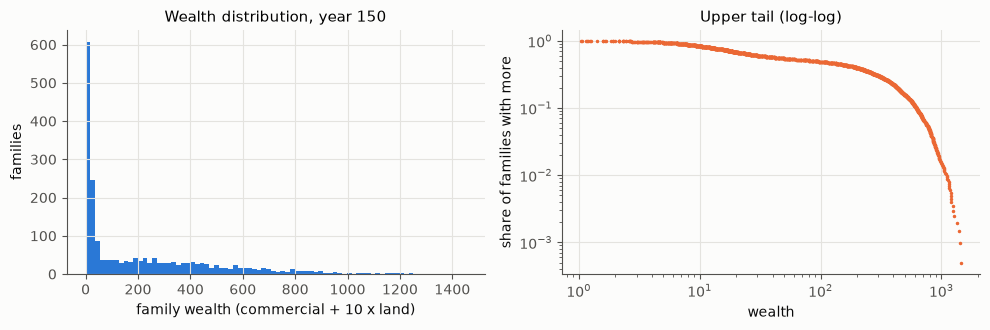

一年のお金の出入り(全家族の和、30 年目以降の平均):
  資産の所得                           38919.2
  労働の所得(生活保護を含む)                  16956.7
  うち生活保護の上乗せ                          6.2
  消費                              40081.7
  寄付(国の予算)                        17306.0
  相続人のない遺産                         3096.2


In [20]:
import exp3
ec3.gamble_mu(-10.0)
o_base, fams_base, P_base = ec3.simulate(T=150, seed=0, n_families=exp3.NF)
for t in (0, 10, 30, 60, 100, 149):
    print(f'{t:3d} 年: 家族 {o_base["n_families"][t]:5.0f} 人口 {o_base["pop"][t]:5.0f}  富の平均 {o_base["mean_w"][t]:6.1f} 中央 {o_base["median_w"][t]:6.1f}  '
          f'Gini {o_base["gini"][t]:.3f} 上位 10% {o_base["top10"][t]:.3f}  負の富 {o_base["neg"][t]:.3f}  '
          f'生活保護 {o_base["welfare"][t]:3.0f} 一家離散 {o_base["breakup"][t]:2.0f}')
w = ec3.snapshot(fams_base, P_base)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
axs[0].hist(w, bins=80, color=PAL[0]); axs[0].set(xlabel='family wealth (commercial + 10 x land)', ylabel='families', title='Wealth distribution, year 150')
x = np.sort(w[w > 1])[::-1]
axs[1].loglog(x, np.arange(1, len(x) + 1) / len(w), '.', color=PAL[1], ms=3)
axs[1].set(xlabel='wealth', ylabel='share of families with more', title='Upper tail (log-log)')
plt.tight_layout(); plt.show()
B = exp3.books(o_base)
print('一年のお金の出入り(全家族の和、30 年目以降の平均):')
for k, lab in (('income_asset', '資産の所得'), ('income_labor', '労働の所得(生活保護を含む)'), ('welfare_amt', 'うち生活保護の上乗せ'),
               ('consumption', '消費'), ('donation', '寄付(国の予算)'), ('escheat', '相続人のない遺産')):
    print(f'  {lab:28s} {B[k]:10.1f}')

富の分布は、右に長い裾を持つ(右の図は、上の裾を両対数で描いたもの)。Gini はおよそ 0.6 である。

帳簿を見ると、お金は**資産の所得と労働の所得から生まれ、消費と寄付で消える**。どこかの誰かの支出が、別の誰かの所得になる、という関係がない。労働の所得を払う雇い主もいなければ、消費を受け取る売り手もいない(農地の雇い人の賃金だけは、地主の収益から引かれるが、雇い人の所得にはならない)。ノート 1 の micro_economy で「予算が閉じていない」と指摘した(ノート 1 第 3 章)のと同じことが、ここでは設計として、もっとはっきり起きている。作者もそれを承知で、「望ましい性格は存在しない」と書いた。

だから、simbd の経済は「一つの経済」というより、**独立な家族のくじの集まり**である。家族どうしをつなぐのは、農地の割り当て(くじと順位)と、相続と結婚だけである。この性質は、第 6 章で、作者の実験の「変わるはずが変わらない」を説明するのに使う。

---

## 第 2 章 裾の重い運 ── 正規分布 + マイナスのレヴィ分布

### 2.1 作者の設計

電子本「経済」の章から。

> それぞれの運用方法による損益は、同じ確率分布を持ち、そのパラメータが異るだけである。その確率分布は、マイナスのレヴィ分布によって生成した乱数と、正規分布によって生成した乱数を足した数の分布になり、それがそれぞれの財産を 0 にする点以下になれば、0 にする点に切り上げるようにしている。
>
> 単純な正規分布でないのは、「不運がはなはだしいと全財産をすることがある」というのを実現するためである。現代の株式市場の変化は正規分布とみなすにはあまりにもはなはだしい下落がしばしばある。そういう激しい変動を表す一つの分布として提案できるのがコーシー分布やマイナスのレヴィ分布などの裾野の広い分布である。コーシー分布は正負両方に裾野が広いが、マイナスのレヴィ分布は負の方向にのみ裾野が広い。

式で書くと、元手 K の一年の損益 X は、

$$X = \max\left(N\!\left(\tfrac{\mu}{2}, \sigma^2\right) + \tfrac{\mu}{2} - L,\ -1.1K\right), \qquad L = \frac{\theta}{Z^2}$$

である。L がマイナスの側に効くレヴィ分布の部分で、θ が裾の大きさを決める。種類ごとの値(経験 10 年のとき)は、次のとおり。

| 種類 | μ(平均の目安) | θ(裾) | 古代での読み替え(作者) |
|---|---|---|---|
| 債券 | 0.06 × 1.1K | 0.01 | 貸家 |
| 株式 | 0.2 × 1.1K | 0.1 | 技能を使う商売(帳簿や計算ができる) |
| 大バクチ | 期待値がほぼ 0 になる μ の 0.9 倍 | 1 | 技能の要らない一時の仕事 |
| 死蔵 | 0 | 0.01 | 寝かせた財産(個人だけにかかる天災や盗難で失う) |
| 農地(一単位) | 0.3〜0.4 × 11 | 0.08 | 雇い人の賃金を引く |

θ には、熱心さが低いほど、憎まれが高いほど、上乗せがある(`stress`)。

### 2.2 レヴィ分布には平均がない

Z を標準正規分布とすると、L = θ/Z² は、レヴィ分布(位置 0、尺度 θ)に従う。その裾は

$$P(L > x) = P\left(|Z| < \sqrt{\theta/x}\right) \approx \sqrt{\frac{2\theta}{\pi x}} \qquad (x \gg \theta)$$

で、x^(−1/2) でしか減らない。だから、平均 E[L] = ∫ P(L > x) dx は**発散する**。正規分布の部分をいくら足しても、損失の平均は −∞ である。

作者は、損益を「財産を 0 にする点」(−1.1K)で切り上げた。これで平均ができる。切り捨てた損失の平均は、

$$E[\min(L, K')] = \int_0^{K'} P(L > x)\,dx \approx 2\sqrt{\frac{2\theta K'}{\pi}}$$

である(K' = 1.1K。K' ≫ θ のとき)。

### 2.3 simbd の実際の乱数は、一様乱数で作られていた

ここで、元のコードを読んでいて気づいたことがある。simbdp3 の `normal_levy_rand` は、一回ずつ引く道(`size=None`。経済の計算はこちらを使う)で、Z を正規乱数ではなく**一様乱数** U(0〜1)で作っている。

```python
def normal_levy_rand (mu, sigma, theta, cut, size=None):
    if size is None:
        z = random.random()                      # 一様乱数
        y = - mu/2 + theta * (1e100 if z == 0.0 else 1 / (z ** 2))
        ...
    z = np.random.normal(0, 1, size=size)        # 正規乱数
```

まとめて引く道と、大バクチの μ の表を作る `generate_normal_levy_csv.py` と、test_of_income_1.py は、正規乱数を使う。θ/U² の裾は

$$P(\theta/U^2 > x) = \sqrt{\theta/x}$$

で、形(x^(−1/2))は同じだが、大きさが √(π/2) ≈ 1.25 倍になる。切り捨てた平均は、ちょうど

$$E[\min(\theta/U^2, K')] = 2\sqrt{\theta K'} - \theta \qquad (K' \ge \theta)$$

になる(∫₀ᵃ K' du + ∫ₐ¹ θ/u² du、a = √(θ/K'))。数値で確かめる。

In [21]:
%%writefile -a exp3.py
def levy_table(N=2_000_000, seed=1):
    """切り捨てたレヴィの損失の期待値: 数値と式。"""
    rng = np.random.default_rng(seed)
    rows = []
    for th in (0.01, 0.1, 1.0):
        for K in (10, 100, 1000):
            z, u = rng.normal(size=N), rng.random(N)
            rows.append((th, K, np.minimum(th / z ** 2, K).mean(), 2 * np.sqrt(2 * th * K / np.pi),
                         np.minimum(th / u ** 2, K).mean(), 2 * np.sqrt(th * K) - th))
    return rows


def class_draw(kind, K, N, rng, z_kind='uniform', stress=0.35):
    """種類ごとの一年の損益(元手 K、経験 10 年)を N 回引く(simbdp3 の式をそのまま並べたもの)。
    stress は裾の太りの割合(0.7 × (1 − 熱心さ) + 0.3 × 憎まれ)。熱心さ 0.5・憎まれ 0 なら 0.35。"""
    cut = - K * 1.1
    if kind == 'bond':
        mu, sigma, th = - cut / 5 * 0.3, 0.01 * 10 * (- cut / 5 * 0.3) * 0.5, 0.01 * (1 + stress)
    elif kind == 'stock':
        mu, sigma, th = - cut / 5 * 1.0, 0.1 * 10 * (- cut / 5 * 1.0) * 0.5, 0.1 * (1 + stress)
    elif kind == 'gamble':
        mu, sigma, th = ec3.gamble_mu(cut) * 0.9, 10.0, 1.0 * (1 + stress)
    else:  # dead
        mu, sigma, th = 0.0, 0.1, 0.01 * (1 + stress)
    z = rng.random(N) if z_kind == 'uniform' else rng.normal(size=N)
    x = rng.normal(mu / 2, sigma, N) - (- mu / 2 + th / z ** 2)
    return np.maximum(x, cut), cut


def scale_table(N=1_000_000, seed=2):
    """元手の大きさと、収益率・全損の確率(simbdp3 の実際の乱数 θ/U²)。"""
    rng = np.random.default_rng(seed)
    rows = []
    for kind, Ks in (('bond', (10, 100, 1000)), ('stock', (10, 100, 300)), ('gamble', (5, 20, 50)), ('dead', (10, 100, 1000))):
        for K in Ks:
            x, cut = class_draw(kind, K, N, rng)
            rows.append((kind, K, x.mean() / K, np.mean(x <= cut)))
    return rows


def gamble_bias(N=2_000_000, seed=3):
    """大バクチの年の収益率: 表の作り方(θ/Z²)と、simbdp3 の実際(θ/U²)。"""
    rng = np.random.default_rng(seed)
    rows = []
    for g in (5, 10, 20, 50):
        r = []
        for zk in ('normal', 'uniform'):
            x, cut = class_draw('gamble', g, N, rng, zk, stress=0.0)   # 表は θ = 1(stress 0)で作られている
            r += [x.mean() / g, np.mean(x <= cut)]
        rows.append((g, *r))
    return rows

Appending to exp3.py


In [22]:
importlib.reload(exp3)
print('   θ      K   θ/Z² の数値   2√(2θK/π)   θ/U² の数値   2√(θK) − θ')
for th, K, mz, fz, mu_, fu in exp3.levy_table():
    print(f'{th:5.2f} {K:6d}   {mz:10.4f}   {fz:10.4f}   {mu_:10.4f}   {fu:10.4f}')

   θ      K   θ/Z² の数値   2√(2θK/π)   θ/U² の数値   2√(θK) − θ


 0.01     10       0.4955       0.5046       0.6213       0.6225
 0.01    100       1.5904       1.5958       1.9894       1.9900
 0.01   1000       5.1040       5.0463       6.3694       6.3146
 0.10     10       1.4974       1.5958       1.9001       1.9000
 0.10    100       4.9280       5.0463       6.2229       6.2246
 0.10   1000      15.8769      15.9577      19.7296      19.9000
 1.00     10       4.1288       5.0463       5.3218       5.3246
 1.00    100      15.0103      15.9577      19.0382      19.0000
 1.00   1000      49.4760      50.4627      62.3323      62.2456


θ/U² の式は(モンテカルロの誤差の範囲で)ぴったり合う。θ/Z² の近似 2√(2θK/π) は、K ≫ θ で合い、K が θ に近いと少し大きめに出る。

この「積分を計算したあとの代数」と、次の節の「元手あたりの損失が減る」ことを、Lean で確かめておく。

In [23]:
%%writefile -a breakup.lean
/-! ## 第 2 章 裾の重い損失と、規模に対する収穫逓増

simbdp3 のレヴィの部分 θ / U²(U は 0〜1 の一様乱数)を、元手 K で切り捨てる。
U < a = √(θ/K) のとき損失は K、U ≥ a のとき θ / U²。その期待値は
∫₀ᵃ K du + ∫ₐ¹ θ / u² du = K a + θ (1/a − 1) = 2√(θK) − θ。
ここでは、積分を計算したあとの代数の部分を確かめる。 -/

theorem truncated_loss_mean {θ K : ℝ} (hθ : 0 < θ) (hK : 0 < K) :
    K * Real.sqrt (θ / K) + θ * (1 / Real.sqrt (θ / K) - 1)
      = 2 * Real.sqrt (θ * K) - θ := by
  have hθK : 0 < θ / K := div_pos hθ hK
  have hs : 0 < Real.sqrt (θ / K) := Real.sqrt_pos.mpr hθK
  have hsq : Real.sqrt (θ / K) ^ 2 = θ / K := Real.sq_sqrt hθK.le
  have hm : Real.sqrt (θ * K) = K * Real.sqrt (θ / K) := by
    rw [show θ * K = K ^ 2 * (θ / K) by field_simp]
    rw [Real.sqrt_mul (by positivity), Real.sqrt_sq hK.le]
  have hK2 : K * Real.sqrt (θ / K) ^ 2 = θ := by rw [hsq]; field_simp
  rw [hm]
  field_simp
  linear_combination (-1 : ℝ) * hK2

/-- 元手あたりの損失 (2√(θK) − θ)/K は、x = θ/K とおくと 2√x − x になる。 -/
theorem loss_per_capital {θ K : ℝ} (hθ : 0 < θ) (hK : 0 < K) :
    (2 * Real.sqrt (θ * K) - θ) / K = 2 * Real.sqrt (θ / K) - θ / K := by
  have hm : Real.sqrt (θ * K) = K * Real.sqrt (θ / K) := by
    rw [show θ * K = K ^ 2 * (θ / K) by field_simp]
    rw [Real.sqrt_mul (by positivity), Real.sqrt_sq hK.le]
  rw [hm]
  field_simp

/-- 2√x − x は 0 ≤ x ≤ 1 で増える。だから、元手 K が大きい(x = θ/K が小さい)ほど、元手あたりの損失は小さい。 -/
theorem two_sqrt_sub_mono {x y : ℝ} (hx : 0 ≤ x) (hxy : x ≤ y) (hy : y ≤ 1) :
    2 * Real.sqrt x - x ≤ 2 * Real.sqrt y - y := by
  have sx := Real.sq_sqrt hx
  have sy := Real.sq_sqrt (hx.trans hxy)
  have h1 : Real.sqrt x ≤ Real.sqrt y := Real.sqrt_le_sqrt hxy
  have h2 : Real.sqrt y ≤ 1 := by
    rw [show (1 : ℝ) = Real.sqrt 1 by simp]; exact Real.sqrt_le_sqrt hy
  have h0 : 0 ≤ Real.sqrt x := Real.sqrt_nonneg x
  -- (2√y − y) − (2√x − x) = (√y − √x)(2 − √x − √y) ≥ 0
  nlinarith [mul_nonneg (sub_nonneg.mpr h1) (by linarith : (0 : ℝ) ≤ 2 - Real.sqrt x - Real.sqrt y)]

/-- 規模に対する収穫逓増: θ ≤ K₁ ≤ K₂ なら、元手 K₂ の元手あたりの損失は、元手 K₁ のそれ以下。 -/
theorem increasing_returns_to_scale {θ K₁ K₂ : ℝ} (hθ : 0 < θ) (h1 : θ ≤ K₁) (h12 : K₁ ≤ K₂) :
    (2 * Real.sqrt (θ * K₂) - θ) / K₂ ≤ (2 * Real.sqrt (θ * K₁) - θ) / K₁ := by
  have hK₁ : 0 < K₁ := hθ.trans_le h1
  have hK₂ : 0 < K₂ := hK₁.trans_le h12
  rw [loss_per_capital hθ hK₁, loss_per_capital hθ hK₂]
  apply two_sqrt_sub_mono (div_nonneg hθ.le hK₂.le)
  · exact div_le_div_of_nonneg_left hθ.le hK₁ h12
  · rw [div_le_one hK₁]; exact h1

Appending to breakup.lean


### 2.4 規模に対する収穫逓増

切り捨てた損失の平均 2√(θK') − θ を元手で割ると、x = θ/K' として 2√x − x になる。これは 0 ≤ x ≤ 1 で x とともに増える(Lean `two_sqrt_sub_mono`)。つまり、**元手が大きいほど(x が小さいほど)、元手あたりの損失は小さい**(`increasing_returns_to_scale`)。全損の確率 √(θ/K') も、1/√K で減る。

平均の収益 μ は元手に比例するのに、レヴィの損失は元手の平方根でしか伸びない。だから、**金持ちほど収益率が高い**。simbdp3 の実際の乱数で、元手ごとの収益率と全損の確率を見る(経験 10 年、熱心さ 0.5、憎まれ 0)。

In [24]:
print('種類       元手   年の収益率   全損の確率')
for kind, K, rate, ruin in exp3.scale_table():
    print(f'{kind:8s} {K:6d}   {rate:+9.4f}   {ruin:9.4f}')

種類       元手   年の収益率   全損の確率
bond         10     -0.0118      0.0339
bond        100     +0.0410      0.0107
bond       1000     +0.0582      0.0034
stock        10     -0.0331      0.1010
stock       100     +0.1369      0.0321
stock       300     +0.1717      0.0184
gamble        5     -0.3027      0.5719
gamble       20     -0.2042      0.2320
gamble       50     -0.1315      0.1439
dead         10     -0.0758      0.0351
dead        100     -0.0243      0.0111
dead       1000     -0.0077      0.0035


債券は、元手 10 では年 −1.2% の損だが、元手 1000 では +5.8% になる。株式は、元手 10 で −3.3%、元手 300 で +17%。全損の確率は、元手が 100 倍になると 1/10 になる。**同じ運用でも、貧しい者は損をし、金持ちは得をする**。運の分布の形だけから、そうなる。

これが、作者の見た「全財産を摩る可能性があるから、平均化されるかというとそんなことはなく、人々の資産が途方もなく大きくなっていく」の正体である。金持ちほど速く増えるので、分布は発散する。作者が入れた三つの止め方は、どれもこの発散を抑える仕掛けとして読める。

- **上限**(債券 1000、株式 300、大バクチ 50): 「国家予算を超えるほどのことは古代では難しく、そこまで大きくなると商売のネタがなくなる」。上限を超えた分は、収益率の低い次の種類に回る。
- **強い消費**: 資産の 6% を毎年消費する(収益率から一律に引くのと同じ)。
- **寄付**: 商業資産が多いほど、確率的に一部を寄付する(累進の資産税と同じ働き)。

**注: 規模の収穫逓増の、もう一つの道。** 作者は、simbd とは別の文脈で、富とともに収益率が上がる理由を、別のしくみに見ていた。「小口のものを集めて大口一本にまとめるのにコストがかかる。ってのは、逃げるのを引きとめにくいから、引きとめる(ための情報操作の)コストが高いということか？」(2009-07)、「高額預金の金利が高いのは資産家の人数が少なくて『騙す』コストが低いからかも」、「ヘッジファンドは、秘密主義であるがゆえに利益化できる何かはありえるかもしれないが、同時に、高額出資者の数が少ないゆえに効率よくだませるという側面もありえる」(2017)、「プライベートバンクなどが儲けられるのは、複雑な税制度があるがゆえという側面もあるはず」(2020)。これらは、**一人あたりの固定費**(引きとめ、情報の管理、複雑な税制を読み解く費用)の形をしている。費用が一人あたり c なら、元手あたりの費用は c/K で減り、大口ほど高い正味の収益率を払える。「表に情報を公開できないことが本質的で、そこを何とかすれば金銭化できる」(2009-07)は、情報の利得(レント)で、金を持つところに情報が集まる側面と重なる。simbd の道(切り捨てたレヴィの損失、1/√K)と固定費の道(1/K)は、富による収益率の差の縮み方で区別できる。大学の基金では、大きい基金ほど収益率が高く、専門家を雇う固定費で説明される(Piketty 2014)。情報を集める費用の規模の効果は、Kacperczyk、Nosal、Stevens(2019)が扱っている。

収益率が富とともに上がることは、現実の富の分布の研究でも、近年はっきり示されている。Fagereng ほか(2020)は、ノルウェーの全国民の税の記録から、富の多い者ほど、同じ種類の資産でも収益率が高いこと(収益率の異質性と持続性)を示した。Benhabib、Bisin、Zhu(2011)や Gabaix ほか(2016)は、収益率のばらつきが、富の分布の裾の厚さ(パレートの指数)と、格差の広がる速さを決めることを示した。simbd の運の設計は、作者が意図したかどうかはともかく、この性質を持っている。

### 2.5 大バクチは、設計より 4〜8 倍損になっていた

大バクチの μ は、表(`normal_levy_1.0.csv`)から引く。表は、「この μ なら、θ = 1、σ = 10 の正規 + レヴィの期待値がほぼ 0 になる」という値を、正規乱数で求めたものである。作者は、それを 0.9 倍して、「平均ではわずかにマイナス」の賭けにした(構想のログ、2021-01)。

> 「大バクチ」というのは、正規分布とマイナスのレヴィ分布の乱数を足したものといった感じなのかな。…レヴィ分布がどこまでもマイナスになりうるので、平均ではマイナスの大バクチになっている。ただ、少ない試行数だと、プラスで終るものも多い…みたいな。

ところが、simbdp3 の実際の乱数は、2.3 節のとおり一様乱数で作られている。

In [25]:
print('元手   θ/Z²(表の作り方): 年の収益率  全損   θ/U²(simbdp3 の実際): 年の収益率  全損')
for g, rz, pz, ru, pu in exp3.gamble_bias():
    print(f'{g:4d}          {rz:+8.3f}  {pz:6.3f}                  {ru:+8.3f}  {pu:6.3f}')

元手   θ/Z²(表の作り方): 年の収益率  全損   θ/U²(simbdp3 の実際): 年の収益率  全損


   5            -0.024   0.466                    -0.201   0.530
  10            -0.038   0.278                    -0.179   0.337
  20            -0.032   0.158                    -0.136   0.200
  50            -0.021   0.098                    -0.087   0.124


表の作り方(θ/Z²)なら、大バクチは年 −2〜−4% の「わずかにマイナス」の賭けである。simbdp3 の実際(θ/U²)では、年 −9〜−20% の、**はっきり損な賭け**になっている(熱心さの上乗せがない場合。上乗せがあれば、さらに損になる)。全損の確率も、3〜6 ポイント高い。

これは、おそらく意図しないずれである。ただ、simbd の結果(一家離散の数、富の分布)は、作者がこの乱数のもとで調整したものなので、ずれを「直す」と、調整が崩れる。第 4 章で、θ/Z² に替えたときの一家離散の数も見る。

---

## 第 3 章 資産配分の滝

### 3.1 作者の規則

家族の商業資産は、次の順に分けられる(元の `calc_asset_income`。ec3 の `allocate`)。

1. 農地を持つ家族は、農地の維持に要る分(0.04 × 農地²)と、農地の手入れに回す分を先に取る。
2. 残りのうち、**上昇志向**の割合(教化で少し穏やかにしたもの)を「攻め」に、残りを債券に回す。
3. 攻めの分のうち、商業の経験の割合(10 年で 100%)を株式に、残りを大バクチに回す。経験がなければ、攻めはすべて大バクチになる。
4. 株式が上限(300)を超えれば、超えた分を大バクチへ。大バクチが上限(50)を超えれば、債券へ。債券が上限(1000)を超えれば、**死蔵**へ。上限は家族の人数で少し広がる(一人増えるごとに 30%)。

作者は 2025 年に、これをこう要約している。

> 個人は最初は大バクチしか選べないが、経験を積むと商業資産や債券を選好するようになり、資産が増え過ぎると再び大バクチをやるようになり、それでも資産が増えると死蔵されることになる。

古代の読み替え(作者): 債券は貸家、株式は技能(帳簿や計算)を使う商売、大バクチは技能の要らない一時の仕事、死蔵は寝かせた財産。現代のサラリーマンは「上昇志向が小さく債券を中心に運用している」ようなもので、「いろいろな商売を債券・株式の比率で表現できる」(構想のログ、2021-01)。

上昇志向 0.5、経験 10 年、二人の家族で、商業資産ごとの配分を描く。

In [26]:
%%writefile -a exp3.py
def waterfall(props, ambition=0.5, stock_exp=10, members=2, land=0):
    """資産配分の滝: 商業資産ごとの、債券・株式・大バクチ・死蔵の額(乱数を使わない)。"""
    P = ec3.P()
    f = ec3.Family(members=[ec3.Member(age=40, leader=True) for _ in range(members)])
    f.ambition, f.education, f.stock_exp, f.land = ambition, 0.0, stock_exp, land
    return np.array([ec3.allocate(f, P, x)[3] for x in props])


def one_year(a):
    """一人の家族(農地なし、経験 0)が、元手 K を債券だけ・大バクチだけで運用したときの、一年の結果(生活保護・消費こみ)。"""
    K, mode, n, seed, labor = a
    P = ec3.P()
    random.seed(seed); np.random.seed(seed)
    out = []
    for i in range(n):
        m = ec3.Member(age=40, leader=True, prop=K, labor=labor)
        m.role = 'leader'
        m.education = 0.5
        m.ambition = 0.0 if mode == 'bond' else 1.0
        m.stock_exp = 0
        f = ec3.Family(members=[m])
        ec3.make_family_values(f)
        st = ec3.new_stat()
        ec3.year_income([f], P, st)
        out.append((m.prop, st['welfare']))
    x = np.array(out)
    return K, mode, labor, x[:, 0].mean() - K, np.mean(x[:, 0] <= 0), x[:, 1].mean(), np.percentile(x[:, 0], 90) - K

Appending to exp3.py


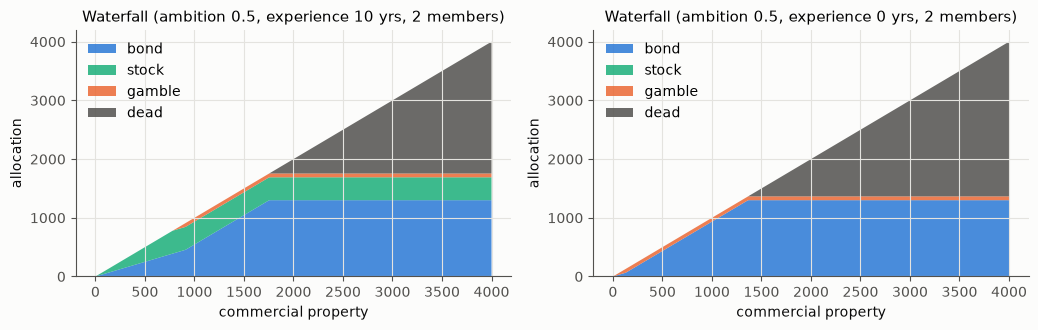

商業資産   債券    株式   大バクチ   死蔵
    10      5.0      5.0      0.0      0.0
   100     50.0     50.0      0.0      0.0
   500    250.0    250.0      0.0      0.0
  1000    545.0    390.0     65.0      0.0
  2000   1300.0    390.0     65.0    245.0
  4000   1300.0    390.0     65.0   2245.0


In [27]:
importlib.reload(exp3)
xs = np.linspace(0, 4000, 401)
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.4))
for ax, (amb, exp_) in zip(axs, ((0.5, 10), (0.5, 0))):
    A = exp3.waterfall(xs, ambition=amb, stock_exp=exp_)
    ax.stackplot(xs, A.T, labels=['bond', 'stock', 'gamble', 'dead'], colors=[PAL[0], PAL[2], PAL[1], INK2], alpha=0.85)
    ax.set(xlabel='commercial property', ylabel='allocation', title=f'Waterfall (ambition {amb}, experience {exp_} yrs, 2 members)')
    ax.legend(loc='upper left')
plt.tight_layout(); plt.show()
A = exp3.waterfall(np.array([10, 100, 500, 1000, 2000, 4000]), ambition=0.5, stock_exp=10)
print('商業資産   債券    株式   大バクチ   死蔵')
for x, a in zip((10, 100, 500, 1000, 2000, 4000), A):
    print(f'{x:6d}  ' + '  '.join(f'{v:7.1f}' for v in a))

経験のある家族(左)は、株式が上限に達するまでは「株式と債券」、株式が満ちると大バクチ、大バクチが満ちると債券だけが伸び、債券が満ちると死蔵が伸びる。経験のない家族(右)は、攻めの分がすべて大バクチになり、すぐ上限 50 に達する。

### 3.2 滝は、期待値の最適化か

第 2 章の表から、種類ごとの年の収益率は、おおよそ次の順になる(元手 100 前後)。

株式(+14%) > 債券(+4%) > 死蔵(−2%) > 大バクチ(−20%)

期待値や、対数の期待値(ケリー基準。Kelly 1956)を最大にする家族なら、株式を上限まで、次に債券、死蔵は最後で、**大バクチは選ばない**。作者の滝で、株式の上限を超えた分が債券より先に大バクチへ行くのは、期待値の最適化とは逆の順である。

では、大バクチに値打ちはないのか。経験のない一人の家族(農地なし)が、元手 K を債券だけ、または大バクチだけで運用したときの一年を、ec3 の一年の計算(労働の所得、生活保護、消費をすべて含む)で 4000 回ずつ比べる。労働力 1 の者と、障害や老いで労働力 0.3 の者で比べる。

In [28]:
R = exp3.pmap(exp3.one_year, [(K, m, 4000, 7, L) for L in (1.0, 0.3) for K in (5, 10, 20, 50) for m in ('bond', 'gamble')])
print('労働力  元手  運用      資産の変化の平均   資産 ≤ 0 の確率   生活保護の確率   上位 10% の変化')
for K, mode, L, d, p0, wf, p90 in R:
    print(f'{L:4.1f}  {K:5d}  {mode:7s}   {d:+12.3f}      {p0:10.3f}       {wf:10.3f}      {p90:+10.3f}')

労働力  元手  運用      資産の変化の平均   資産 ≤ 0 の確率   生活保護の確率   上位 10% の変化
 1.0      5  bond            +0.256           0.000            0.000          +0.541
 1.0      5  gamble          +0.498           0.000            0.000          +0.721
 1.0     10  bond            +0.035           0.000            0.000          +0.575
 1.0     10  gamble          -1.676           0.000            0.000          +4.642
 1.0     20  bond            -0.232           0.000            0.000          +0.642
 1.0     20  gamble          -4.139           0.000            0.000          +6.202
 1.0     50  bond            -1.157           0.021            0.000          +0.842
 1.0     50  gamble          -9.089           0.008            0.000          +7.685
 0.3      5  bond            -0.208           0.000            0.004          +0.181
 0.3      5  gamble          -0.119           0.000            0.000          +0.235
 0.3     10  bond            -0.413           0.029            0.006          +0.214
 0.

元手 10 以上では、大バクチは平均で債券に負ける(一年の資産の変化で 2〜9 ほど)。しかし、上位 10% の結果では、大バクチは +4.6〜+8.7、債券は +0.2〜+1.0 で、**大バクチだけが「跳躍」をもたらす**。大バクチの値打ちは、上の裾にしかない。

経済学には、「下に壁(破産の免責、生活保護)がある者には、ばらつきの大きい賭けが得になる」という議論がある(有限責任のもとでのリスク・シフティング。Jensen と Meckling 1976)。式では、結果 x を下限 c で切り捨てた max(x, c) が凸なので、平均が同じなら、ばらついた賭けのほうが切り捨て後の期待値が大きい(イェンセンの不等式)。これを Lean で確かめておく(`floor_convexity`)。

ところが、上の表では、**生活保護の床はほとんど効いていない**(生活保護を受ける確率は 0〜0.6%)。労働力 0.3 の者でも、労働の所得と最低の消費の差が小さく、大バクチの損(元手の 1.1 倍まで)が、そのまま資産の減りになる。だから、この模型では「床があるから貧しい者は大バクチをする」という合理化は、ほぼ働いていない。大バクチは、上昇志向の高い者と経験のない者が、規則として選ぶものである。

作者自身、構想のログでこう迷っていた(2021-01)。

> 宝くじみたいにはずれの可能性が高いような危険なバクチは、金持ちや経験を積んだ商人はそもそもしないんじゃないか？ 債券と株式と大バクチがあって、大バクチは死んでもいいと思ってる貧乏な商人しかせず、普通は債券と株式のどちらを選好するかだけが商人の課題みたいな感じだと思うのだが…。

この迷いへの答えは、「期待値では大バクチは選ばれない。選ばれるとすれば、上の裾(跳躍)に値打ちを置く選好か、下の壁が強く効く者だけ」である。simbd では、その選好を「上昇志向」という一つの数で表した、と読める。ノート I(必需品と贅沢品の宇宙的独立関係)で見た、**探索**(贅沢品)の値打ちが上の裾にあることと、同じ形である。

In [29]:
%%writefile -a breakup.lean
/-! ## 第 3 章 下に壁があると、分散の大きい賭けが得になる

結果 x を下限 c で切り捨てる(生活保護・ロスカット)。平均が同じなら、ばらついた賭けの、切り捨てた後の期待値は、
確実に平均を得るときの値以上になる(イェンセンの不等式。max(·, c) は凸)。 -/

theorem floor_convexity {κ : Type*} (S : Finset κ) (p x : κ → ℝ) (hp : ∀ k ∈ S, 0 ≤ p k)
    (h1 : ∑ k ∈ S, p k = 1) (c : ℝ) :
    max (∑ k ∈ S, p k * x k) c ≤ ∑ k ∈ S, p k * max (x k) c := by
  apply max_le
  · exact sum_le_sum fun k hk => mul_le_mul_of_nonneg_left (le_max_left _ _) (hp k hk)
  · calc c = ∑ k ∈ S, p k * c := by rw [← sum_mul, h1, one_mul]
      _ ≤ ∑ k ∈ S, p k * max (x k) c :=
        sum_le_sum fun k hk => mul_le_mul_of_nonneg_left (le_max_right _ _) (hp k hk)

Appending to breakup.lean


### 3.3 種類ごとの切り捨ては、有限責任である

作者は 2021 年 2 月に、構想のログにこう書いた。

> 「債券」「株式」「大バクチ」とそれぞれ cut を独自に持っていて、マイナスのレヴィ分布がマイナス側に大きく振れても、それぞれの種別で 0 になるだけで、他は分散投資的に守られるようになっていたが、その根拠は何かという問題が気になる。「農地」も分散投資的にしたが、それがリアルなのかという問題がある。
>
> ただ、分散投資がどこかで有効になるべきだという考えも私の中にはあって、どう折り合いをつけるべきか迷っている。

種類 i の損益 Xᵢ を、その種類の元手で切り捨てる(cᵢ = −1.1Kᵢ)。種類ごとに切り捨てた和と、まとめて切り捨てた値を比べると、

$$\sum_i \max(X_i, c_i) \;\ge\; \max\Big(\sum_i X_i,\ \sum_i c_i\Big)$$

がいつも成り立つ(Lean `limited_liability`)。各項 max(Xᵢ, cᵢ) は Xᵢ 以上で、cᵢ 以上だからである。期待値でも同じ(`limited_liability_expect`)。

つまり、損失の上限を事業ごとに分けることには、**それだけで値打ちがある**。これは、平均・分散の理論(Markowitz 1952)の「分散投資は分散を減らす」とは別の、**有限責任のオプションの値打ち**(Merton 1974。株式は会社の資産に対するコール・オプション)である。現実の世界で事業ごとに会社を分ける(子会社、特別目的会社)のは、まさにこの値打ちのためである。

だから、作者の「分散投資の根拠」への答えは、「simbd の分散投資の効果は、分散を減らすことからではなく、損失の上限を種類ごとに分けることから来る。そして、それは現実にもある制度(有限責任)である」となる。ただし、農地を一単位ずつ切り捨てる設計は、一単位の損失が単位の値打ち(10)を超えて 11 まで行くので、第 4 章で見るとおり、**農地の多い家族ほど大きく負ける**道を作ってもいる。

In [30]:
%%writefile -a breakup.lean
/-! ## 第 3 章 有限責任としての切り捨て

資産の種類 i ごとに、損益 Xᵢ を下限 cᵢ で切り捨てる(その種類の元手より多くは失わない)。
種類ごとに切り捨てた和は、まとめて切り捨てた値以上になる。
だから、損失の上限を事業ごとに分けることには、それだけで値打ちがある(分散投資の一つの根拠)。 -/

theorem limited_liability {ι : Type*} (s : Finset ι) (X c : ι → ℝ) :
    max (∑ i ∈ s, X i) (∑ i ∈ s, c i) ≤ ∑ i ∈ s, max (X i) (c i) :=
  max_le (sum_le_sum fun _ _ => le_max_left _ _) (sum_le_sum fun _ _ => le_max_right _ _)

/-- 期待値でも同じ: 結果 k が確率 p k で起きるとき、種類ごとの切り捨ての期待値は、まとめた切り捨ての期待値以上。 -/
theorem limited_liability_expect {κ ι : Type*} (S : Finset κ) (p : κ → ℝ) (hp : ∀ k ∈ S, 0 ≤ p k)
    (s : Finset ι) (X : κ → ι → ℝ) (c : ι → ℝ) :
    ∑ k ∈ S, p k * max (∑ i ∈ s, X k i) (∑ i ∈ s, c i)
      ≤ ∑ k ∈ S, p k * ∑ i ∈ s, max (X k i) (c i) :=
  sum_le_sum fun k hk => mul_le_mul_of_nonneg_left (limited_liability s (X k) c) (hp k hk)

Appending to breakup.lean


---

## 第 4 章 誰が一家離散するのか

### 4.1 安全網と、作者の調整

1.4 節で見たとおり、simbd の家族には三層の安全網がある。資産の損失のロスカット(−27.5 × 労働力)、生活保護(最低の消費)、借金の余裕(−20 × 人数)。それを割り込むと一家離散して、土地と商業資産をすべて失い、15 歳以上の子は独立する(夫婦と 15 歳未満の子は一緒にいられる)。

作者は、この安全網を、実験を見ながら調整した(構想のログ、2021-10)。

> 本来、一家離散はそんなに出ない設計にしたはずだった。資産は種類ごとにそれが 0 になることはありうるが、マイナスにはならないし、労働収入を超える消費もないはずだったから。なぜ、こんなに一家離散が起きるのか？
>
> (借金の余裕と生活保護を入れると)これらはある意味うまく行き過ぎて、一家離散がゼロになる。それはそれで避けたいので、資産収入評価のときに資産額を割り込めるよう、個々の資産収入の cut に倍率 1.1 を設定し、全体として資産収入のマイナス(--whole-cut-slack)を 27.5 まで受け容れるようにした。
>
> 全体として資産収入のマイナス(--whole-cut-slack)を 27.5 に選んだのは実験結果を見て。まったく一家離散がないのもおかしいと考えたが、それは必要最低限で、ただ、一家離散者が悪目立ちしすぎることもないようにしよう…として、27.5 を選んだ。

この章では、(1) なぜ 27.5 で「必要最低限」になるのかを式で示し、(2) 誰が一家離散するのかを調べ、(3) 一家離散を減らす案を比べ、(4) 経済的な憎しみと教化の効き方を見る。

### 4.2 一家離散が起きうる条件(帳簿の式)

年の初めの資産(商業資産 + 10 × 農地)が正の家族を考える。労働力の和を L、人数を n とする。

- 資産の所得の損失は、ロスカットで「年の初めの資産 + 27.5 L」まで。
- 労働の所得は、少なくとも 5L(基準の消費 3 の 5/3 倍。仕事運が最低でも)。
- 消費は、所得が少なければ 3L(資産からの消費は、資産が負になるなら「地主の倹約」で止まる)。

だから、年末の資産は、

$$\text{年末の資産} \;\ge\; -27.5L + 5L - 3L = -25.5L$$

を下回らない。一家離散の線は −20n なので、**一家離散が起きうるのは 25.5L > 20n、つまり L/n > 0.78 の家族だけ**である。子ども(労働力 0.1)がいれば L/n は下がる。夫婦と子ども一人なら (2 + 0.1)/3 = 0.7 で、一家離散は**構造的に起きない**。起きうるのは、子どものいない働き手だけの家族、とくに一人暮らし(L/n = 1)である。

同じ式から、ロスカット w と借金の余裕 d について、**一人暮らしで一家離散が起きうるのは w − 2 > d のときだけ**とわかる。基準の d = 20 なら、w > 22 である。作者の 27.5 は、この臨界値 22 のすぐ上にある(労働の所得の平均は 6.5L ほどなので、平均的には w > 23.5)。「まったく一家離散がないのもおかしいが、悪目立ちしすぎないように」という調整は、**臨界値をわずかに超えるところ**を選んだことになる。

安全網の強さを振って確かめる(1000 家族で始め、150 年、最後の 120 年、12 シード。一家離散は 1000 家族・年あたり)。

In [31]:
%%writefile -a exp3.py
KEYS = ('breakup', 'welfare', 'gini', 'mean_w', 'median_w', 'neg', 'donation', 'debt_relief', 'land_grant', 'n_families', 'hated')


def hill(w, frac=0.05):
    """上の裾のパレートの指数(ヒルの推定量。上位 frac の家族で)。小さいほど裾が重い。"""
    x = np.sort(w[w > 0])[::-1]
    k = max(int(len(x) * frac), 5)
    return float(k / np.sum(np.log(x[:k] / x[k])))


def run_stats(a):
    """150 年まわし、最後の 120 年の統計を返す(どの章の表も、この一つの関数を使う)。"""
    kw, seed = a
    kw = dict(dict(n_families=NF), **kw)
    o, fams, P = ec3.simulate(T=T, seed=seed, **kw)
    keys = KEYS + ('top10', 'dis_loss', 'dis_n', 'protect', 'relief_paid', 'income_labor', 'income_asset',
                   'consumption', 'wages', 'breakup_multi', 'rescue')
    r = {k: float(o[k][BURN:].mean()) for k in keys}
    r['donation_pc'] = float((o['donation'][BURN:] / o['pop'][BURN:]).mean())    # 一人あたりの寄付(国の予算)
    r['pop'] = float(o['pop'][BURN:].mean())
    fy = o['n_families'][BURN:].sum()
    r['breakup_rate'] = 1000 * o['breakup'][BURN:].sum() / fy                     # 1000 家族・年あたり
    r['multi_rate'] = 1000 * o['breakup_multi'][BURN:].sum() / fy                 # うち、一人暮らしでない家族
    r['land_income'] = float(o['inc_land'][BURN:].mean())
    r['hill'] = hill(ec3.snapshot(fams, P))
    return r


CACHE_FILE = 'exp3_cache.pkl'      # このノートの実行の中で、同じ計算を使い回すための覚え書き(ノートの初めに消す)


def cached_stats(args):
    """(設定, 種) の列の統計。前に同じ計算をしていれば、覚え書きから返す(ec3.py の中身が変われば別のもの)。"""
    import pickle, hashlib
    h = hashlib.sha256(open(ec3.__file__, 'rb').read()).hexdigest()[:16]
    cache = pickle.load(open(CACHE_FILE, 'rb')) if os.path.exists(CACHE_FILE) else {}
    keys = [(h, NF, T, BURN, repr(sorted(kw.items())), s) for kw, s in args]
    todo = [i for i, k in enumerate(keys) if k not in cache]
    if todo:
        for i, r in zip(todo, pmap(run_stats, [args[i] for i in todo])):
            cache[keys[i]] = r
        pickle.dump(cache, open(CACHE_FILE, 'wb'))
    return [cache[k] for k in keys], len(args) - len(todo)


def table(rows, seeds=SEEDS):
    """設定ごとに、シードの平均と、一家離散の率の標準誤差。"""
    args = [(kw, s) for lab, kw in rows for s in seeds]
    R, hit = cached_stats(args)
    if hit:
        print(f'(覚え書きから {hit} 本、新しく計算 {len(args) - hit} 本)')
    out, n = [], len(seeds)
    for i, (lab, kw) in enumerate(rows):
        rs = R[i * n:(i + 1) * n]
        m = {k: float(np.mean([r[k] for r in rs])) for k in rs[0]}
        m['se'] = float(np.std([r['breakup_rate'] for r in rs]) / np.sqrt(n))
        out.append((lab, m))
    return out


def who(seed):
    """一家離散した家族の記録と、人口全体の構成。"""
    log = []
    o, fams, P = ec3.simulate(T=T, seed=seed, n_families=NF, log=log)
    lv = P.prop_value_of_land
    base = dict(single=np.mean([len(f.members) == 1 for f in fams]),
                single_land=np.mean([len(f.members) == 1 and sum(m.land for m in f.members) > 0 for f in fams]),
                landowner=np.mean([sum(m.land for m in f.members) > 0 for f in fams]),
                landowner_negprop=np.mean([sum(m.prop for m in f.members) < 0 for f in fams
                                           if sum(m.land for m in f.members) > 0]))
    return log, base


def landbuy(seed, years=T):
    """農地の割り当てで農地を増やされた者が、代金を払えたか。"""
    P = replace(ec3.P(), n_families=NF)
    fams, rng = ec3.init_families(P, seed)
    rec = []
    orig = ec3.keep_merchant_peasant_ratio

    def wrapped(people, P_):
        before = [(p.prop, p.land) for p in people]
        orig(people, P_)
        for p, (b, l) in zip(people, before):
            if p.land > l:
                rec.append((b, l, p.prop, p.land))
    for t in range(years):
        ec3.keep_merchant_peasant_ratio = wrapped if t >= BURN else orig
        try:
            ec3.year(fams, P, rng)
        finally:
            ec3.keep_merchant_peasant_ratio = orig
    return np.array(rec)

Appending to exp3.py


In [32]:
importlib.reload(exp3)
ROWS_NET = [('基準(ロスカット 27.5、余裕 20)', {}),
            ('作者の調整の前(ロスカット 0、切り捨て 1.0)', dict(whole_cut_slack=0.0, cut_slack_rate=1.0)),
            ('ロスカット 10', dict(whole_cut_slack=10.0)),
            ('ロスカット 20', dict(whole_cut_slack=20.0)),
            ('ロスカット 40', dict(whole_cut_slack=40.0)),
            ('借金の余裕 10', dict(debt_slack=10.0)),
            ('借金の余裕 30', dict(debt_slack=30.0)),
            ('地主の倹約なし', dict(no_landlord_thrift=True)),
            ('裾を 10 倍(--prop-theta-mag=10)', dict(prop_theta_mag=10.0)),
            ('レヴィを θ/Z²(表の作り方)', dict(levy_z='normal'))]
ROWS_FIX = [('(a) 借金の余裕を 40 に', dict(debt_slack=40.0)),
            ('(b) 頼母子講(貧しい家族で資産の所得を平均)', dict(pool_luck=True)),
            ('(c) 家族の有限責任(負の富を免責)', dict(family_liability=True)),
            ('(d) 口分田(払えない農地の代金を払い下げ)', dict(land_grant=True))]
ROWS_HATE = [('憎まれの効き 0', dict(hated_mag=0.0)),
             ('憎まれの効き 3', dict(hated_mag=3.0)),
             ('憎まれの効き 10', dict(hated_mag=10.0)),
             ('宥めなし', dict(soothe=False)),
             ('宥めなし・効き 10', dict(soothe=False, hated_mag=10.0)),
             ('教化が低い(0〜0.4)', dict(education_range=(0.0, 0.4))),
             ('教化が高い(0.6〜1)', dict(education_range=(0.6, 1.0)))]
TAB4 = dict(exp3.table(ROWS_NET + ROWS_FIX + ROWS_HATE))


def show(rows, extra=()):
    for lab, kw in rows:
        m = TAB4[lab]
        s = (f'  {lab:34s} 一家離散 {m["breakup_rate"]:.4f}±{m["se"]:.4f}  生活保護 {m["welfare"]:4.1f}/年  '
             f'Gini {m["gini"]:.3f}  平均 {m["mean_w"]:6.1f}  中央 {m["median_w"]:6.1f}')
        for k, f in extra:
            s += f'  {k} {m[f]:.4g}' if isinstance(f, str) else ''
        print(s)


show(ROWS_NET)

  基準(ロスカット 27.5、余裕 20)               一家離散 0.0148±0.0021  生活保護  4.1/年  Gini 0.615  平均  231.7  中央  104.3
  作者の調整の前(ロスカット 0、切り捨て 1.0)          一家離散 0.0000±0.0000  生活保護  6.5/年  Gini 0.643  平均  175.5  中央   61.1
  ロスカット 10                           一家離散 0.0000±0.0000  生活保護  4.0/年  Gini 0.614  平均  231.7  中央  104.1
  ロスカット 20                           一家離散 0.0000±0.0000  生活保護  4.0/年  Gini 0.615  平均  231.1  中央  103.3
  ロスカット 40                           一家離散 0.0188±0.0026  生活保護  4.2/年  Gini 0.615  平均  231.2  中央  103.5
  借金の余裕 10                           一家離散 0.2900±0.0121  生活保護  4.2/年  Gini 0.616  平均  231.1  中央  103.7
  借金の余裕 30                           一家離散 0.0000±0.0000  生活保護  4.1/年  Gini 0.616  平均  231.0  中央  103.1
  地主の倹約なし                            一家離散 0.0152±0.0019  生活保護  4.0/年  Gini 0.615  平均  231.3  中央  103.7
  裾を 10 倍(--prop-theta-mag=10)       一家離散 0.0224±0.0024  生活保護  6.7/年  Gini 0.596  平均  112.2  中央   59.3
  レヴィを θ/Z²(表の作り方)                   一家離散 0.0022±0.0010  生活保護  2.1/年  Gin

式の予想どおりである。

- ロスカットが 0・10・20 なら、一家離散は**一度も起きない**(w − 2 ≤ 20)。27.5 で 1000 家族・年あたり約 0.015 件、40 で約 0.019 件。
- 借金の余裕を 30 に広げても 0 件(w − 2 = 25.5 < 30)。逆に 10 に狭めると、一家離散は約 20 倍になる(L/n > 10/25.5 = 0.39 の家族、つまり子どもの少ない夫婦にも起きうるようになる)。
- 作者の調整の前(ロスカット 0、切り捨て 1.0)も 0 件。作者の「うまく行き過ぎて、一家離散がゼロになる」と合う。
- 裾を 10 倍にすると、一家離散は 1.5 倍、富の平均は半分になる。作者が 2021-01 に試して「わりと貧乏な者が増え、分布としては満足いく形にはなるが、農地を持つ者が有利になりすぎる」と書いた設定である。
- レヴィを表の作り方(θ/Z²)に替えると、一家離散は 1/7 ほどに減り、富は増える。第 2.5 節のずれは、一家離散の数を約 7 倍にしていたことになる。作者の 27.5 の調整は、このずれのもとでなされた。

基準でも、一家離散は 1000 家族・年あたり 0.015 件、つまり 1000 家族の国で 70 年に 1 件ほどの、**まれな出来事**である。作者の調整のあとの simbd では、一家離散は分布の裾の、さらに先の出来事になっている。

### 4.3 誰が一家離散するのか

ec3 で、一家離散した家族を記録する。

In [33]:
W4 = exp3.pmap(exp3.who, list(exp3.SEEDS))
L4 = [l for r in W4 for l in r[0]]
n4 = np.array([l['n'] for l in L4]); land4 = np.array([l['land'] for l in L4])
start4 = np.array([l['start'] for l in L4]); prop4 = start4 - 10 * land4
final4 = np.array([l['start'] + l['i1'] + l['i2'] - l['c'] for l in L4])
print(f'一家離散 {len(L4)} 件(12 シード)')
print(f'  一人暮らしの割合 {np.mean(n4 == 1):.2f}   農地を持つ割合 {np.mean(land4 > 0):.2f}   農地の数の分布 {dict(zip(*np.unique(land4, return_counts=True)))}')
print(f'  損失のうち農地から来た割合 {np.mean([l["inc"][4] / min(sum(l["inc"]), -1e-9) for l in L4]):.2f}   商業の経験 10 年未満 {np.mean([l["stock_exp"] < 10 for l in L4]):.2f}')
print(f'  年の初めの資産 {np.percentile(start4, [0, 50, 100]).round(1)}   うち商業資産 {np.percentile(prop4, [0, 50, 100]).round(1)}')
print(f'  年末の資産(寄付の前) {np.percentile(final4, [0, 50, 100]).round(1)}   (式の底は −25.5、線は −20)')
base4 = {k: np.mean([r[1][k] for r in W4]) for k in W4[0][1]}
print(f'人口全体: 一人暮らし {base4["single"]:.2f}、一人暮らしの地主 {base4["single_land"]:.2f}、地主 {base4["landowner"]:.2f}、'
      f'地主のうち商業資産が負 {base4["landowner_negprop"]:.2f}')

一家離散 56 件(12 シード)
  一人暮らしの割合 1.00   農地を持つ割合 1.00   農地の数の分布 {np.int64(3): np.int64(11), np.int64(4): np.int64(17), np.int64(5): np.int64(13), np.int64(6): np.int64(7), np.int64(7): np.int64(6), np.int64(8): np.int64(2)}
  損失のうち農地から来た割合 1.00   商業の経験 10 年未満 0.98
  年の初めの資産 [ 0.7  4.9 19.5]   うち商業資産 [-78.5 -37.9 -20.5]
  年末の資産(寄付の前) [-24.9 -22.7 -20.1]   (式の底は −25.5、線は −20)
人口全体: 一人暮らし 0.36、一人暮らしの地主 0.32、地主 0.86、地主のうち商業資産が負 0.34


答えは、はっきりしている。**一家離散したのは、全員が一人暮らしの小地主**(農地 3〜8 単位)で、損失は全部、農地の不作から来ている。そして、年の初めの資産は正だが小さく(数〜20 ほど)、その中身は「**農地の値打ち 30〜80 と、商業資産の借金 −20〜−70**」である。借金を、農地の値打ちで埋めていた家族である。年末の資産は、式の底 −25.5 と線 −20 のあいだに落ちている。

なぜ、一人暮らしの小地主が借金を抱えているのか。

### 4.4 くじで割り当てられ、借金で買わされる農地

農地は、市場で売り買いされない。毎年、農商比率(68 : 20)と農地の数の分布の形(負の二項分布)を保つように、**くじつきの資産の順位**で、一単位ずつ増減させられる(第 1.4 節)。代金は一単位 10 で、商業資産から払う。払えなくても、払わされる。作者は電子本でこう書いている。

> 基本、農地は、人口に見合うように新田開発や効率の悪い土地の破棄が行われると考え、人口に対し一定の農地があるとする。…そして、農民は足りなければ補充され、多過ぎれば、商業に戻されると考える。
>
> このシステムでは、土地の売り買いには言ってみればクジに当たらないとできないため、回転売買ができないようになってどこまでも稼ぐことは防がれている。

農地を増やされた者が、代金を払えたかを見る。

In [34]:
B4 = exp3.landbuy(0)
yrs = exp3.T - exp3.BURN
print(f'農地を増やされた者: 年に {len(B4) / yrs:.0f} 人')
print(f'  代金を払えなかった(元の商業資産 < 代金)割合 {np.mean(B4[:, 0] < 10 * (B4[:, 3] - B4[:, 1])):.2f}')
print(f'  割り当ての後に商業資産が負になった割合     {np.mean(B4[:, 2] < 0):.2f}')
print(f'  農地 0 の商人から、くじで農民にされた割合   {np.mean(B4[:, 1] == 0):.2f}')

農地を増やされた者: 年に 197 人
  代金を払えなかった(元の商業資産 < 代金)割合 0.82
  割り当ての後に商業資産が負になった割合     0.82
  農地 0 の商人から、くじで農民にされた割合   0.22


農地を増やされた者の **8 割は、代金を払えないまま農地を受け取り、商業資産が負になる**。2 割強は、農地を持たない商人が、くじで農民にされた者である。独立したばかりの若者(資産 0)も、ここに入る。

これで、一家離散の道筋がつながる。

1. 資産のない者が、くじで農地を割り当てられ、代金の分だけ商業資産が負になる(借金で農地を買わされる)。
2. 農地の値打ちが借金を埋めているので、資産の合計は正で、安全網の外に見える。商業資産が負なので、資産の運用(債券や株式)もできず、所得は農地と労働だけになる。
3. 農地は一単位ずつ、元手 11(値打ち 10 の 1.1 倍)まで損をしうる。数単位が同じ年に不作になると、資産の合計が −25.5 近くまで落ちる。
4. 一人暮らしなら、それが一家離散の線 −20 を割り込む。子どもがいれば、線が下がるので割り込まない。

つまり、simbd で一家離散するのは、**資産のないまま土地を背負わされ、子のいない、独り身の小農**である。作者が「一番気になっている」と書いた一家離散は、運の悪い商人の破産ではなく、**農地の割り当ての制度**から生まれていた。古代の律令制の班田収授(口分田)は、田を「割り当てる」制度だったが、代金を取らなかった。simbd の農地は、割り当てでありながら代金を取る。そこに、一家離散の種がある。

### 4.5 元の simbd 全体では: 死者の一家離散

ec3 は、simbd の経済の一年の計算を元と同じにしたが、人口の動きは簡単なものに置き換えた。そこで、元の simbd 全体(第 1 章で取ってきた版を、そのまま)も、小さな人口(2500 人)で 100 年、四つの乱数の種で並列に回して比べる。今の numpy で止まる二か所(`np.int`、longdouble の確率)と、乱数の種の固定(と、文字列のハッシュの固定)、毎月の図の描画を止めること(`--no-view` でも描いていて、計算の約 6 割を占める)、記録のための print だけを、文字列の置き換えで足す。差分は次のとおり。計算は変えない。

In [35]:
%%writefile -a orig3.py
# 元の simbd 全体(simbdp3.py)を、別のディレクトリに写して走らせる。今の numpy で止まる二か所と、
# 一家離散した家族と地主の借金を記録する print だけを、文字列の置き換えで足す(差分は FULL_PATCHES)。
FULL_PATCHES = {
    'simbdp3.py': [          # 元は乱数の種を固定しない。再現できるよう、初期化の前に種を固定する
        ("        initialize(economy)\n",
         "        _sd = int(__import__('os').environ.get('SIMBD_SEED', '1')); random.seed(_sd); np.random.seed(_sd)\n"
         "        initialize(economy)\n"),
                             # 毎月の図の描画を止める(--no-view でも描いていて、計算の約 6 割を占める。計算は変わらない)
        ("        print(\"\\nPlotting...\", flush=True)\n        eplot.plot(economy)\n",
         "        print(\"\\nPlotting...\", flush=True)\n        if not ARGS.no_view:\n            eplot.plot(economy)\n")],
    'simbdp3/common.py': [   # 今の numpy は、longdouble の確率を np.random.choice に渡すと止まる
        ("    return np.random.choice(a, size, replace=replace, p=p)\n",
         "    if p is not None:\n        p = np.asarray(p, dtype=np.float64); p = p / p.sum()\n"
         "    return np.random.choice(a, size, replace=replace, p=p)\n")],
    'simbdp3/moving.py': [   # np.int は今の numpy にない(二か所)
        ("dtype=np.int)", "dtype=int)")],
    'simbdp3/economy.py': [  # 記録のための print(計算は変えない)
        ("            # 一家離散\n            n_b += 1\n",
         "            # 一家離散\n            n_b += 1\n"
         "            print('BREAKUP_REC', len(f.members), f.land, tfprop, labor, i1, i2,\n"
         "                  sum(1 for p in f.members.values() if p.is_dead()), f.prop, flush=True)\n"),
        ("    keep_merchant_peasant_ratio(economy)\n",
         "    keep_merchant_peasant_ratio(economy)\n"
         "    lo = [p for p in economy.people.values() if not p.is_dead() and p.land > 0]\n"
         "    print('LANDNEG', len(lo), sum(1 for p in lo if p.prop < 0), flush=True)\n")],
}


# 第 8 章の提案「帳簿の時計を一つにする」: 資産の所得を、一年の平均の資産ではなく、年末の資産で計算する(一行)
ONE_CLOCK = {'simbdp3/economy.py': [
    ("        f.prop = sum([np.mean(p.mlog['prop']) for p in f.members.values()])\n",
     "        f.prop = sum([p.prop for p in f.members.values()])\n")]}


def run_full_simbd(rundir, population='1000,1000,500', months=1200, seed=1, extra=None):
    """元の simbd 全体を走らせ、年ごとの一家離散・生活保護・地主の借金の記録を返す(数分かかる)。
    extra は、FULL_PATCHES に足す差分({ファイル: [(元, 新), ...]})。"""
    import shutil, subprocess
    os.makedirs(os.path.join(rundir, 'simbdp3'), exist_ok=True)
    for n in SHA256:
        if n.startswith('simbdp3') or n == 'normal_levy_1.0.csv':
            src = fetch(n).replace('\r\n', '\n')      # 元のファイルの改行は CRLF。差分を当てるため LF にそろえる
            for a, b in FULL_PATCHES.get(n, []) + (extra or {}).get(n, []):
                assert src.count(a) >= 1, (n, a)      # 見つからなければ止める(np.int は二か所。すべて置き換える)
                src = src.replace(a, b)
            open(os.path.join(rundir, n), 'w').write(src)
    # 集合や辞書の並び順も固定する(文字列のハッシュの乱数化を切る)
    env = dict(os.environ, MPLBACKEND='Agg', SIMBD_SEED=str(seed), PYTHONHASHSEED='0')
    r = subprocess.run([sys.executable, 'simbdp3.py', '--no-view', '-p', population, '-t', str(months)],
                       cwd=rundir, capture_output=True, text=True, env=env)
    out = r.stdout
    if r.returncode != 0:
        raise RuntimeError(r.stderr[-2000:])
    rec = dict(breakup=[], welfare=[], landneg=[], breakup_rec=[], population=[])
    for line in out.splitlines():
        w = line.split()
        if line.startswith('Breakup of Family:'):
            rec['breakup'].append(int(w[3]))
        elif line.startswith('Welfare:'):
            rec['welfare'].append(int(w[1]))
        elif line.startswith('LANDNEG'):
            rec['landneg'].append((int(w[1]), int(w[2])))
        elif line.startswith('BREAKUP_REC'):
            rec['breakup_rec'].append(tuple(float(x) for x in w[1:]))
        elif line.startswith('District Population:'):
            rec['population'].append(sum(int(x) for x in line.split('[')[1].split(']')[0].split(',')))
    return rec


def run_full_many(rundir, seeds=(1, 2, 3, 4), **kw):
    """元の simbd 全体を、いくつかの種で並列に走らせる(一つ数分。種ごとに別のディレクトリ)。"""
    from concurrent.futures import ThreadPoolExecutor
    for n in SHA256:                      # 先に一度、全部を取ってくる
        fetch(n)
    with ThreadPoolExecutor(len(seeds)) as ex:
        futs = [ex.submit(run_full_simbd, os.path.join(rundir, f'seed{s}'), seed=s, **kw) for s in seeds]
        return [f.result() for f in futs]

Appending to orig3.py


In [36]:
import orig3
importlib.reload(orig3)
for name, pats in orig3.FULL_PATCHES.items():
    for a, b in pats:
        print(f'--- {name}\n- ' + a.rstrip('\n').replace('\n', '\n- ') + '\n+ ' + b.rstrip('\n').replace('\n', '\n+ '))
t0 = time.time()
FULL = orig3.run_full_many(os.path.abspath('simbd_full_run'), seeds=(1, 2, 3, 4), population='1000,1000,500', months=1200)
print(f'\nsimbd 全体(2500 人で始め、100 年、4 つの種を並列に。{time.time() - t0:.0f} 秒)')
recs = []
for s, r in zip((1, 2, 3, 4), FULL):
    ln = r['landneg'][-1]
    print(f'  種 {s}: 一家離散 {sum(r["breakup"]):2d} 件。人口 {r["population"][-1]}。生活保護 最初の 3 年 {r["welfare"][:3]} 最後の 3 年 {r["welfare"][-3:]}。'
          f'地主のうち商業資産が負 {ln[1]}/{ln[0]}({ln[1] / ln[0]:.2f})')
    recs += r['breakup_rec']
print('\n一家離散した家族(人数、農地、年末の商業資産、労働力、資産の所得、労働の所得、家族の中の死者、一年の平均の商業資産):')
for r in recs:
    print('  ', tuple(round(x, 2) for x in r))
print(f'\n{len(recs)} 件のうち、家族の全員がすでに死んでいたもの {sum(1 for r in recs if r[6] == r[0])} 件')

--- simbdp3.py
-         initialize(economy)
+         _sd = int(__import__('os').environ.get('SIMBD_SEED', '1')); random.seed(_sd); np.random.seed(_sd)
+         initialize(economy)
--- simbdp3.py
-         print("\nPlotting...", flush=True)
-         eplot.plot(economy)
+         print("\nPlotting...", flush=True)
+         if not ARGS.no_view:
+             eplot.plot(economy)
--- simbdp3/common.py
-     return np.random.choice(a, size, replace=replace, p=p)
+     if p is not None:
+         p = np.asarray(p, dtype=np.float64); p = p / p.sum()
+     return np.random.choice(a, size, replace=replace, p=p)
--- simbdp3/moving.py
- dtype=np.int)
+ dtype=int)
--- simbdp3/economy.py
-             # 一家離散
-             n_b += 1
+             # 一家離散
+             n_b += 1
+             print('BREAKUP_REC', len(f.members), f.land, tfprop, labor, i1, i2,
+                   sum(1 for p in f.members.values() if p.is_dead()), f.prop, flush=True)
--- simbdp3/economy.py
-     keep_merchant_peasant_


simbd 全体(2500 人で始め、100 年、4 つの種を並列に。149 秒)
  種 1: 一家離散  6 件。人口 2685。生活保護 最初の 3 年 [43, 64, 93] 最後の 3 年 [1, 1, 1]。地主のうち商業資産が負 84/1621(0.05)
  種 2: 一家離散  6 件。人口 2623。生活保護 最初の 3 年 [46, 72, 98] 最後の 3 年 [4, 2, 3]。地主のうち商業資産が負 86/1560(0.06)
  種 3: 一家離散  8 件。人口 2679。生活保護 最初の 3 年 [55, 86, 97] 最後の 3 年 [0, 1, 0]。地主のうち商業資産が負 83/1609(0.05)
  種 4: 一家離散  5 件。人口 2660。生活保護 最初の 3 年 [37, 71, 95] 最後の 3 年 [2, 0, 1]。地主のうち商業資産が負 65/1608(0.04)

一家離散した家族(人数、農地、年末の商業資産、労働力、資産の所得、労働の所得、家族の中の死者、一年の平均の商業資産):
   (1.0, 0.0, 0.0, 0.92, -25.21, 1.83, 1.0, 61.92)
   (1.0, 0.0, 0.0, 0.91, -25.14, 6.07, 1.0, 184.67)
   (1.0, 0.0, 0.0, 0.92, -25.21, 6.15, 1.0, 89.11)
   (1.0, 0.0, 0.0, 0.92, -25.21, 6.01, 1.0, 67.22)
   (1.0, 0.0, 0.0, 0.83, -22.92, 4.89, 1.0, 86.54)
   (1.0, 0.0, 0.0, 0.92, -25.21, 6.24, 1.0, 50.72)
   (1.0, 0.0, 281.68, 1.0, -309.18, 6.78, 0.0, 281.68)
   (1.0, 0.0, 0.0, 0.83, -22.92, 4.92, 1.0, 359.25)
   (1.0, 0.0, 0.0, 0.75, -20.62, 1.78, 1.0, 41.23)
   (1.0, 0.0, 0.0, 0.92, -25.21, 6.74, 1.0, 130.48)

元の simbd 全体でも、一家離散は 100 年で数件の、まれな出来事である。そして、その**大半は、家族のただ一人の一員が、すでに死んでいる**「家族」である。

何が起きているのか。元のコードを順に追うと、次のようになる。

1. simbd は一か月ごとに進み、経済は十二月にまとめて清算する。年の途中で死んだ者は、電子本のとおり「死んだ者としてしばらく生きてる個人と同様の扱いを受けたあとしばらくして清算される」。
2. 死ぬと、遺産はその月のうちに相続人に配られ、死者の商業資産は 0 になる(`death.py`)。
3. 十二月の清算で、家族の商業資産は**一年の平均**(`np.mean(p.mlog['prop'])`)で数える(`make_families`)。死者の「一年の平均の資産」には、死ぬ前の月の資産が入っているので、正である(上の表の最後の列)。
4. 資産の所得(運)は、この平均の資産で計算される。損が出ると、ロスカットは**年末の**資産(0)で計算されるので、損は 27.5 × 労働力 まで残る。労働力も一年の平均(死ぬまでの月の割合。10/12 = 0.833 など)である。
5. 年末の資産はおよそ −27.5 × 0.85 + 5 − 3 ≈ −21 となり、一人の家族の線 −20 を割り込む。**死者が一家離散する**。

作者は 2021-10 に「期中の資産が多かったが期末の資産が少ない場合、資産収入がマイナスになり過ぎる場合が出てきたのでそうならないようにした」と書いている。その手当てがロスカットだった。しかし、ロスカットは「年末の資産 + 27.5 × 労働力」までの損を許すので、年末の資産が 0 の死者には、27.5 × 労働力 の損が残る。そして、作者が「必要最低限」として選んだ 27.5 は、第 4.2 節で見たとおり、一人の家族がちょうど線を割り込む臨界値のすぐ上だった。**作者が数えていた一家離散の多くは、生きている家族の破綻ではなく、死者の帳簿の清算だった**ことになる。

生きている者の一家離散は、上の表で死者が 0 の行だけで、数件である。資産をすべて失った一人暮らしの商人か、すでに借金を抱えていた一人暮らしである(どれも農地は持っていない)。ec3 で見えた「借金で農地を買わされた小農」の道は、simbd 全体でも開いている(地主の一部は商業資産が負である)。しかし simbd 全体では、家族が大きく(老いた親の扶養、子の多い家)、労働力 / 人数が小さいので、線を割り込みにくい。

まとめると、「誰が一家離散するのか」への答えは、次のようになる。

- **どのモデルでも**: 一家離散が起きうるのは、子どものいない働き手だけの家族、とくに一人暮らしだけである(第 4.2 節の式)。
- **元の simbd 全体では**: 数えられた一家離散の大半は、**年の途中で死んだ一人暮らし**の、帳簿の清算である。生きている者では、資産をすべて失った独り身。
- **経済だけを取り出した ec3 では**(死者の清算がない): **くじで農地を割り当てられ、借金で買わされた、独り身の小農**である。

元のコードを直すなら、一行で足りる。死者だけの家族を一家離散の判定から外すか、資産の所得を年末の資産で計算すればよい。

### 4.6 一家離散を減らす案

作者の問い「その数を減らす何か良い考え方はないものか」に、四つの案を比べて答える。

- **(a) 借金の余裕を広げる**(20 → 40)。
- **(b) 頼母子講**: 商業資産が 50 未満の貧しい家族どうしで、資産の所得を平均する(作者は、家族が二人以上なら仕事運を平均している。それを家族の外に広げる)。
- **(c) 家族の有限責任**: 一家離散の線を割り込んでも、負の富を免責し、資産 0 からやり直させる(農地は残す)。近代の破産法と免責の制度に当たる。
- **(d) 口分田**: 農地を割り当てられた者が払えない代金を、国が払い下げる(借金で買わせない)。

In [37]:
show([('基準(ロスカット 27.5、余裕 20)', {})] + ROWS_FIX)
for lab, kw in ROWS_FIX:
    m = TAB4[lab]
    print(f'  {lab:34s} 寄付(国の予算) {m["donation"]:7.0f}/年  免責 {m["debt_relief"]:5.1f}/年  払い下げ {m["land_grant"]:6.0f}/年')
print(f'  {"基準":34s} 寄付(国の予算) {TAB4["基準(ロスカット 27.5、余裕 20)"]["donation"]:7.0f}/年')

  基準(ロスカット 27.5、余裕 20)               一家離散 0.0148±0.0021  生活保護  4.1/年  Gini 0.615  平均  231.7  中央  104.3
  (a) 借金の余裕を 40 に                    一家離散 0.0000±0.0000  生活保護  4.1/年  Gini 0.616  平均  231.0  中央  103.1
  (b) 頼母子講(貧しい家族で資産の所得を平均)           一家離散 0.0000±0.0000  生活保護  0.0/年  Gini 0.501  平均  128.4  中央   87.4
  (c) 家族の有限責任(負の富を免責)                一家離散 0.0000±0.0000  生活保護  4.0/年  Gini 0.615  平均  231.1  中央  104.2
  (d) 口分田(払えない農地の代金を払い下げ)            一家離散 0.0054±0.0014  生活保護  1.6/年  Gini 0.582  平均  252.9  中央  137.3
  (a) 借金の余裕を 40 に                    寄付(国の予算)   17501/年  免責   0.0/年  払い下げ      0/年
  (b) 頼母子講(貧しい家族で資産の所得を平均)           寄付(国の予算)    2321/年  免責   0.0/年  払い下げ      0/年
  (c) 家族の有限責任(負の富を免責)                寄付(国の予算)   17588/年  免責   0.7/年  払い下げ      0/年
  (d) 口分田(払えない農地の代金を払い下げ)            寄付(国の予算)   19512/年  免責   0.0/年  払い下げ   1242/年
  基準                                 寄付(国の予算)   17602/年


- **(a) 借金の余裕を 40 に**: 一家離散は 0 になる(式の w − 2 < d)。ほかは何も変わらない。いちばん簡単だが、「線を下げただけ」で、借金を抱えた小農はそのまま残る。
- **(b) 頼母子講**: 一家離散は 0 になり、Gini も下がる(0.62 → 0.50)。しかし、**富の平均が半分近くに下がり**、寄付(国の予算)も大きく減る。なぜか。資産の所得を平均すると、家族ごとの損失の切り捨て(ロスカット)が効かなくなる。第 3.3 節の不等式 Σ max(Xᵢ, cᵢ) ≥ max(Σ Xᵢ, Σ cᵢ) の裏返しで、**損失を寄せ集めると、家族ごとの有限責任の値打ちが消える**。運を分け合う保険は、裾の重い世界では、守られていた底を壊してしまう。
- **(c) 家族の有限責任**: 一家離散は 0 になり、ほかはほとんど変わらない。免責の費用は年に 1 ほどで、国の予算(寄付)の 0.01% にも満たない。**いちばん安くて、いちばん効く**。一家離散で失われていたのは、負の富そのものより、「家族の土地と資産をすべて失い、ばらばらになる」ことだった。
- **(d) 口分田**: 一家離散は約 1/3 に減り、生活保護も減り、Gini は下がり、**中央の富が 3 割上がる**(104 → 137 ほど)。費用は国の予算(寄付)の 7% ほど。一家離散を減らすだけでなく、貧しい層を底上げする。一家離散が完全には消えないのは、払い下げを受けたあとも、農地の不作で商業資産が負になる家族が残るからである。

作者の問いへの答えは、**一家離散の根は、農地を借金で割り当てる制度にあるので、(d) 口分田でその根を断つか、(c) 免責で「割り込んでも、ばらばらにしない」ようにするのがよい**、となる。(b) の相互扶助は、意外にも、裾の重い世界では高くつく。

### 4.7 経済的な憎しみ・憎まれと、教化

題を「誰が一家離散するのか」とした以上、作者が simbd に込めた、経済的な憎しみと教化についての見解も見ておく。電子本から。

> 労働収入は労働の種類によらず平等なのが原則だが、…仕事運と呼ぶべきものがあって、仕事運が高いと収入が多くなるが、同時にシビアな仕事を求められ、経済的な憎しみが増える…としている。また、資産収入が十分にない場合は、教育でちょっとマイルドにした上昇志向が高いと、シビアな仕事を選びがちとして、経済的憎しみが増えやすいかわりに、収入は多めになるようにしている。
>
> 経済的憎しみ・経済的憎まれは他と区別されて、労働に関してのみ生じる。経済的憎しみは労働のシビアさから生じ、経済的憎まれは、農地で労働させるときのみに生じるもので、…農地主の教育があると、労働搾取が少なくなり、憎まれが発生しにくいということにしている。
>
> 農地主の教育が低ければ、雇い人を酷使しがちになるが、酷使すると恨まれることになり、やがて、経済的な失敗をしやすくなるようになっている。(ただ、そうしたつもりだが、実際シミュレーションを回してみると、思うほどそうなっていなかった。)

構想のログ(2021-01)にも、同じ観察がある。

> 教化が足りないと恨まれ(merchant_hated)がたまって、それが、いろいろ悪影響を及ぼす。…だから、教化が足りないと金持ちになりにくい…ということが観測されるべきなのだが、観測されない。…土地持ちに関しては悪影響を 5 倍…にしてみると影響が出るが、土地がない状態で試すと悪影響を 100 倍ぐらいにしないとはっきりとした影響は出ない。

まとめると、作者の見解は次の三つである。

1. **シビアな労働は、収入と引き換えに、経済的な憎しみを生む**(仕事運と上昇志向)。
2. **教化の低い地主は、雇い人を酷使して憎まれ、憎まれると経済的に失敗しやすくなる**(憎まれがレヴィの裾 θ を太らせる)。
3. **教化は、憎しみを宥め、消費を抑え、寄付を増やす**(simbd の中心の主張「宗教が社会を支える」の、経済の側の一片)。

憎まれの効きと、教化を振って比べる。

In [38]:
show([('基準(ロスカット 27.5、余裕 20)', {})] + ROWS_HATE)
for lab in ['基準(ロスカット 27.5、余裕 20)'] + [r[0] for r in ROWS_HATE]:
    m = TAB4[lab]
    print(f'  {lab:34s} 家長の憎まれの平均 {m["hated"]:.3f}  農地の収益 {m["land_income"]:7.0f}/年  寄付 {m["donation"]:7.0f}/年')

  基準(ロスカット 27.5、余裕 20)               一家離散 0.0148±0.0021  生活保護  4.1/年  Gini 0.615  平均  231.7  中央  104.3
  憎まれの効き 0                           一家離散 0.0173±0.0028  生活保護  3.9/年  Gini 0.614  平均  232.8  中央  105.0
  憎まれの効き 3                           一家離散 0.0192±0.0022  生活保護  4.1/年  Gini 0.618  平均  226.9  中央   99.5
  憎まれの効き 10                          一家離散 0.0355±0.0030  生活保護  4.3/年  Gini 0.628  平均  212.5  中央   85.0
  宥めなし                               一家離散 0.0207±0.0030  生活保護  4.2/年  Gini 0.619  平均  224.5  中央   98.4
  宥めなし・効き 10                         一家離散 0.2287±0.0103  生活保護  7.3/年  Gini 0.668  平均  158.8  中央   47.8
  教化が低い(0〜0.4)                       一家離散 0.0141±0.0025  生活保護  4.1/年  Gini 0.612  平均  207.6  中央   96.4
  教化が高い(0.6〜1)                       一家離散 0.0192±0.0020  生活保護  4.3/年  Gini 0.622  平均  244.8  中央  102.0
  基準(ロスカット 27.5、余裕 20)               家長の憎まれの平均 0.028  農地の収益   16954/年  寄付   17602/年
  憎まれの効き 0                           家長の憎まれの平均 0.028  農地の収益   17118/年  寄付   17847/年
  憎まれの効き

**作者の「思うほどそうなっていなかった」の理由は、二つある。**

1. **教化による宥めが、憎まれを小さく保っている**。基準では、家長の憎まれの平均は 0.03 ほどしかない。宥めをなくすと 0.17 に上がる。
2. **損失は θ の平方根でしか伸びない**(第 2 章)。憎まれ h は、θ に 0.3 × h × 効き の割合で上乗せされる。h = 0.03 なら θ は 1% 増え、損失は √1.01 ≈ 0.5% しか増えない。これでは見えない。農地(θ = 0.08、元手 11)では損失が元手に比べて大きいので、効きを 5 倍にすれば見え始める。商業資産(債券 θ = 0.01、元手は大きい)では、損失が元手に比べて小さいので、100 倍ほどにしないと見えない。作者の 2021-01 の観察と、ちょうど合う。

宥めをなくし、効きを 10 倍にすると、一家離散は約 15 倍になる。損失の分布が少し太るだけで、まれな出来事の数は大きく変わる(一家離散は、臨界値のすぐ上にある出来事だから。4.2 節)。**憎しみは、平均を下げる経路ではなく、裾を太らせて一家離散を増やす経路で効く**。そして、教化(宗教)による宥めが、その経路をほぼ塞いでいる。これは、simbd の「宗教が社会を支える」という主張の、経済の側での一つの姿と読める。

教化の分布を動かすと、もう一つの顔が見える。**教化の高い地主は、雇い人を酷使しないので憎まれないが、そのぶん多くの雇い人を雇い、賃金を払うので、農地の収益が減る**。教化が高い社会(0.6〜1)では、憎まれは 0 になるが、一家離散は減らない(むしろ少し増える)。酷使をやめた地主は、借金の小農にとっては、収益の薄い農地を意味する。教化は、憎しみを減らすが、地主の取り分も減らす。simbd の教化は、一家離散を減らす「善」として一方向には働かない。この二面性は、作者のモデルの中に、すでにあった。

---

## 第 5 章 法定準備率と大バクチと死蔵

### 5.1 作者の考察(2025 年 1 月)

作者は、信用循環モデル(credit_simulation)を考える中で、simbd の資産配分を思い出し、こう書いた(ブログ、2025-01-26)。

> 『「シミュレーション仏教」の試み』の枠組みでは、法定準備金というものを導入すれば、株式や債券に対する死蔵資産割合の調節に使えるということになるのではないか？ 法定準備率を下げると、生産に関係ない意味のない交換が増え、死蔵資産割合が増えると考える。
>
> 『「シミュレーション仏教」の試み』の枠組みでは、消費が人口や資産からの収益に絡んで、その多寡により、これも死蔵資産割合に影響するのだろう。…ただ、そうなるのは、株式や債券などのすべての資産の金利が固定されているので、死蔵資産割合で金利の変化を表さざるを得ないからだろう。
>
> 法定準備金を下げて資金がダボつくと、まずは大バクチが増えるということなのだろう。そして、世の中に目ぼしい大バクチがなくなると、死蔵資産が増えることになる…という感じか。法定準備金を上げると、それが逆になり、まず大バクチが減って、経済が弱ぶくむ…ということだろう。
>
> ただ、それではまるで、法定準備金を下げれば総資産が膨れているかのような解釈をするということになる。それはなんか違うんだよな…。

そして、こう結んでいる。

> 実は、こういったことをまとめて一つのモデルにしたい。micro_economy_*.py も合流させて。でも、道は遠そう。

この章では、この考察を ec3 で模型にし、信用循環モデルの実効準備率

$$\rho_{\text{eff}} = \rho + \mu \cdot \max(0,\ \Phi - \theta)$$

と比べる。この式は、作者がまだ納得していない式である(信用循環のノート credit_creation_v6 の出発点)。そこでは、Φ = rC/Y(利払いの負担率)が閾値 θ を超えると、信用の流れから漏れる割合が増える、という形をしていた。credit_creation_v6 のノートでは、この形を**銀行の貸倒れ**の側から導いた(θ は利払い前の純利潤の分配率)。ここでは、**家族の資産配分の側**から、もう一つの導き方を示す。

### 5.2 お金がだぶつくと、何が増えるか(静学)

simbd には銀行も信用もないので、「法定準備率を下げて資金がだぶつく」を、いちばん簡単な形で表す。定常状態の家族の分布で、**正の商業資産を一律に λ 倍する**。そして、資産配分の滝(第 3 章、乱数を使わない部分)で、各種類の総額がどうなるかを見る。

In [39]:
%%writefile -a exp3.py
def static_money(lams, seed=0):
    """定常状態の分布で、正の商業資産を λ 倍したときの配分(静学。乱数を使わない)。"""
    o, fams, P = ec3.simulate(T=120, seed=seed, n_families=NF)
    rows = []
    for lam in lams:
        tot = np.zeros(4)
        for f in fams:
            ec3.make_family_values(f)
            tot += ec3.allocate(f, P, f.prop * lam if f.prop > 0 else f.prop)[3]
        rows.append((lam, *tot))
    return np.array(rows)


def concentration(fracs=(0.01, 0.02, 0.05), seed=0, steps=31):
    """下位から上位の割合 frac の家族へ富を移し、集中度 s と死蔵の割合の関係を見る。"""
    o, fams, P = ec3.simulate(T=120, seed=seed, n_families=NF)
    for f in fams:
        ec3.make_family_values(f)
    props = np.array([max(f.prop, 0) for f in fams])
    W, n = props.sum(), len(fams)
    order = np.argsort(-props)
    res = {}
    for frac in fracs:
        top = order[:max(1, int(n * frac))]
        bot = order[len(top):]
        S, D = [], []
        for tau in np.linspace(0, 0.9, steps):
            x = props.copy()
            moved = tau * x[bot].sum()
            x[bot] *= (1 - tau)
            x[top] += moved * x[top] / x[top].sum()
            S.append(x[top].sum() / W)
            D.append(sum(ec3.allocate(f, P, xi)[3][3] for f, xi in zip(fams, x)) / W)
        res[frac] = (np.array(S), np.array(D))
    return res


def fit_kink(S, D):
    from scipy.optimize import curve_fit
    kink = lambda s, mu, th: mu * np.maximum(0, s - th)
    soft = lambda s, mu, th, w: mu * w * np.log1p(np.exp((s - th) / w))
    pk, _ = curve_fit(kink, S, D, p0=[1, S[len(S) // 3]], maxfev=20000)
    ps, _ = curve_fit(soft, S, D, p0=[1, S[len(S) // 3], 0.05], maxfev=20000)
    r2 = lambda f, p: 1 - np.sum((D - f(S, *p)) ** 2) / np.sum((D - D.mean()) ** 2)
    return pk, r2(kink, pk), ps, r2(soft, ps)


CROWD = dict(bond=60.0, stock=70.0, gamble=8.0)    # 一家族あたりの商売のネタの量(基準の総額 / 家族の数 より少し上)


def inject(a):
    """80 年目に正の商業資産を λ 倍する(お金のだぶつき)。混雑ありとなし。"""
    lam, crowd, seed = a
    kw = dict(crowding=CROWD) if crowd else {}
    o, f, P = ec3.simulate(T=110, seed=seed, n_families=NF, money=[(80, lam)], **kw)
    keys = ('amt_gamble', 'amt_dead', 'amt_bond', 'amt_stock', 'inc_gamble', 'mean_w', 'breakup')
    return {k: (o[k][70:80].mean(), o[k][80:83].mean(), o[k][100:110].mean()) for k in keys}

Appending to exp3.py


   λ       債券       株式    大バクチ       死蔵    死蔵の割合
  0.5      47437      51167       4807          0     0.000
  1.0     113464     102552      12571          0     0.000
  2.0     286126     161335      26181       7029     0.015
  4.0     533657     209983      40936     201042     0.204
  8.0     741035     246763      52087     955940     0.479
 16.0     892865     277237      61850    2784418     0.693
 32.0    1019116     299342      68240    6670850     0.828


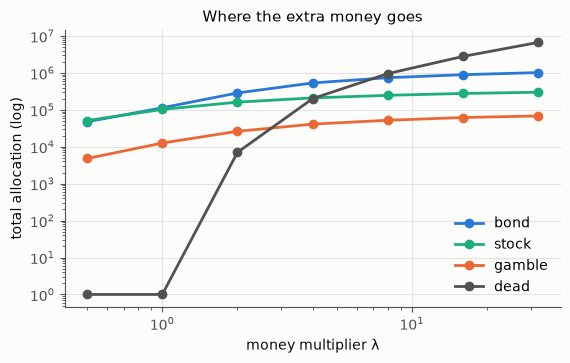

In [40]:
importlib.reload(exp3)
S5 = exp3.static_money((0.5, 1, 2, 4, 8, 16, 32))
print('   λ       債券       株式    大バクチ       死蔵    死蔵の割合')
for lam, b, s, g, d in S5:
    print(f'{lam:5.1f} {b:10.0f} {s:10.0f} {g:10.0f} {d:10.0f}     {d / (b + s + g + d):.3f}')
fig, ax = plt.subplots(figsize=(6.4, 3.6))
for j, (lab, c) in enumerate(zip(('bond', 'stock', 'gamble', 'dead'), (PAL[0], PAL[2], PAL[1], INK2))):
    ax.loglog(S5[:, 0], np.maximum(S5[:, 1 + j], 1), 'o-', color=c, label=lab)
ax.set(xlabel='money multiplier λ', ylabel='total allocation (log)', title='Where the extra money goes')
ax.legend(); plt.show()

作者の言うとおりの順番が出る。

- **λ = 0.5〜8: まず大バクチが増える**(4800 → 52000)。経験のない者・上昇志向の高い者の攻めの分と、株式の上限からあふれた分が、大バクチに入るからである。大バクチの総額は、家族ごとの上限(50 × 人数の補正)のために、λ = 8 あたりから頭打ちになる。「世の中に目ぼしい大バクチがなくなる」に当たる。
- **λ ≥ 2: 次に死蔵が増える**。債券の上限を超えた分が、死蔵に入る。λ = 32 では、商業資産の 83% が死蔵である。

### 5.3 死蔵の割合は、集中度の折れ線になる

では、死蔵の割合は、何の関数か。死蔵は「上限を超えた富」なので、家族 i の富を wᵢ、上限を B とすれば、死蔵の総額はおおよそ Σ max(wᵢ − B, 0) である。富の多い m 家族が、総額 W のうち割合 s を等しく持つなら、

$$\frac{\text{死蔵}}{W} = \frac{m \cdot \max(sW/m - B,\ 0)}{W} = \max\left(s - \frac{mB}{W},\ 0\right)$$

になる(Lean `hoard_equal_split`、`hoard_ratio`)。**傾き 1、閾値 mB/W の折れ線**である。上位が一様でなくても、どの m 家族を選んでも「その m 家族の富の和 − mB」が下からの評価になり(`hoard_lower_bound`)、富の移し替えで集中が進めば、死蔵は減らない(`hoard_concentration`。凸性)。

数値で確かめる。定常状態の分布で、下位の家族から上位(1%、2%、5%)の家族へ、富を比例して移し、集中度 s(上位の取り分)を上げていく。資産配分の滝で死蔵を計算し、折れ線 μ·max(0, s − θ) と、角を丸めた softplus μ·w·log(1 + exp((s − θ)/w)) を当てはめる。

In [41]:
%%writefile -a breakup.lean
/-! ## 第 5 章 上限と死蔵: 閾値つきの区分線形な関数

運用の上限 B を超えた富は死蔵に回る。家族 i の富を wᵢ ≥ 0 とすると、死蔵の総額は Σ max(wᵢ − B, 0)。

* 富の多い m 家族が、総額 W のうち割合 s を等しく持つなら、その死蔵は m · max(sW/m − B, 0) = max(sW − mB, 0)。
  W で割れば max(s − mB/W, 0)。つまり、死蔵の割合 = μ · max(0, Φ − θ) で、Φ = s(上位の取り分)、θ = mB/W、μ = 1。
* どの m 家族を選んでも、死蔵の総額は、その m 家族の富の和 − mB 以上(下からの評価)。 -/

theorem hoard_equal_split {m : ℝ} (hm : 0 < m) (s W B : ℝ) :
    m * max (s * W / m - B) 0 = max (s * W - m * B) 0 := by
  rw [mul_max_of_nonneg _ _ hm.le, mul_zero, mul_sub, mul_div_cancel₀ _ hm.ne']

theorem hoard_ratio {m W : ℝ} (hm : 0 < m) (hW : 0 < W) (s B : ℝ) :
    m * max (s * W / m - B) 0 / W = max (s - m * B / W) 0 := by
  rw [hoard_equal_split hm, ← max_div_div_right hW.le, zero_div, sub_div, mul_div_cancel_right₀ _ hW.ne']

/-- v6 の言葉への書き換え: 上位の m 家族の富が、利子の所得 rC の元本 C で、Φ = rC/Y(利払いの負担率)なら
C = ΦY/r。死蔵の割合 max(C/W − mB/W, 0) は、(Y/(rW)) · max(Φ − rmB/Y, 0) になる。
つまり ρ_eff = ρ + μ·max(0, Φ − θ) の形で、μ = Y/(rW)、θ = rmB/Y(上限まで運用した富が受け取る利子の、所得に対する比)。 -/
theorem hoard_as_rho_eff {r W Y : ℝ} (hr : 0 < r) (hW : 0 < W) (hY : 0 < Y) (Φ m B : ℝ) :
    max ((Φ * Y / r) / W - m * B / W) 0 = Y / (r * W) * max (Φ - r * m * B / Y) 0 := by
  have hc : 0 ≤ Y / (r * W) := by positivity
  rw [mul_max_of_nonneg _ _ hc, mul_zero]
  congr 1
  field_simp

theorem hoard_lower_bound {ι : Type*} (s T : Finset ι) (hT : T ⊆ s) (w : ι → ℝ) (B : ℝ) :
    ∑ i ∈ T, w i - (T.card : ℝ) * B ≤ ∑ i ∈ s, max (w i - B) 0 := by
  have h1 : ∑ i ∈ T, w i - (T.card : ℝ) * B = ∑ i ∈ T, (w i - B) := by
    rw [sum_sub_distrib, sum_const, nsmul_eq_mul]
  rw [h1]
  calc ∑ i ∈ T, (w i - B) ≤ ∑ i ∈ T, max (w i - B) 0 := sum_le_sum fun i _ => le_max_left _ _
    _ ≤ ∑ i ∈ s, max (w i - B) 0 :=
      sum_le_sum_of_subset_of_nonneg hT fun i _ _ => le_max_right _ _

/-- 死蔵の総額は、富の移し替えで集中が進むと増える(凸性): 富 a, b の二家族の間で、
差を広げる移し替え(和は同じ)をすると、死蔵は減らない。 -/
theorem hoard_concentration {a b d B : ℝ} (hab : b ≤ a) (hd : 0 ≤ d) :
    max (a - B) 0 + max (b - B) 0 ≤ max (a + d - B) 0 + max (b - d - B) 0 := by
  rcases le_total (a - B) 0 with h1 | h1 <;> rcases le_total (b - B) 0 with h2 | h2 <;>
    rcases le_total (a + d - B) 0 with h3 | h3 <;> rcases le_total (b - d - B) 0 with h4 | h4 <;>
    simp only [max_eq_left, max_eq_right, h1, h2, h3, h4] <;> linarith

Appending to breakup.lean


上位 1%: s 0.069 → 0.907、死蔵の割合 0 → 0.776。折れ線 μ 0.999 θ 0.130(R² 0.99998)。softplus μ 1.000 θ 0.131 幅 0.012(R² 1.00000)
上位 2%: s 0.129 → 0.913、死蔵の割合 0 → 0.663。折れ線 μ 0.995 θ 0.248(R² 0.99989)。softplus μ 1.000 θ 0.250 幅 0.021(R² 1.00000)
上位 5%: s 0.273 → 0.927、死蔵の割合 0 → 0.348。折れ線 μ 0.849 θ 0.531(R² 0.99550)。softplus μ 0.949 θ 0.562 幅 0.054(R² 0.99984)


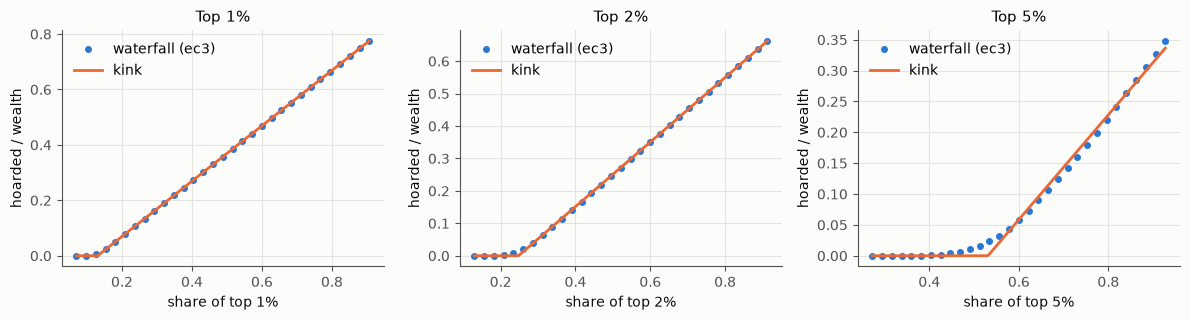

In [42]:
C5 = exp3.concentration()
fig, axs = plt.subplots(1, 3, figsize=(12, 3.3))
for ax, (frac, (S, D)) in zip(axs, C5.items()):
    pk, rk, ps, rs = exp3.fit_kink(S, D)
    print(f'上位 {frac * 100:.0f}%: s {S[0]:.3f} → {S[-1]:.3f}、死蔵の割合 0 → {D[-1]:.3f}。'
          f'折れ線 μ {pk[0]:.3f} θ {pk[1]:.3f}(R² {rk:.5f})。softplus μ {ps[0]:.3f} θ {ps[1]:.3f} 幅 {ps[2]:.3f}(R² {rs:.5f})')
    ax.plot(S, D, 'o', color=PAL[0], ms=4, label='waterfall (ec3)')
    ss = np.linspace(S[0], S[-1], 200)
    ax.plot(ss, pk[0] * np.maximum(0, ss - pk[1]), color=PAL[1], label='kink')
    ax.set(xlabel=f'share of top {frac * 100:.0f}%', ylabel='hoarded / wealth', title=f'Top {frac * 100:.0f}%')
    ax.legend()
plt.tight_layout(); plt.show()

上位 1% に集めると、死蔵の割合は**ほぼ完全に折れ線**になる(傾き μ ≈ 1.00、R² > 0.9999)。上位 2% でも同じ。上位 5% に広げると、上位の家族の上限がばらつくので、**角が丸まる**(折れ線の μ が 0.85 に下がり、softplus のほうがよく合う)。

これは、credit_creation_v6 のノートで、銀行の貸倒れから ρ_eff を導いたときの結論、「企業の閾値がばらつくなら、集計の max(0, Φ − θ) は滑らかな関数(softplus 型)になる」と同じ形である。

### 5.4 v6 の言葉に直す: 死蔵 = 実効的な準備

死蔵は、生産にも交換にも使われないお金である。銀行の側から見れば、預金されても貸し出しに回らない(あるいは、そもそも銀行に来ない)お金で、信用の流れから**漏れる**。これは、v6 の ρ_eff が表そうとした「退蔵」そのものである。

上位の m 家族の富を、利子の所得 rC の元本 C とみる(金利生活者の資産)。v6 の Φ = rC/Y(利払いの負担率。所得のうち利子として金利生活者に渡る割合)を使うと C = ΦY/r だから、

$$\frac{\text{死蔵}}{W} = \max\left(\frac{\Phi Y}{rW} - \frac{mB}{W},\ 0\right) = \frac{Y}{rW} \cdot \max\left(\Phi - \frac{r m B}{Y},\ 0\right)$$

になる(Lean `hoard_as_rho_eff`)。つまり、

- **μ = Y/(rW)**: 所得と富の比を金利で割ったもの。
- **θ = r m B / Y**: 金利生活者が、上限まで運用した富から受け取る利子の、所得に対する比。

という読みで、ρ_eff = ρ + μ·max(0, Φ − θ) と**同じ形**が出る。閾値 θ は、恣意的な定数ではなく、「運用の機会(商売のネタ)の総量」を表す。μ も、恣意的な傾きではなく、富と所得の比で決まる。

結果をまとめる(goal の条件 (3): 合っても合わなくても、結果どおりに書く)。

- **合ったこと**: 閾値つきの一次式という形。傾きと閾値の意味(上限の総量と、富・所得の比)。上位が一様に近いとき(上位 1〜2%)は、数値でもほぼ完全に折れ線になる。
- **合わなかったこと、条件つきのこと**: (i) 角が立つのは、上位の家族の上限がそろっているときだけで、上位に厚みがあれば softplus 型に丸まる。(ii) Φ と結びつけるには、「上位の富 = 利子の所得の元本」という仮定が要る。simbd には信用も金利もないので、この仮定は ec3 の中では確かめられない(v6 の家計の模型 v6a・v6b で確かめるべきこと)。(iii) simbd の死蔵は、収益率がほぼ 0(わずかに負)の資産で、信用の流れから完全に消えるわけではない(相続と消費で、ゆっくり戻る)。

### 5.5 「総資産が膨れる」のは違う ── 動学で見る

作者の最後の違和感、「それではまるで、法定準備金を下げれば総資産が膨れているかのような解釈をするということになる。それはなんか違う」を、動学で見る。80 年目に正の商業資産を λ 倍し、その直後(80〜82 年)と、20 年後(100〜109 年)を比べる。

さらに、作者の「目ぼしい大バクチがなくなる」を、**混雑**として入れた版と比べる。種類ごとに「商売のネタの量」を決め、前の年の総額がそれを超えると、その種類の収益の μ が(ネタの量 / 総額)倍に下がる(大バクチは平均がさらに負に寄る)。

In [43]:
I5 = exp3.pmap(exp3.inject, [(lam, crowd, s) for crowd in (False, True) for lam in (1, 3, 10) for s in range(4)])
print('混雑   λ     大バクチの総額(前 / 直後 / 20 年後)    死蔵の総額             大バクチの損益            平均の富')
for i, (crowd, lam) in enumerate([(c, l) for c in (False, True) for l in (1, 3, 10)]):
    R = I5[i * 4:(i + 1) * 4]
    m = {k: [np.mean([r[k][j] for r in R]) for j in range(3)] for k in R[0]}
    print(f'{"あり" if crowd else "なし"}  {lam:3d}   ' + '   '.join('/'.join(f'{v:.0f}' for v in m[k]) for k in ('amt_gamble', 'amt_dead', 'inc_gamble', 'mean_w')))

混雑   λ     大バクチの総額(前 / 直後 / 20 年後)    死蔵の総額             大バクチの損益            平均の富
なし    1   14012/13378/12447   5/0/1   -1852/-1846/-1570   263/272/251
なし    3   14012/40241/14715   5/52322/22   -1852/-4548/-1851   263/564/287
なし   10   14012/67843/16881   5/1412682/79   -1852/-7726/-1980   263/1483/334
あり    1   12794/12152/11481   2/0/0   -1906/-1598/-1622   252/256/235
あり    3   12794/36938/11202   2/39424/1   -1906/-7334/-1592   252/507/246
あり   10   12794/66112/10086   2/1205460/1   -1906/-13853/-1398   252/1324/259


- お金を 10 倍にすると、直後には死蔵が 140 万に膨らみ、平均の富は 5〜6 倍になる。しかし、**20 年後には、死蔵はほぼ 0 に戻り、平均の富も元の 1.3 倍ほど**にしか残らない。資産からの強い消費(毎年、資産の約 6%)と寄付が、だぶついたお金を消していく。
- 混雑を入れると、だぶついた直後の大バクチの損が約 1.8 倍に増え(目ぼしい大バクチがないのに、みなが大バクチをする)、**20 年後の平均の富は、注入の前とほとんど同じ**になる。

つまり、作者の違和感は正しい。お金がだぶつくと、**名目の資産は膨れるが、その多くは死蔵(使われない富)と、損な大バクチに入り、やがて消える**。総資産が実質的に膨れるわけではない。名目の量(お金の総額)と、実効の量(運用されて所得を生むお金)を分ければ、矛盾はない。死蔵の割合は、その二つのずれを測る量である。そして、そのずれが閾値つきの一次式になる、というのが、ρ_eff の形の、主体の側からの意味である。

一家離散は、どの場合もほとんど変わらない(第 4 章で見るとおり、一家離散は商業資産ではなく、農地の借金から来るので)。

---

## 第 6 章 戦争・人口・上昇志向の実験の読み直し

### 6.1 作者が首をかしげた結果

電子本の実験の章で、作者は「生きなければならない」(人口を増やし、経済を活発にする)の効果を、次の実験で調べた。

- normal(基準)、mwar(戦争が多い)、mwarmpop(さらに人口の目標を 1.1 倍)、mwarmpopmamb(さらに上昇志向の平均を 0.7 に誘導する。`--change-ambition --ambition-goal=0.70`)。

作者の見込みは、「上昇志向が上がると、リスクを取る人が増えるということだから経済が大きくなる」だった。結果について、電子本と構想のログにはこうある。

> 経済に関して見るために、経済から「税」または寄付としえ行われたものを累計した国家予算(Budget)を見てみる。普通に考えれば、normal が低く、mwarmpopmamb が高くなるはずであるのにまったくそうなっていない。
>
> mwarmpopmamb が経済が活発で予算が多くなるはずだが、normal とそれほど変わらない。一家離散も mwarmpopmamb が増えるはずなのに増えていない。(構想のログ、2021-11)

そして全体について、「この一連の実験では、変わるように定義しているのにわずかしか変化しないということが多く、それを確認していくのが一連の作業になる」と書いている。

### 6.2 読み: 独立なくじの集まりは、動きにくい

第 1.6 節で見たとおり、simbd の経済は**独立な家族のくじの集まり**で、家族どうしの間に、価格や需給を通した相互作用(一般均衡の経路)がない。すると、

1. **人口を増やしても、一人あたりの量は変わらない**。国家予算(寄付の和)は人口に比例するだけである。
2. **上昇志向を上げても、ほかの家族の収益は変わらない**。上昇志向は、自分の資産配分(株式と大バクチの割合)を変えるだけである。
3. **一家離散は、商業資産の運用からは起きない**(第 4 章)。上昇志向が変えるのは商業資産の配分なので、一家離散は動かない。

ec3 で確かめる。戦争と障害は ec3 にないので、人口と上昇志向だけを振る。上昇志向は、元の `--ambition-goal=0.70` の代わりに、分布を 0〜1 から 0.4〜1(平均 0.7)に変える。さらに、第 5 章の**混雑**(商売のネタの量を超えると収益が下がる)を入れた版と比べる。

In [44]:
ROWS6 = [('基準', {}), ('人口 1.5 倍', dict(n_families=1500)),
         ('上昇志向が高い(0.4〜1)', dict(ambition_range=(0.4, 1.0))),
         ('混雑あり', dict(crowding=exp3.CROWD)),
         ('混雑あり・上昇志向が高い', dict(crowding=exp3.CROWD, ambition_range=(0.4, 1.0))),
         ('人口 1.5 倍・混雑あり', dict(n_families=1500, crowding=exp3.CROWD))]
TAB6 = dict(exp3.table(ROWS6))
for lab, kw in ROWS6:
    m = TAB6[lab]
    print(f'  {lab:24s} 人口 {m["pop"]:6.0f}  国家予算(寄付) {m["donation"]:7.0f}/年  一人あたり {m["donation_pc"]:.3f}  '
          f'富の平均 {m["mean_w"]:6.1f}  Gini {m["gini"]:.3f}  一家離散 {m["breakup_rate"]:.4f}±{m["se"]:.4f}')

(覚え書きから 12 本、新しく計算 60 本)
  基準                       人口   3909  国家予算(寄付)   17602/年  一人あたり 4.581  富の平均  231.7  Gini 0.615  一家離散 0.0148±0.0021
  人口 1.5 倍                 人口   5857  国家予算(寄付)   26409/年  一人あたり 4.593  富の平均  232.3  Gini 0.613  一家離散 0.0175±0.0016
  上昇志向が高い(0.4〜1)           人口   3909  国家予算(寄付)   19886/年  一人あたり 5.181  富の平均  241.6  Gini 0.617  一家離散 0.0167±0.0023
  混雑あり                     人口   3909  国家予算(寄付)   16047/年  一人あたり 4.155  富の平均  223.4  Gini 0.616  一家離散 0.0170±0.0022
  混雑あり・上昇志向が高い             人口   3909  国家予算(寄付)   16777/年  一人あたり 4.328  富の平均  226.3  Gini 0.617  一家離散 0.0164±0.0023
  人口 1.5 倍・混雑あり            人口   5857  国家予算(寄付)   24150/年  一人あたり 4.177  富の平均  224.4  Gini 0.614  一家離散 0.0135±0.0017


- **人口を 1.5 倍にすると、国家予算もちょうど 1.5 倍**で、一人あたりは変わらない。富の平均も Gini も同じ。
- **上昇志向を上げると、一人あたりの予算は 1 割ほど増える**(株式の割合が増え、株式は債券より収益率が高いので)。富の平均も少し増える。しかし、**一家離散は変わらない**(第 4 章の理由で)。
- **混雑を入れると、上昇志向の効果は 3 分の 1 ほどに縮む**。みなが株式と大バクチに集まると、その収益が下がるからである。

作者の「予算が増えるはずが増えない」「一家離散が増えるはずが増えない」は、こう説明できる。

- 一家離散が増えないのは、一家離散が商業資産の運用ではなく、農地の割り当て(ec3)や、年の途中の資産の変化と年末の清算のずれ(simbd 全体。第 4.5 節)から起きるからである。上昇志向は、そこに触れない。
- 予算が増えにくいのは、上昇志向の効果がもともと 1 割ほどと小さいうえ、戦争の実験では、作者の言うとおり、怪我人が増えて労働の所得が減る効果と打ち消し合うからだろう(ec3 には戦争がないので、この部分は確かめていない)。
- 作者の見込み「リスクを取る人が増えると経済が大きくなる」には、**リスクを取る人の成功が、ほかの人の所得になる経路**(雇用、取引、価格)が要る。simbd にはその経路がない。micro_economy(ノート 1)や me_c にはある。二つをつなぐのが、ノート 4 の仕事である。

simbd 全体の大きな実験(戦争、僧の数)は、このノートでは回さない。経済の側からの読みは、上のとおりである。

---

## 第 7 章 災害と経済 ── 共通の打撃、守りの資本、記憶と学習

### 7.1 simbd の災害

simbd 全体には、六種類の災害がある(`calamity.py`): 洪水、大火事、大地震、作物の病気・日照り、疫病、蛮族の侵入。それぞれに月ごとの起きやすさ(洪水は夏から秋に多い)と規模の水準(3〜7)があり、被害は死・怪我・財産・作物・防御の五つに分かれる。

災害は三か月前に「予言」される。支配層は、その予言をもとに、どの災害に備えるかを決め、**防御の単位**(堤防のようなもの)と**訓練の単位**を建てる。防御と訓練は、年とともに劣化する。備えなかった地域には「成長機会」(challenge)が生まれる。電子本は、僧についてこう書いている。

> 破綻のリスク…つまり「災害」のリスクが実際に減るとわかっているならば、それは「捨て扶持」ではなく、ちゃんと扶持を与えて経済・支配構造に組み込む必要がある。

simbd の災害は、外から来る打撃でありながら、**備え(守りの資本)と予言(知識)で、被害が内生的に決まる**ものとして作られていた。ところが ec3 には、災害がなかった(農地の被害 `tmp_land_damage` は 0 に固定、怪我は年 0.5% の個人の出来事だけ)。この章では、災害を ec3 に足し、次の問いを調べる。

1. 災害は、家族の経済に何をするか。一度の大災害から、どう回復するか。
2. 災害は、家族ごとの運(第 2 章のレヴィの裾)と、何が違うか。どの安全網が効くか。
3. 守りの資本に予算を回すと、何が変わるか。
4. 災害の頻度を、記録から学ぶ社会と、忘れる社会は、どう違うか(ノート I の「社会が経済を学習する」との連結)。

### 7.2 ec3 の災害

simbd の災害を、経済に効く部分だけに縮める。

- 一年に、平均 `rate` 回(ポアソン)の災害が起きる。規模 s は、下限 0.05 のパレート分布(指数 `size_alpha`。小さいほど大災害が起きやすい)。
- 一度の災害は、家族の割合 `coverage` を襲う(1 なら国全体の共通の打撃)。襲われた家族は、商業資産(正の部分)の s を失い、農地はその年 s だけ不作になる(元の `tmp_land_damage` と同じ扱い)。一人ずつ、確率 s/2 で怪我をし(労働力が半分)、確率 s/20 で死ぬ。
- **守りの資本** G: 国の予算(寄付)の割合 φ を G に積む(年 5% 劣化)。一家族あたり 20 の G があると、被害が半分になる(被害 × 1/(1 + G/(20N)))。
- **救済**: 予算の残りを救済の蓄えに積み(予算の 3 年分まで)、災害の被害を埋める(`relief='state'`)。または、その年の被害を、全家族が富に比例して負担する(`relief='mutual'`。相互扶助)。

元の simbd では、寄付(国の予算)は支配層の扶持になるほかは、経済に戻ってこなかった。ec3 の既定値も同じで、予算は消える。守りや救済を入れると、予算が家族に戻るので、その分だけ富の水準も上がることに注意する。

災害の部品を ec3 に足す。**既定値では切ってあり、切れば乱数も引かない**ので、第 1〜6 章の数はそのまま変わらない。それを、二つのテストで確かめる。(1) v0.1.0 の ec3(災害のない版)を、80 年・種 3・400 家族で回した数の和(指紋)と、今の ec3 で災害を切った数の和が、ぴったり同じであること。(2) 災害の被害(農地の不作)の道が、元の simbdp3 の計算と同じ数になること(農地にランダムな被害を与えて、一年を比べる)。

In [45]:
%%writefile -a ec3.py
# 第 7 章: 災害。元の simbd の災害(calamity.py)を、経済に効く部分だけに縮めたもの。
@dataclass
class Disaster:
    rate: float = 0.1          # 一年あたりの災害の回数の平均(ポアソン)
    size_min: float = 0.05     # 規模 s の下限(s は被害の割合の目安)
    size_alpha: float = 1.5    # 規模の分布(パレート)の指数。小さいほど裾が重い
    coverage: float = 1.0      # 一度の災害が襲う家族の割合(1 なら国全体の共通の打撃、小さいと局地の打撃)
    w_property: float = 1.0    # 商業資産(正の部分)を s × w の割合で失う
    w_crop: float = 1.0        # 農地の不作: その年の農地の被害 = s × w
    w_injury: float = 0.5      # 一人ずつ、確率 s × w で労働力が半分になる
    w_death: float = 0.05      # 一人ずつ、確率 s × w で死ぬ(年末に、相続を経て清算する)
    regime: tuple = ()         # ((年, rate), ...): その年から頻度を変える
    events: tuple = ()         # ((年, s), ...): その年に、規模 s の災害を必ず起こす(外生の実験)


def disasters(families, P, stat):
    """その年の災害を起こし、家族に被害を与える。守りの資本が多いほど、被害が小さい。"""
    D, rng = P.disaster, P._drng
    t = getattr(P, '_t', 0)
    rate = D.rate
    for t0, r in D.regime:
        if t >= t0:
            rate = r
    sizes = list(D.size_min * (1 - rng.random(rng.poisson(rate))) ** (-1 / D.size_alpha))
    sizes += [s for t0, s in D.events if t0 == t]
    P._dis_count = getattr(P, '_dis_count', 0) + len(sizes)
    n = len(families)
    shield = 1 / (1 + getattr(P, '_G', 0.0) / (P.protect_scale * max(n, 1)))   # 守りで被害が減る
    for m in (m for f in families for m in f.members):
        m.tmp_land_damage = 0.0
    for f in families:
        f._dis_frac = 0.0
    P._dis_this_year = len(sizes) > 0
    lv = P.prop_value_of_land
    losses = np.zeros(n)
    for s in sizes:
        s_eff = min(1.0, s * shield)
        hit = rng.random(n) < D.coverage
        for k in np.flatnonzero(hit):
            f = families[k]
            f._dis_frac = 1 - (1 - f._dis_frac) * (1 - min(1.0, s_eff * D.w_property))
            for m in f.members:
                if m.prop > 0:
                    loss = m.prop * min(1.0, s_eff * D.w_property)
                    m.prop -= loss
                    losses[k] += loss
                m.tmp_land_damage = 1 - (1 - m.tmp_land_damage) * (1 - min(1.0, s_eff * D.w_crop))
                if rng.random() < s_eff * D.w_injury:
                    m.labor = max(0.1, m.labor * 0.5)
                if rng.random() < s_eff * D.w_death:
                    m.age = 1000                      # 年末の人口の動きで、確率 1 で死ぬ(相続を経る)
    stat['dis_n'] += len(sizes)
    stat['dis_loss'] += losses.sum()
    # 救済
    if P.relief == 'state' and losses.sum() > 0:
        pay = min(getattr(P, '_R', 0.0), losses.sum())
        for k in np.flatnonzero(losses):
            share = pay * losses[k] / losses.sum()
            f = families[k]
            f.leader.prop += share
        P._R = getattr(P, '_R', 0.0) - pay
        stat['relief_paid'] += pay
    elif P.relief == 'mutual' and losses.sum() > 0:
        w = np.array([max(sum(m.asset_value(lv) for m in f.members), 0.0) for f in families])
        if w.sum() > 0:
            for k, f in enumerate(families):           # 被害を埋め、その費用を富に比例して全家族で負担する
                f.leader.prop += losses[k] - losses.sum() * w[k] / w.sum()
        stat['relief_paid'] += losses.sum()


def update_learning(P, stat):
    """災害の頻度 λ を、記録から学ぶ(ガンマ・ポアソン)。忘れる割合 forget で古い記録を割り引く。
    守りに回す割合 φ = min(φmax, k × 信念の λ)。信念は、平均(中立)、上側の分位点(悲観)、下側(楽観)。"""
    L = P.learning
    from scipy.stats import gamma
    P._n_eff = L.get('forget', 1.0) * getattr(P, '_n_eff', 0.0) + stat['dis_n']
    P._t_eff = L.get('forget', 1.0) * getattr(P, '_t_eff', 0.0) + 1.0
    a, b = L.get('prior_a', 1.0) + P._n_eff, L.get('prior_b', 1.0) + P._t_eff
    q = {'neutral': None, 'pessimistic': 0.9, 'optimistic': 0.1}[L.get('attitude', 'neutral')]
    lam = a / b if q is None else gamma.ppf(q, a, scale=1 / b)
    P.protect_share = min(L.get('phi_max', 0.8), L.get('k', 2.0) * lam)
    stat['belief'] = lam
    stat['belief_lo'] = gamma.ppf(0.1, a, scale=1 / b)
    stat['belief_hi'] = gamma.ppf(0.9, a, scale=1 / b)


def budget(families, P, stat):
    """国の予算(その年の寄付)の使い道: 守りの資本に φ、残りは救済の蓄え(relief='state' のとき)。"""
    if P.learning is not None:
        update_learning(P, stat)
    B = stat['donation']
    P._G = (1 - P.protect_decay) * getattr(P, '_G', 0.0) + P.protect_share * B
    if P.relief == 'state':
        P._R = min(getattr(P, '_R', 0.0) + (1 - P.protect_share) * B, P.fund_cap * B)
    stat['protect'] = P._G / max(len(families), 1)
    stat['fund'] = getattr(P, '_R', 0.0) / max(len(families), 1)
    stat['phi'] = P.protect_share

Appending to ec3.py


In [46]:
importlib.reload(ec3); importlib.reload(test_ec3)
d = test_ec3.test_identity()
print(f'(1) 災害を切った ec3 と、v0.1.0 の ec3 の指紋の差: {d}')
assert d == 0.0
for s in range(2):
    w, nb = test_ec3.test_simbdp3(s, years=2, damage=True)
    print(f'(2) 農地の被害の道、シード {s}、2 年: 元との差の最大 {w:.1e}')
    assert w < 1e-9

(1) 災害を切った ec3 と、v0.1.0 の ec3 の指紋の差: 0.0
(2) 農地の被害の道、シード 0、2 年: 元との差の最大 1.4e-14


(2) 農地の被害の道、シード 1、2 年: 元との差の最大 2.8e-14


どちらも通る。以下、災害の実験では、災害の乱数を別の乱数の列から引く(ほかの乱数の並びは、災害がないときと同じ)。

### 7.3 一度の大災害からの回復

災害のない社会に、80 年目に一度だけ、規模 0.6 の大災害を起こす(全家族が、商業資産の 6 割と、その年の作物の 6 割を失い、3 割が怪我をし、3% が死ぬ)。救済なし、国の蓄えで救済、相互扶助で比べる(8 シード)。ec3 の社会には、初めの世代の人口の波が残っていて、災害がなくても富は年とともに上下する。そこで、同じ種で災害を起こさない**対照**の道と比べる。

In [47]:
%%writefile -a exp3.py
D7 = dict(rate=0.1, size_min=0.05, size_alpha=1.5)       # 基準の災害(十年に一度ほど、規模はパレート 1.5)


dis_table = table          # 第 7 章の表も、同じ統計の関数と覚え書きを使う


def shock_path(a):
    """80 年目に、規模 s の災害を一度だけ起こす(ほかには災害なし)。75〜119 年の時系列。"""
    s, relief, seed = a
    o, f, P = ec3.simulate(T=120, seed=seed, n_families=NF, relief=relief,
                           disaster=ec3.Disaster(rate=0.0, events=((80, s),)))
    keys = ('mean_w', 'median_w', 'welfare', 'breakup', 'pop', 'gini')
    return {k: o[k][75:120] for k in keys}


def learn_path(a):
    """災害の頻度が変わる世界で、記録から学んで守りを決める。0〜59 年は年 0.3 回、60 年からは静か(年 0.01 回)、
    130 年目に大災害(規模 0.6)。forget は記録を残す割合(1 なら忘れない)。"""
    forget, attitude, seed = a
    D = ec3.Disaster(rate=0.3, regime=((60, 0.01),), events=((130, 0.6),))
    learning = None if forget is None else dict(forget=forget, attitude=attitude, k=2.0, phi_max=0.8)
    o, f, P = ec3.simulate(T=145, seed=seed, n_families=NF, disaster=D, relief='state', learning=learning,
                           protect_share=0.0 if learning is None else 0.0)
    keys = ('protect', 'phi', 'dis_loss', 'mean_w', 'welfare', 'median_w')
    r = {k: o[k] for k in keys}
    r['belief'] = o['belief'] if learning else np.zeros(145)
    return r

Appending to exp3.py


道        富の平均(75 / 80 / 85 / 95 / 110 / 119 年)   中央(80 / 95 / 110 年)   生活保護(80 / 85 / 100 年)  一家離散(80〜90 年)  人口(80 / 95 / 119 年)
control     266 /   272 /   277 /   272 /   241 /   227      185 /   148 /    70      5.4 /  5.5 /  6.9          0.00          3507 / 3494 / 3885
none        266 /   151 /   175 /   207 /   210 /   204      115 /   105 /    59     18.5 / 17.8 / 10.8          0.00          3403 / 3434 / 3877
state       266 /   186 /   208 /   231 /   218 /   208      134 /   118 /    59     15.0 / 13.8 / 10.4          0.00          3403 / 3434 / 3877
mutual      266 /   153 /   174 /   202 /   203 /   199       90 /    84 /    53     25.9 / 16.1 /  8.4          0.50          3403 / 3434 / 3877
救済なしの富の平均 / 対照(85 / 95 / 110 / 119 年): 0.63 / 0.76 / 0.87 / 0.90


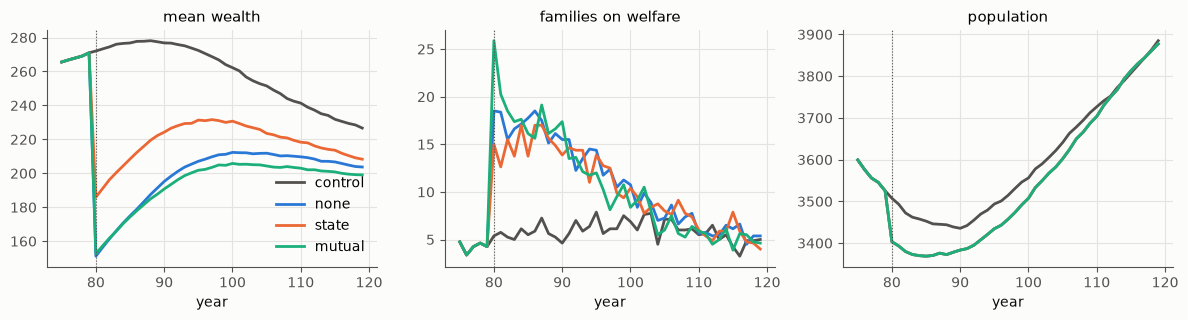

In [48]:
importlib.reload(exp3)
SH = {}
for lab, size, rel in (('control', 0.0, 'none'), ('none', 0.6, 'none'), ('state', 0.6, 'state'), ('mutual', 0.6, 'mutual')):
    R = exp3.pmap(exp3.shock_path, [(size, rel, s) for s in range(8)])
    SH[lab] = {k: np.mean([r[k] for r in R], 0) for k in R[0]}
yrs = np.arange(75, 120)
print('道        富の平均(75 / 80 / 85 / 95 / 110 / 119 年)   中央(80 / 95 / 110 年)   生活保護(80 / 85 / 100 年)  一家離散(80〜90 年)  人口(80 / 95 / 119 年)')
for rel, m in SH.items():
    print(f'{rel:8s}  ' + ' / '.join(f'{m["mean_w"][i]:5.0f}' for i in (0, 5, 10, 20, 35, 44)) + '    '
          + ' / '.join(f'{m["median_w"][i]:5.0f}' for i in (5, 20, 35)) + '     '
          + ' / '.join(f'{m["welfare"][i]:4.1f}' for i in (5, 10, 25)) + f'          {m["breakup"][5:16].sum():.2f}          '
          + ' / '.join(f'{m["pop"][i]:4.0f}' for i in (5, 20, 44)))
c0 = SH['control']['mean_w']
print('救済なしの富の平均 / 対照(85 / 95 / 110 / 119 年):', ' / '.join(f'{SH["none"]["mean_w"][i] / c0[i]:.2f}' for i in (10, 20, 35, 44)))
fig, axs = plt.subplots(1, 3, figsize=(12, 3.3))
for c, (rel, m) in zip([INK2] + PAL, SH.items()):
    axs[0].plot(yrs, m['mean_w'], color=c, label=rel); axs[1].plot(yrs, m['welfare'], color=c, label=rel); axs[2].plot(yrs, m['pop'], color=c, label=rel)
for ax, t in zip(axs, ('mean wealth', 'families on welfare', 'population')):
    ax.axvline(80, color=INK2, lw=0.8, ls=':'); ax.set(xlabel='year', title=t)
axs[0].legend(); plt.tight_layout(); plt.show()

- 大災害の年に、富の平均は対照の 6 割ほどに落ちる。生活保護を受ける家族は 3〜4 倍に増える(怪我で働けない家族が増えるので)。**回復は遅い**。富の平均は、30 年たっても対照より 1〜2 割低く、生活保護も対照より多いまま残る。怪我は治らず(ec3 では労働力は戻らない)、失った商業資産は、運と労働から少しずつしか戻らない。
- 国の蓄えで救済すると、落ち込みは浅い(蓄えは予算の 3 年分まで)。
- 相互扶助では、富の平均は救済なしとほぼ同じで、**中央の富はかえって下がり、生活保護は増える**。全家族が同時に打撃を受けるので、分け合っても埋まらない。富に比例した負担は、農地を持つが現金のない家族の商業資産を、借金に変える。
- 人口は、死者の分だけ減ったあと、出生で取り戻す(人口の目標に向かって出生が増える)。
- 一家離散は、ほとんど増えない。この理由は 7.4 節で見る。

### 7.4 頻度と規模: 一家離散は、災害の害の物差しにならない

災害の起きやすさ(年 0.1 回、0.2 回)と、大災害の起きやすさ(パレートの指数 1.2、1.5、2.5)を振る(150 年、最後の 120 年、12 シード)。

In [49]:
D = ec3.Disaster
B7 = exp3.D7
ROWS_F = [('災害なし', {}), ('基準の災害(年 0.1 回、指数 1.5)', dict(disaster=D(**B7))),
          ('頻度 2 倍(年 0.2 回)', dict(disaster=D(**dict(B7, rate=0.2)))),
          ('裾が重い(指数 1.2)', dict(disaster=D(**dict(B7, size_alpha=1.2)))),
          ('裾が軽い(指数 2.5)', dict(disaster=D(**dict(B7, size_alpha=2.5)))),
          ('基準・怪我と死なし', dict(disaster=D(**B7, w_injury=0.0, w_death=0.0)))]
ROWS_C = []
for cov, lab0, rate in ((1.0, '共通(全家族)', 0.1), (0.1, '局地(1 割の家族)', 1.0)):
    for rel, lab1 in (('none', '救済なし'), ('mutual', '相互扶助'), ('state', '国の蓄え')):
        ROWS_C.append((f'{lab0}・{lab1}', dict(disaster=D(**dict(B7, rate=rate, coverage=cov)), relief=rel)))
ROWS_P = [(f'守り φ = {phi}', dict(disaster=D(**B7), relief='state', protect_share=phi)) for phi in (0.0, 0.2, 0.5, 0.8)]
TAB7 = dict(exp3.dis_table(ROWS_F + ROWS_C + ROWS_P))


def show7(rows):
    for lab, kw in rows:
        m = TAB7[lab]
        print(f'  {lab:26s} 一家離散 {m["breakup_rate"]:.4f}±{m["se"]:.4f}  生活保護 {m["welfare"]:5.2f}/年  富の平均 {m["mean_w"]:6.1f}  '
              f'中央 {m["median_w"]:6.1f}  被害 {m["dis_loss"]:6.0f}/年  救済 {m["relief_paid"]:6.0f}/年  守り {m["protect"]:5.1f}/家族')


show7(ROWS_F)

  災害なし                       一家離散 0.0148±0.0021  生活保護  4.13/年  富の平均  231.7  中央  104.3  被害      0/年  救済      0/年  守り   0.0/家族
  基準の災害(年 0.1 回、指数 1.5)      一家離散 0.0095±0.0016  生活保護  7.03/年  富の平均  190.1  中央   84.4  被害   2572/年  救済      0/年  守り   0.0/家族
  頻度 2 倍(年 0.2 回)            一家離散 0.0113±0.0020  生活保護  9.97/年  富の平均  159.4  中央   71.2  被害   3969/年  救済      0/年  守り   0.0/家族
  裾が重い(指数 1.2)               一家離散 0.0157±0.0020  生活保護  8.00/年  富の平均  184.6  中央   82.9  被害   3108/年  救済      0/年  守り   0.0/家族
  裾が軽い(指数 2.5)               一家離散 0.0185±0.0029  生活保護  6.18/年  富の平均  198.6  中央   87.2  被害   2199/年  救済      0/年  守り   0.0/家族
  基準・怪我と死なし                  一家離散 0.0256±0.0038  生活保護  4.38/年  富の平均  195.9  中央   85.5  被害   2424/年  救済      0/年  守り   0.0/家族


災害は、富を減らし(平均で 2 割ほど)、生活保護を増やす(4 → 7 件、頻度 2 倍で 10 件)。ところが、**一家離散は、基準の災害でかえって減る**(0.015 → 0.010)。怪我と死を切ると、一家離散は 0.026 に増える(災害なしの 1.7 倍)。

理由は、第 4.2 節の式にある。一家離散が起きうるのは、年末の資産の底 −25.5 × 労働力 が、線 −20 × 人数 を割り込む家族、つまり労働力 / 人数 > 0.78 の家族だけだった。怪我で労働力が半分になった独り身は、底が −12.75 になり、**もう一家離散できない**。死んだ独り身も、一家離散しない(相続で清算される)。災害は、一家離散しうる家族を「一家離散できない貧しさ」に移す。だから、**一家離散の数は、災害の害の物差しにならない**。生活保護の数や、中央の富のほうが、害をよく表す。

裾の重さ(指数)を変えると、一家離散の数は単調には動かない。被害が増えて線を割り込む家族が増える効果と、怪我と死で一家離散しうる家族が減る効果が、打ち消し合うからである。作者が「一番気になっている」と書いた一家離散の数は、安全網の式の臨界値のまわりで、こういうねじれ方をする量である。

### 7.5 共通の打撃と相互扶助

第 4.6 節で、家族どうしの相互扶助(頼母子講)は、家族ごとの有限責任の値打ちを壊して高くついた。災害は、家族の間で**相関する**打撃である。国全体を襲う共通の打撃と、一度に 1 割の家族だけを襲う局地の打撃(頻度は 10 倍にして、平均の被害をそろえる)で、救済の仕方を比べる。

In [50]:
show7(ROWS_C)

  共通(全家族)・救済なし               一家離散 0.0095±0.0016  生活保護  7.03/年  富の平均  190.1  中央   84.4  被害   2572/年  救済      0/年  守り   0.0/家族
  共通(全家族)・相互扶助               一家離散 0.0942±0.0721  生活保護  6.90/年  富の平均  187.5  中央   76.8  被害   2508/年  救済   2508/年  守り   0.0/家族
  共通(全家族)・国の蓄え               一家離散 0.0127±0.0024  生活保護  6.59/年  富の平均  212.5  中央   92.9  被害   3029/年  救済   2447/年  守り   0.0/家族
  局地(1 割の家族)・救済なし            一家離散 0.0171±0.0024  生活保護  7.15/年  富の平均  187.3  中央   79.7  被害   2667/年  救済      0/年  守り   0.0/家族
  局地(1 割の家族)・相互扶助            一家離散 0.0124±0.0015  生活保護  6.95/年  富の平均  185.9  中央   74.2  被害   2668/年  救済   2668/年  守り   0.0/家族
  局地(1 割の家族)・国の蓄え            一家離散 0.0109±0.0017  生活保護  6.50/年  富の平均  219.9  中央   95.9  被害   3427/年  救済   3411/年  守り   0.0/家族


- **局地の打撃**では、相互扶助が効く(一家離散 0.017 → 0.012)。襲われなかった 9 割の家族が、襲われた 1 割の被害を埋められるからである。これは保険の原理そのものである。
- **共通の打撃**では、相互扶助は効かないどころか、**一家離散を跳ね上げる**(シードによって大きくばらつく)。全家族が同時に打撃を受けると、分け合う相手がいない。そのうえ、負担を富(農地を含む)に比例させると、農地はあるが現金のない家族が、商業資産で負担を払わされて借金になる。第 4 章の「借金で農地を買わされる」と同じ道で、一家離散が起きる。
- **国の蓄え**(過去の予算を積んだもの)は、どちらの打撃にも効く。共通の打撃は、同じ年の家族の間では分け合えないが、**年をまたいで**なら分け合える。蓄えは、時間の上の保険である。

家族ごとの(独立な)打撃には有限責任、局地の打撃には相互の保険、共通の打撃には年をまたぐ蓄え(と守り)が効く。打撃の相関の構造が、効く安全網を決める。simbd 全体で、災害への備えを支配層(国)が担い、寺が寄付を集めるのは、この意味で理にかなっている。

### 7.6 守りの資本

予算のうち割合 φ を守りの資本に、残りを救済の蓄えに回す(基準の災害、共通の打撃)。

In [51]:
show7(ROWS_P)

  守り φ = 0.0                 一家離散 0.0127±0.0024  生活保護  6.59/年  富の平均  212.5  中央   92.9  被害   3029/年  救済   2447/年  守り   0.0/家族
  守り φ = 0.2                 一家離散 0.0203±0.0030  生活保護  5.04/年  富の平均  220.9  中央   96.5  被害   1402/年  救済   1163/年  守り  30.3/家族
  守り φ = 0.5                 一家離散 0.0178±0.0026  生活保護  4.93/年  富の平均  220.3  中央   96.0  被害    998/年  救済    719/年  守り  76.3/家族
  守り φ = 0.8                 一家離散 0.0149±0.0022  生活保護  4.55/年  富の平均  222.9  中央   97.1  被害    632/年  救済    547/年  守り 123.9/家族


守りに回す割合を増やすと、災害の被害は 3000 → 600 ほどに減り、生活保護も減り、富の平均は少し上がる。蓄えで事後に埋めるより、守りで事前に減らすほうが効く(守りは毎年の予算を少しずつ積み、劣化も 5% と小さい)。一家離散の数は、ここでもばらついて、よい物差しにならない。

守りの最適な量は、費用 c·G と期待被害 λ·D/(1 + G) の和を最小にして、G* = √(λD/c) − 1 になる(相加・相乗平均の不等式。Lean `protection_amgm`)。G* は、災害の頻度の信念 λ とともに増える(`protection_monotone`)。だから、**λ が区間でしか言えないなら、守りの量も区間でしか言えない**。ノート I で、贅沢品の値打ちの信念が区間なら、支配されない配分が区間になったのと同じ形である(`undominated_iff`)。

### 7.7 記憶と学習

では、災害の頻度 λ を、社会はどう知るのか。記録から学ぶ。事前の信念をガンマ分布とし、毎年の災害の回数を見て更新する(ガンマ・ポアソン)。事後の平均は、事前の平均と記録の頻度を混ぜたもので、記録が長いほど記録に寄る(Lean `posterior_mean_mix`)。守りに回す割合は、信念の λ の 2 倍(上限 0.8)とする。

simbd の「記憶する社会」(墓、僧の回向)と、寺田寅彦の言葉と伝えられる「天災は忘れた頃にやって来る」を、**忘れる割合**で表す。記録を毎年 ω の割合しか残さない社会では、記録の実効の年数は、何年たっても 1/(1 − ω) を超えない(Lean `forgetting_bound`)。ω = 0.9 なら 10 年分しか覚えていない。

世界は次のように変わる。0〜59 年は災害が多く(年 0.3 回)、60 年からは静か(年 0.01 回)になり、130 年目に大災害(規模 0.6)が来る。比べるのは、学ばない社会(守りなし)、忘れない社会(ω = 1)、忘れる社会(ω = 0.9)、そして悲観的な社会(信念の区間の上端、90% の分位点を使う。ノート I の maxmin)である。

In [52]:
%%writefile -a breakup.lean
/-! ## 第 7 章 災害と、守りと、記憶

### 守りの最適な量
守りの資本 G の費用 c·G と、災害の被害 λ·D/(1 + G)(λ は頻度、D は守りのないときの被害)の和を最小にする。
x = 1 + G とおくと、c·x + A/x ≥ 2√(cA)(A = λD)。等号は x = √(A/c)。
ここでは s² = cA, s ≥ 0 として、c·x + A/x ≥ 2s を示す。 -/

theorem protection_amgm {c A x s : ℝ} (hc : 0 < c) (hx : 0 < x) (hs : s ^ 2 = c * A) :
    2 * s ≤ c * x + A / x := by
  have key : 0 ≤ c * (c * x ^ 2 - 2 * s * x + A) := by nlinarith [sq_nonneg (c * x - s)]
  have h2 : 0 ≤ c * x ^ 2 - 2 * s * x + A := (mul_nonneg_iff_of_pos_left hc).mp key
  have e : c * x + A / x = (c * x ^ 2 + A) / x := by field_simp
  rw [e, le_div_iff₀ hx]
  nlinarith

/-- 最適な守りの量 √(λD/c) − 1 は、頻度の信念 λ とともに増える。だから、信念が区間 [λlo, λhi] なら、
ふさわしい守りの量も区間になり(ノート I の `undominated_iff` と同じ形)、悲観的な社会は多く守る。 -/
theorem protection_monotone {D c l₁ l₂ : ℝ} (hD : 0 ≤ D) (hc : 0 < c) (h : l₁ ≤ l₂) :
    Real.sqrt (l₁ * D / c) - 1 ≤ Real.sqrt (l₂ * D / c) - 1 := by
  have : l₁ * D / c ≤ l₂ * D / c :=
    div_le_div_of_nonneg_right (mul_le_mul_of_nonneg_right h hD) hc.le
  linarith [Real.sqrt_le_sqrt this]

/-! ### 記録から頻度を学ぶ(ガンマ・ポアソン)
事前の信念をガンマ分布(a, b)とし、t 年で n 回の災害を見ると、事後の平均は (a + n)/(b + t)。
これは、事前の平均 a/b と、記録の頻度 n/t を、重み b/(b + t) と t/(b + t) で混ぜたものである。
記録が長くなるほど(t が大きいほど)、記録の頻度に寄る。 -/

theorem posterior_mean_mix {a b n t : ℝ} (hb : 0 < b) (ht : 0 < t) :
    (a + n) / (b + t) = b / (b + t) * (a / b) + t / (b + t) * (n / t) := by
  have hbt : 0 < b + t := by linarith
  field_simp

/-- 忘れる社会は確信できない: 記録を毎年 ω(< 1)の割合しか残さないと、記録の実効の年数
Σ ωᵏ は、何年たっても 1/(1 − ω) を超えない。だから信念の区間は、ある幅より狭くならない
(ノート I の `crisis_collapse` が言う「区間が一点に縮む」ことは、忘れる社会では起きない)。 -/
theorem forgetting_bound {ω : ℝ} (h0 : 0 ≤ ω) (h1 : ω < 1) (N : ℕ) :
    ∑ k ∈ range N, ω ^ k ≤ 1 / (1 - ω) := by
  have hne : ω ≠ 1 := ne_of_lt h1
  rw [geom_sum_eq hne N]
  have hpos : 0 < 1 - ω := by linarith
  have hp : 0 ≤ ω ^ N := pow_nonneg h0 N
  rw [show (ω ^ N - 1) / (ω - 1) = (1 - ω ^ N) / (1 - ω) by
        rw [← neg_sub, ← neg_sub 1 ω, neg_div_neg_eq]]
  exact div_le_div_of_nonneg_right (by linarith) hpos.le

Appending to breakup.lean


社会                       信念の頻度(59 / 129 年)  守りの割合 φ(59 / 129)  守り/家族(129)  130 年の被害   生活保護(130〜134 年の和)  富の平均(129 / 135 / 144)
no learning                 0.000 /  0.000       0.00 / 0.00            0.0        162819          58.4             216 /   167 /   190
remember (ω=1)              0.318 /  0.156       0.64 / 0.31           64.3         39934          23.0             221 /   220 /   226
forget (ω=0.9)              0.366 /  0.107       0.72 / 0.21           37.3         56122          30.2             213 /   210 /   219
remember, pessimistic       0.387 /  0.188       0.74 / 0.38           74.0         35142          23.2             215 /   216 /   221
forget, pessimistic         0.607 /  0.229       0.80 / 0.46           81.4         33143          22.4             222 /   222 /   227


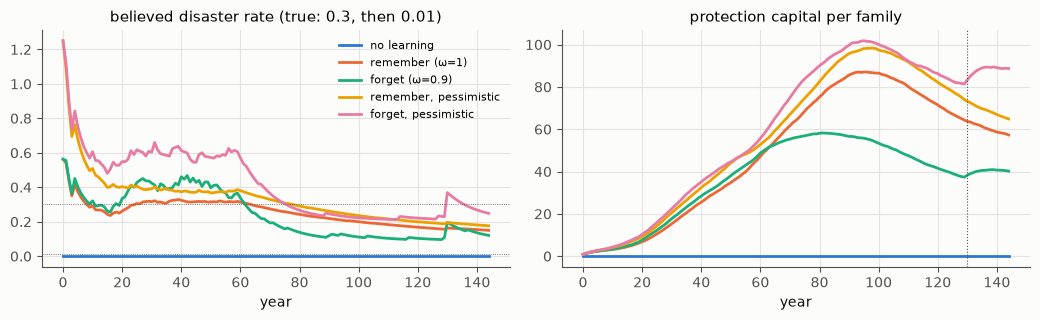

In [53]:
CF = [(None, 'neutral', 'no learning'), (1.0, 'neutral', 'remember (ω=1)'), (0.9, 'neutral', 'forget (ω=0.9)'),
      (1.0, 'pessimistic', 'remember, pessimistic'), (0.9, 'pessimistic', 'forget, pessimistic')]
LP = {}
for fg, att, lab in CF:
    R = exp3.pmap(exp3.learn_path, [(fg, att, s) for s in range(8)])
    LP[lab] = {k: np.mean([r[k] for r in R], 0) for k in R[0]}
print('社会                       信念の頻度(59 / 129 年)  守りの割合 φ(59 / 129)  守り/家族(129)  130 年の被害   生活保護(130〜134 年の和)  富の平均(129 / 135 / 144)')
for lab, m in LP.items():
    print(f'{lab:24s}   {m["belief"][59]:6.3f} / {m["belief"][129]:6.3f}       {m["phi"][59]:4.2f} / {m["phi"][129]:4.2f}         {m["protect"][129]:6.1f}      {m["dis_loss"][130]:8.0f}        {m["welfare"][130:135].sum():6.1f}           '
          + ' / '.join(f'{m["mean_w"][i]:5.0f}' for i in (129, 135, 144)))
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.3))
t = np.arange(145)
for c, (lab, m) in zip(PAL, LP.items()):
    axs[0].plot(t, m['belief'], color=c, label=lab); axs[1].plot(t, m['protect'], color=c, label=lab)
axs[0].axhline(0.3, color=INK2, lw=0.6, ls=':'); axs[0].axhline(0.01, color=INK2, lw=0.6, ls=':')
axs[0].set(xlabel='year', title='believed disaster rate (true: 0.3, then 0.01)')
axs[1].set(xlabel='year', title='protection capital per family'); axs[1].axvline(130, color=INK2, lw=0.8, ls=':')
axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()

- **忘れない社会**は、多かった時代の記録を持ち続けるので、静かな 70 年のあとも信念の頻度が高めに残り(真の 0.01 より高い)、守りを保つ。130 年の大災害の被害は、学ばない社会の 4 分の 1 ほどで済む。
- **忘れる社会**は、静かな時代に信念の頻度が下がり、守りを減らす。大災害の被害は、忘れない社会より大きい。「天災は忘れた頃にやって来る」である。
- **悲観的な社会**(信念の区間の上端で守る)は、忘れる社会でも守りを高く保つ。忘れると、記録の実効の年数が 10 年で頭打ちになるので、**信念の区間が縮まない**。区間が広いまま残るので、上端で守る社会は、多く守る。

これは、ノート I の議論の、災害の側での姿である。

- ノート I では、贅沢品の値打ちの信念が区間なら、配分は区間の中で決まらず、曖昧さへの態度(悲観か楽観か)で決まった。危機を経験すると区間が縮み、配分は一点に決まった(`crisis_collapse`)。
- ここでは、災害の頻度の信念が区間で、守りの量も区間になる(`protection_monotone`)。災害を経験すると区間が縮む。しかし、**忘れる社会では、区間はある幅より狭くならない**(`forgetting_bound`)。記憶がなければ、危機の教訓は一点に収束しない。
- 記録を残す制度(墓、寺、僧)は、記録の実効の年数を延ばし、区間を縮める。simbd が僧を「記憶する社会」の担い手として組み込んだのは、経済の側から見ると、**守りの資本の量を学ぶための装置**である。ノート I の「社会が経済を学習する」は、ここでは「社会が災害の頻度を学習する」という具体的な形をとる。
- ノート I の第 3 章では、危険率の総和が有限なら、永遠に生き延びる確率は正だった。守りの資本は、災害の被害(危険率)を下げる。学び続ける社会は、守りを保ち、危険率を下げ続ける道を持つ。忘れる社会は、静かな時代にその道を手放す。

### 7.8 v6 への橋と、ノート 4 に引き継ぐ教訓

- 災害が農地(担保)を壊すと、土地の担保で借りていた信用が縮む(Kiyotaki と Moore 1997 の増幅)。v6a の土地の担保と、ここでの農地の不作をつなげば、災害は信用の崩れの引き金になる。
- 災害は、予備的な貯蓄(死蔵)を増やすはずである。第 5 章の死蔵の割合は、上限を超えた富だったが、災害への備えとしての死蔵は、もう一つの経路で ρ_eff を押し上げる。

ノート 4 に引き継ぐ教訓:

1. 打撃には、家族ごとの(独立な)打撃と、局地の打撃と、共通の打撃があり、効く安全網が違う(有限責任、相互の保険、年をまたぐ蓄えと守り)。
2. 危険率は、公共の資本(守り)と記憶(学習)で内生化される。外生の打撃を入れる実験の口も残す(ここでの `events`)。
3. 一家離散のような、安全網の臨界値のまわりの数は、害の物差しにならないことがある。生活保護や中央の富など、複数の物差しで見る。
4. 帳簿の時計を一つにする(第 4.5 節の死者の一家離散。第 8 章)。

---

## 第 8 章 シミュレーション仏教への提案 ── よりリアルな版

### 8.1 何がリアルでなかったか

ここまでで、simbd の経済の「リアルでない」ところが、いくつか具体的に見えた。

1. **帳簿の時計が二つある**(第 4.5 節)。人の出来事は一か月ごとに、経済は一年ごとに清算され、資産の所得は一年の平均の資産で、損の上限は年末の資産で計算される。このずれが、死者の一家離散を生んだ。
2. **支払いが、誰の所得にもならない**(第 1.6 節)。地主の払う賃金も、家族の消費も、経済から消える。お金は運と労働から湧き、消費で消える。家族の間をお金が回らないので、上昇志向や人口を変えても、ほかの家族に何も起きない(第 6 章)。
3. **収益率が外から与えられ、発散を上限で止める**(第 2・5 章)。資産の発散を、上限・強い消費・寄付の三つで止めている。どれも調整する数を持ち、作者は実験を見ながらそれらを選んだ。
4. **調整の数が多く、目標がはっきりしない**(第 4.1 節)。ロスカット 27.5 は、「一家離散がゼロもおかしいが、悪目立ちしすぎない」という目標で選ばれた。その目標は、臨界値のすぐ上という、壊れやすい場所だった。

この章では、1〜3 を、ec3 の部品(または元の simbd 全体への一行の差分)として小さく実装し、それぞれが一家離散と富の分布をどう変えるかを見る。部品は既定値では切ってあり、全部切れば ec3 は元と同じ数になる(第 1.5 節と第 7.2 節のテスト)。4 は、提案として書く。ノート 4 では、simbd をリアルにすることは追わないので、これは**シミュレーション仏教への提案**としてまとめておく。

### 8.2 帳簿の時計を一つにする

元の simbd 全体で、資産の所得を一年の平均の資産ではなく、**年末の資産**で計算する(`make_families` の一行)。これで、損を計算する資産と、損の上限を計算する資産が、同じ時点のものになる。四つの種で、元の版と比べる。元の simbd 全体は、種とハッシュを固定しても完全には再現しない(オブジェクトの集合の並び順などのため、と考えられる)。そのため件数は実行ごとに少し揺れるが、ここでの差は揺れよりずっと大きい。

In [54]:
print('差分(一行):')
for a, b in orig3.ONE_CLOCK['simbdp3/economy.py']:
    print('- ' + a.rstrip('\n') + '\n+ ' + b.rstrip('\n'))
t0 = time.time()
FULL_ONE = orig3.run_full_many(os.path.abspath('simbd_full_run_oneclock'), seeds=(1, 2, 3, 4), extra=orig3.ONE_CLOCK)
print(f'({time.time() - t0:.0f} 秒)')
for lab, RR in (('元の版(第 4.5 節の実行)', FULL), ('時計を一つにした版', FULL_ONE)):
    recs = [x for r in RR for x in r['breakup_rec']]
    print(f'  {lab:22s} 一家離散 {[sum(r["breakup"]) for r in RR]}(計 {len(recs)} 件、うち死者だけの家族 {sum(1 for x in recs if x[6] == x[0])} 件)  '
          f'生活保護(最後の 10 年の平均) {np.mean([np.mean(r["welfare"][-10:]) for r in RR]):.1f}  人口 {[r["population"][-1] for r in RR]}')

差分(一行):
-         f.prop = sum([np.mean(p.mlog['prop']) for p in f.members.values()])
+         f.prop = sum([p.prop for p in f.members.values()])


(141 秒)
  元の版(第 4.5 節の実行)        一家離散 [6, 6, 8, 5](計 25 件、うち死者だけの家族 23 件)  生活保護(最後の 10 年の平均) 1.7  人口 [2685, 2623, 2679, 2660]
  時計を一つにした版              一家離散 [0, 0, 0, 1](計 1 件、うち死者だけの家族 0 件)  生活保護(最後の 10 年の平均) 2.2  人口 [2652, 2645, 2651, 2661]


一行の差分で、**死者の一家離散は消える**。生きている者の一家離散も、この実行ではほとんど起きない。生活保護の件数や人口は、ほとんど変わらない。帳簿の時計を一つにするのは、simbd 全体への最も安い提案である。

同じことを、ec3 の**部品**としても示す。ec3 は、もともと時計が一つである(死は年末に、相続を経て清算される)。そこに、元の simbd の「二つの時計」を再現する部品 `two_clocks` を足す。死は年の途中に起き、遺産はその場で相続人に配られ、死者は年末まで家族に残る(その年の労働力は、生きていた月の割合)。資産の所得は一年の平均の資産(死ぬ前と後の半々)で計算し、損の上限は年末の資産で計算する。部品を切れば(既定値)、ec3 は元と同じ数になる(下の 8.4 節のテスト)。

In [55]:
%%writefile -a exp3.py
real_table = table         # 第 8 章の表も、同じ統計の関数と覚え書きを使う


def clock_stats(a):
    """二つの時計(two_clocks)ありとなしの、一家離散と、そのうち死者だけの家族の数。"""
    tc, seed = a
    o, f, P = ec3.simulate(T=T, seed=seed, n_families=NF, two_clocks=tc)
    return dict(breakup=float(o['breakup'][BURN:].sum()), dead=float(o['breakup_dead'][BURN:].sum()),
                fy=float(o['n_families'][BURN:].sum()), mean_w=float(o['mean_w'][BURN:].mean()), gini=float(o['gini'][BURN:].mean()))

Appending to exp3.py


In [56]:
importlib.reload(exp3)
for tc, lab in ((True, '二つの時計(元の simbd と同じ)'), (False, '時計が一つ(ec3 の既定)')):
    R = exp3.pmap(exp3.clock_stats, [(tc, s) for s in exp3.SEEDS])
    b, d, fy = sum(r['breakup'] for r in R), sum(r['dead'] for r in R), sum(r['fy'] for r in R)
    print(f'  {lab:22s} 一家離散 {b:3.0f} 件(1000 家族・年あたり {1000 * b / fy:.4f})、うち家族の全員がすでに死んでいたもの {d:3.0f} 件。'
          f'富の平均 {np.mean([r["mean_w"] for r in R]):6.1f}  Gini {np.mean([r["gini"] for r in R]):.3f}')

  二つの時計(元の simbd と同じ)    一家離散  61 件(1000 家族・年あたり 0.0221)、うち家族の全員がすでに死んでいたもの  25 件。富の平均  232.9  Gini 0.616


  時計が一つ(ec3 の既定)         一家離散  41 件(1000 家族・年あたり 0.0148)、うち家族の全員がすでに死んでいたもの   0 件。富の平均  231.7  Gini 0.615


二つの時計の ec3 では、元の simbd 全体と同じく、**死者の一家離散**が現れる(一家離散の 4 割ほど)。時計を一つにすれば、0 件になる。富の分布は、ほとんど変わらない。死者の一家離散は、帳簿の時計のずれだけから生まれる、模型の作り物(アーティファクト)である。

### 8.3 支払いを誰かの所得にする

二つの部品を足す(どちらも一年遅れで払う。その年の支払いの総額が決まってから配るため)。

- **賃金を雇い人の所得に**(`wage_to_workers`): 地主が雇い人に払った賃金の総額を、翌年、農地を持たない家族の労働の所得に、労働力に比例して足す。
- **消費を商人の売り上げに**(`sales_margin`): 消費の総額の 10% を、翌年、株式(技能を使う商売)をしている家族の資産の所得に、株式の額に比例して足す。

### 8.4 収益率を内生化する

第 5.5 節の**混雑**(種類ごとの総額が商売のネタの量を超えると、収益率が下がる)を、そのまま部品として使う。上限で発散を止める代わりに、収益率が下がることで止める道である。

部品を一つずつ、そして三つ一緒に入れて比べる(150 年、最後の 120 年、12 シード)。上の裾の重さは、上位 5% の家族のヒルの推定量(パレートの指数)で測る。指数が小さいほど、裾が重い(格差の頂点が高い)。

まず、**部品を全部切れば元と一致する**ことを確かめる。

- (1) ec3: よりリアルな版の部品(二つの時計、賃金を雇い人に、消費を商人に、混雑)と災害をすべて明示的に切ると、v0.1.0 の ec3 の指紋とぴったり同じ数になる。部品を一つずつ切っても、部品を入れて効かない値にしても(混雑のネタの量を無限大に、災害を頻度 0 で入れて守りの道も通す)、同じ数になる。部品の道を通るだけでは、元の計算は壊れない。そのうえで、元の simbdp3 の一年の計算とも一致する(第 1.5 節と同じテスト)。
- (2) 元の simbd 全体: 帳簿の時計を一つにする差分は、追加の差分(`extra`)として渡すときだけ当たる。渡さなければ、書き出されるファイルは第 4.5 節の実行と同じである(ファイルの中身を比べる)。

In [57]:
OFF = dict(wage_to_workers=False, sales_margin=0.0, crowding=None, two_clocks=False, disaster=None, protect_share=0.0, relief='none', learning=None,
           breakup_rule='members', leverage=0.0, debt_rate=0.0, child_cost=0.0, kin_rescue=0.0, kin_take=False)
d = test_ec3.test_identity()
print(f'(1) 部品を全部切った ec3 と、v0.1.0 の ec3 の指紋の差: {d}')
assert d == 0.0
for lab, dd in test_ec3.test_components():
    print(f'(1) 部品ごと: {lab:30s} v0.1.0 の指紋との差 {dd}')
    assert dd == 0.0
w, nb = test_ec3.test_simbdp3(0, years=2, **OFF)
print(f'(1) 部品を全部切った ec3 と、元の simbdp3 の一年の計算の差の最大: {w:.1e}(一家離散 ec3 {nb[0]:.0f}、元 {nb[1]})')
assert w < 1e-9 and nb[0] == nb[1]
import filecmp
a_dir = os.path.abspath('simbd_full_run/seed1')
b_dir = os.path.abspath('simbd_check_noextra')
os.makedirs(os.path.join(b_dir, 'simbdp3'), exist_ok=True)
for n in orig3.SHA256:
    if n.startswith('simbdp3') or n == 'normal_levy_1.0.csv':
        src = orig3.fetch(n).replace('\r\n', '\n')
        for x, y in orig3.FULL_PATCHES.get(n, []):
            src = src.replace(x, y)
        open(os.path.join(b_dir, n), 'w').write(src)
names = [n for n in orig3.SHA256 if n.startswith('simbdp3') or n == 'normal_levy_1.0.csv']
same = all(filecmp.cmp(os.path.join(a_dir, n), os.path.join(b_dir, n), shallow=False) for n in names)
c_dir = os.path.abspath('simbd_full_run_oneclock/seed1')
diff = [n for n in names if not filecmp.cmp(os.path.join(a_dir, n), os.path.join(c_dir, n), shallow=False)]
print(f'(2) 追加の差分なしで書き出したファイル {len(names)} 個は、第 4.5 節の実行と同じ: {same}。時計を一つにした版で違うファイル: {diff}')
assert same and diff == ['simbdp3/economy.py']

(1) 部品を全部切った ec3 と、v0.1.0 の ec3 の指紋の差: 0.0


(1) 部品ごと: 二つの時計を切る                       v0.1.0 の指紋との差 0.0
(1) 部品ごと: 賃金を雇い人に、を切る                    v0.1.0 の指紋との差 0.0
(1) 部品ごと: 消費を商人に、を切る(割合 0)               v0.1.0 の指紋との差 0.0
(1) 部品ごと: 混雑を切る                          v0.1.0 の指紋との差 0.0
(1) 部品ごと: 混雑を入れるが、ネタの量を無限大に              v0.1.0 の指紋との差 0.0
(1) 部品ごと: 災害を切る                          v0.1.0 の指紋との差 0.0
(1) 部品ごと: 災害を入れるが、頻度 0・事件なし              v0.1.0 の指紋との差 0.0
(1) 部品ごと: 災害を入れ、守りと救済の道も通すが、頻度 0         v0.1.0 の指紋との差 0.0
(1) 部品ごと: 学習を切る                          v0.1.0 の指紋との差 0.0
(1) 部品ごと: 一家離散の基準を元のまま(人数の線)             v0.1.0 の指紋との差 0.0
(1) 部品ごと: 梃子を切る                          v0.1.0 の指紋との差 0.0
(1) 部品ごと: 借金の利子を切る                       v0.1.0 の指紋との差 0.0
(1) 部品ごと: 子の養育の費用を切る                     v0.1.0 の指紋との差 0.0
(1) 部品ごと: 親族の助けと引き取りを切る                  v0.1.0 の指紋との差 0.0
(1) 部品ごと: 親族の引き取りだけを入れる(元の一家離散は子のない家族だけなので、効かない) v0.1.0 の指紋との差 0.0
(1) 部品を全部切った ec3 と、元の simbdp3 の一年の計算の差の最大: 2.8e-14(一家離散 ec3 0、元 0)
(2) 追加の差分なしで書き出したファイル 20 個は、第 4.5 節の実行と同

In [58]:
importlib.reload(exp3)
ROWS8 = [('基準(元と同じ)', {}), ('賃金を雇い人に', dict(wage_to_workers=True)),
         ('消費の 10% を商人に', dict(sales_margin=0.1)), ('混雑(収益率の内生化)', dict(crowding=exp3.CROWD)),
         ('三つとも', dict(wage_to_workers=True, sales_margin=0.1, crowding=exp3.CROWD))]
TAB8 = dict(exp3.real_table(ROWS8))
for lab, kw in ROWS8:
    m = TAB8[lab]
    print(f'  {lab:20s} 一家離散 {m["breakup_rate"]:.4f}±{m["se"]:.4f}  生活保護 {m["welfare"]:4.1f}/年  富の平均 {m["mean_w"]:6.1f}  中央 {m["median_w"]:6.1f}  '
          f'Gini {m["gini"]:.3f}  上位 10% {m["top10"]:.3f}  パレートの指数 {m["hill"]:.2f}')
print()
for lab, kw in ROWS8:
    m = TAB8[lab]
    print(f'  {lab:20s} 一年の流れ: 資産の所得 {m["income_asset"]:7.0f}  労働の所得 {m["income_labor"]:7.0f}  消費 {m["consumption"]:7.0f}  '
          f'地主の払う賃金 {m["wages"]:7.0f}  寄付 {m["donation"]:7.0f}')

(覚え書きから 12 本、新しく計算 48 本)
  基準(元と同じ)             一家離散 0.0148±0.0021  生活保護  4.1/年  富の平均  231.7  中央  104.3  Gini 0.615  上位 10% 0.374  パレートの指数 5.81
  賃金を雇い人に              一家離散 0.0011±0.0005  生活保護  0.3/年  富の平均  421.0  中央  346.9  Gini 0.446  上位 10% 0.269  パレートの指数 6.75
  消費の 10% を商人に         一家離散 0.0123±0.0019  生活保護  4.0/年  富の平均  252.0  中央  111.3  Gini 0.617  上位 10% 0.371  パレートの指数 5.96
  混雑(収益率の内生化)          一家離散 0.0170±0.0022  生活保護  4.1/年  富の平均  223.4  中央  100.0  Gini 0.616  上位 10% 0.376  パレートの指数 5.52
  三つとも                 一家離散 0.0025±0.0010  生活保護  0.3/年  富の平均  332.9  中央  267.6  Gini 0.439  上位 10% 0.272  パレートの指数 6.16

  基準(元と同じ)             一年の流れ: 資産の所得   39338  労働の所得   16742  消費   40107  地主の払う賃金   15393  寄付   17602
  賃金を雇い人に              一年の流れ: 資産の所得   77400  労働の所得   31746  消費   68836  地主の払う賃金   15418  寄付   38756
  消費の 10% を商人に         一年の流れ: 資産の所得   47491  労働の所得   16730  消費   43861  地主の払う賃金   15396  寄付   22330
  混雑(収益率の内生化)          一年の流れ: 資産の所得   36564  労働の所得   16749  消費   38849  地主の払う賃金

- **賃金を雇い人の所得にする**と、分布が大きく変わる。Gini は 0.62 → 0.45、中央の富は 3 倍、生活保護はほぼなくなり、一家離散も 1/10 ほどになる。元の simbd では、地主の払う賃金(年に 1.5 万ほど。労働の所得とほぼ同じ大きさ)が、誰の所得にもならずに消えていた。それを農地のない家族に回すと、商人と小農が貧しさから抜けやすくなる。
- **消費の一部を商人の売り上げにする**と、富は少し増える(売り上げは、株式をしている、比較的豊かな家族に入る)。
- **混雑**は、富を少し減らし、上の裾を少し重くする(なぜ重くなるかは、ここでは確かめていない)。
- 三つ一緒では、賃金の効果が支配的である。

富の上の裾(パレートの指数)は、どの版でも 5〜7 ほどで、現実の富の分布(1.5 前後)よりずっと**軽い**。上限と強い消費と寄付が、上の裾を切っているからである。現実の裾の重さを出すには、上限ではなく、収益率の異質性と持続性(第 2.4 節の注、Fagereng ほか 2020)と、相続のしかたを、模型に入れる必要がある。

### 8.5 一家離散が起きる基準 ── 一人暮らしでない家族の一家離散

ここまでの模型では、一家離散するのは一人暮らしだけだった(第 4.2 節の式)。しかし、一人暮らしだけというのは「一家離散」のイメージと違う。安全網(口分田など)を整えたうえで一家離散がまったくないのも、かえってリアルさに欠ける。とくに大きな災害のあとには、多少はあるほうがリアルだろう。一方、子どもがいたり怪我をしたりすると一家離散しにくいことにも、リアルな面がある(周りが助ける、債権者が取り立てを控える、など)。ただし、今の模型でそうなっているのは、帳簿の式の作り物(一家離散の線が人数に、損の底が労働力に比例する)である。

そこで、一家離散が起きる基準と、それを左右する仕掛けを、いくつか部品として足して試す。どれも既定値では切ってあり、切れば元と同じ数になる(下のテスト)。

- **一家離散の基準**(`breakup_rule`): 元は「資産の合計が −20 × 人数 を割り込んだら」。これを「−20 × 労働力」(返す力に比例する線)、または「**資産の合計が負の年が 3 年続いたら**」(首が回らない状態が続く)に替える。
- **借金の利子**(`debt_rate`): 商業資産が負の家族は、借金に年 10% の利子を払う(元は利子がない)。
- **子の養育の費用**(`child_cost`): 15 歳未満の子一人あたり、最低の消費を上乗せする(元は、子の消費は労働力 0.1 × 3 = 0.3 ほどで、子が多くても家計はほとんど苦しくならない)。
- **借りて商売をする梃子**(`leverage`): 経験 10 年以上の商人が、株式の額の何倍かを借りて商売を大きくする。借りた分の損益はロスカットで消えず、利子がつく。災害は、借りて持っていた商売の資産も壊す。「運の悪い商人の破産」の道である。
- **親族の助けと引き取り**(`kin_rescue`、`kin_take`): 子のある家族が一家離散しそうなとき、親の家族(祖父母)が富の 3 割までで借金を肩代わりする。それでも一家離散すれば、15 歳未満の子は祖父母の家族に引き取られる。子どもが一家離散を防ぐ、**はっきりした仕掛け**である。

まず、部品を切れば元と一致することを確かめる。

In [59]:
for lab, dd in test_ec3.test_components()[-6:]:
    print(f'部品ごと: {lab:44s} v0.1.0 の指紋との差 {dd}')
    assert dd == 0.0

部品ごと: 一家離散の基準を元のまま(人数の線)                           v0.1.0 の指紋との差 0.0
部品ごと: 梃子を切る                                        v0.1.0 の指紋との差 0.0
部品ごと: 借金の利子を切る                                     v0.1.0 の指紋との差 0.0
部品ごと: 子の養育の費用を切る                                   v0.1.0 の指紋との差 0.0
部品ごと: 親族の助けと引き取りを切る                                v0.1.0 の指紋との差 0.0
部品ごと: 親族の引き取りだけを入れる(元の一家離散は子のない家族だけなので、効かない)       v0.1.0 の指紋との差 0.0


次に、基準と部品を組み合わせて、一家離散した家族の顔ぶれを見る(150 年、最後の 120 年、12 シード)。「災害後 3 年内」は、災害の年かその後 3 年以内に起きた一家離散の割合で、括弧の中は、そういう年が全体に占める割合である(一家離散が災害と関係なく起きるなら、二つは同じくらいになる)。「対策」は、口分田と、賃金を雇い人に(第 4.6 節、第 8.3 節)の二つを入れたもの。

In [60]:
%%writefile -a exp3.py
def breakup_profile(a):
    """一家離散した家族の顔ぶれ: 一人暮らしでないもの、子のあるもの、借りて商売をしていたもの、農地を持つもの、災害の年のもの。"""
    kw, seed = a
    log = []
    kw = dict(dict(n_families=NF), **kw)
    o, fams, P = ec3.simulate(T=T, seed=seed, log=log, **kw)
    L = [l for l in log if l['year'] >= BURN]
    fy = o['n_families'][BURN:].sum()
    dis_years = float(np.mean(o['dis_n'][BURN:] > 0))
    dyear = set(int(t) for t in np.flatnonzero(o['dis_n'] > 0))
    after = lambda t: any(t - k in dyear for k in range(0, 4))           # 災害の年か、その後 3 年以内
    win_years = float(np.mean([after(t) for t in range(BURN, T)]))
    return dict(n=len(L), rate=1000 * len(L) / fy, multi=sum(l['n'] > 1 for l in L), kids=sum(l['kids'] > 0 for l in L),
                win=sum(after(l['year']) for l in L), win_years=win_years,
                loan=sum(bool(l['loan5']) for l in L), land=sum(l['land'] > 0 for l in L), dis=sum(bool(l['dis']) for l in L),
                dis_years=dis_years, nsum=float(sum(l['n'] for l in L)),
                gini=float(o['gini'][BURN:].mean()), median_w=float(o['median_w'][BURN:].mean()),
                welfare=float(o['welfare'][BURN:].mean()), rescue=float(o['rescue'][BURN:].sum()))


def profile_table(rows, seeds=SEEDS):
    R = pmap(breakup_profile, [(kw, s) for lab, kw in rows for s in seeds])
    n, out = len(seeds), []
    for i, (lab, kw) in enumerate(rows):
        rs = R[i * n:(i + 1) * n]
        m = {k: float(np.sum([r[k] for r in rs])) for k in ('n', 'multi', 'kids', 'loan', 'land', 'dis', 'win', 'rescue', 'nsum')}
        m.update({k: float(np.mean([r[k] for r in rs])) for k in ('rate', 'dis_years', 'win_years', 'gini', 'median_w', 'welfare')})
        m['size'] = m['nsum'] / max(m['n'], 1)          # 一家離散した家族の平均人数(件数で重みをつける)
        m['se'] = float(np.std([r['rate'] for r in rs]) / np.sqrt(n))
        out.append((lab, m))
    return out

Appending to exp3.py


In [61]:
importlib.reload(exp3)
D85 = ec3.Disaster(**exp3.D7)
FIX = dict(land_grant=True, wage_to_workers=True)
A = dict(debt_rate=0.1, breakup_rule='streak', child_cost=1.0)
ROWS85 = [('基準(元と同じ)', {}),
          ('線を労働力に', dict(breakup_rule='labor')),
          ('負が 3 年続けば', dict(breakup_rule='streak')),
          ('A: 利子 + 負 3 年 + 養育 1', A),
          ('A + 災害', dict(A, disaster=D85)),
          ('A + 親族の助けと引き取り', dict(A, kin_rescue=0.3, kin_take=True)),
          ('A + 口分田', dict(A, land_grant=True)),
          ('A + 口分田 + 梃子 2 + 災害', dict(A, land_grant=True, leverage=2.0, disaster=D85)),
          ('B: 対策 + 利子 + 負 3 年 + 梃子 1', dict(FIX, debt_rate=0.1, breakup_rule='streak', leverage=1.0)),
          ('B: 対策 + 利子 + 負 3 年 + 梃子 2', dict(FIX, debt_rate=0.1, breakup_rule='streak', leverage=2.0)),
          ('B: 対策 + 利子 + 負 3 年 + 梃子 2 + 災害', dict(FIX, debt_rate=0.1, breakup_rule='streak', leverage=2.0, disaster=D85)),
          ('A で養育 1.5', dict(A, child_cost=1.5))]
TAB85 = dict(exp3.profile_table(ROWS85))
print('模型                                   一家離散(1000 家族・年)  件数  一人暮らしでない  子あり  5 年内に借りて商売  農地あり  災害後 3 年内(その年の割合)  平均人数  Gini  中央の富')
for lab, kw in ROWS85:
    m = TAB85[lab]; n = max(m['n'], 1)
    print(f'{lab:36s} {m["rate"]:7.4f}±{m["se"]:.4f}  {m["n"]:5.0f}     {m["multi"] / n:5.2f}       {m["kids"] / n:5.2f}       {m["loan"] / n:5.2f}       {m["land"] / n:5.2f}       '
          + (f'{m["win"] / n:5.2f}({m["win_years"]:.2f})' if m['win_years'] > 0 else '    —       ') + f'      {m["size"]:4.2f}  {m["gini"]:.3f}  {m["median_w"]:5.0f}')

模型                                   一家離散(1000 家族・年)  件数  一人暮らしでない  子あり  5 年内に借りて商売  農地あり  災害後 3 年内(その年の割合)  平均人数  Gini  中央の富
基準(元と同じ)                              0.0148±0.0021     41      0.00        0.00        0.00        1.00           —             1.00  0.615    104
線を労働力に                                0.1147±0.0069    317      0.00        0.00        0.00        1.00           —             1.00  0.616    104
負が 3 年続けば                             0.0022±0.0008      6      0.00        0.00        0.00        1.00           —             1.00  0.616    103
A: 利子 + 負 3 年 + 養育 1                  0.0109±0.0028     30      0.33        0.47        0.00        0.60           —             1.77  0.627     91
A + 災害                                0.0189±0.0037     52      0.50        0.46        0.00        0.69        0.38(0.33)      2.02  0.631     73
A + 親族の助けと引き取り                        0.0062±0.0013     17      0.00        0.00        0.00        1.00           —             1.00  

**一家離散の基準を替えるだけでは、一人暮らしでない家族の一家離散は出ない。** 線を労働力に比例させると一家離散は増えるが、増えるのは一人暮らしの小農である。「負が 3 年続けば」では、かえって減る(資産が負の家族は、労働の所得の上乗せと借金に利子がないことで、すぐに立ち直る)。子のある家族を守っていたのは、線の形だけではなく、**子の消費が軽いこと**と、**借金に利子がつかないこと**だった。

**A(借金の利子 + 負が 3 年続けば + 子の養育の費用)では、一家離散の半分ほどが子のある家族になる**。家族の人数の平均も 2 人前後になる。子沢山の貧しい家族が、利子のつく借金を返せずに沈んでいく、という一家離散である。そこに災害が来ると、一家離散は 7 割ほど増え、災害の年とその後 3 年に、全体の割合より多く起きる(災害のこだま)。

**親族の助けと引き取りを入れると、子のある家族の一家離散は消える**。親の家族が肩代わりできるうちは、一家離散しない。子どもが一家離散を防ぐことを、帳簿の式の作り物ではなく、**家族の網の目という仕掛け**として表せる。逆に言えば、親族の網の目が薄い(親の家族も貧しい、親がいない)家族から一家離散する。

**口分田と梃子を入れると(A + 口分田 + 梃子 2 + 災害)、一家離散の 7 割ほどは、5 年以内に借りて商売をしていた家族になり、3 割は一人暮らしでない家族である**。ここでは、農地の借金ではなく、**運の悪い商人の破産**が一家離散の主な道になる。災害は、借りて持っていた商売の資産を壊し(借金は残る)、災害のあとの一家離散を増やす。

**B(対策を二つとも入れ、梃子で商売をする)では、一家離散はほぼすべて商人の破産になる**。ただし、その多くは子のない家族である。「賃金を雇い人に」で働き手の多い家族の所得が大きく底上げされるので、子のある家族は 3 年のうちに立ち直る。

**どの模型も、数に敏感である**。梃子を 1 倍から 2 倍にすると、一家離散は数十倍に増える。養育の費用を 1 から 1.5 にすると、子沢山の家族の一家離散が爆発する。第 4.2 節のロスカット 27.5 と同じく、一家離散は臨界値のまわりの出来事で、調整した数がそのすぐ近くに来やすい。次の 8.6 節で述べるとおり、目標の統計量に合わせて数を選び、臨界値からの距離を測っておく必要がある。なお、どの模型でも一家離散の率は、現実の世帯の破産の率の目安(年に世帯の 0.1〜1%、つまり 1000 家族・年あたり 1〜10 件)よりずっと小さい。古代の社会の一家離散の率は、それよりさらに不確かである。

まとめると、「運の悪い商人の破産」や「子沢山の貧しい家族」の一家離散は、**一家離散の基準(首が回らない状態が続く)に、借金の利子、子の養育の費用、借りて商売をする道を組み合わせると出る**。そして、子どもが一家離散を防ぐリアルな面は、**親族の網の目**として、はっきり入れられる。

### 8.6 調整の数を減らし、目標に合わせる(提案)

simbd の経済には、調整する数が多い(上限が三つ、ロスカット、借金の余裕、寄付の二つ、消費の係数が三つ、レヴィの倍率…)。作者は、それを実験の図を見ながら選んだ。提案は、次のとおりである。

1. **目標の統計量を先に決める**。たとえば、富のパレートの指数(1.5 前後)、Gini(0.6〜0.8)、破産の率(年に人口の 0.1〜1% ほど)、生活保護を受ける割合。
2. **目標との差を最小にするように、数を選ぶ**(模擬積率法。McFadden 1989、Duffie と Singleton 1993)。これは、作者の「最適化で簡単に書く」という発想を、価格を決めるためではなく、**模型を調整するため**に使うことである。
3. **臨界値の近くを避ける**。第 4.2 節の式のような、帳簿から出る臨界値を先に計算し、調整した数がそのすぐ近くに来たら、結果が壊れやすいと知っておく。

### 8.7 全員を動かさず、標本にする(提案)

simbd 全体は、全員を一か月ごとに動かす。経済だけを見るなら、v6b の方法(マクロの帳簿と、標本の家族。第 9.3 節)で足りる。標本の家族は、ec3 のように、元と同じ一年の計算をするものにでき、保存則と一致のテストで守れる。

### 8.8 元のコードの直し方(まとめ)

| 直すところ | 直し方 | 章 |
|---|---|---|
| 死者の一家離散 | 資産の所得を年末の資産で計算する(一行) | 4.5、8.2 |
| 負になった家族の者の額の上書き(`mns =`) | `mns +=` にする | 1.5 |
| レヴィの部分の一様乱数 | 正規乱数にする(表と同じ作り方) | 2.5 |
| 地主の賃金が消える | 雇い人の所得にする | 8.3 |
| 毎月の図の描画 | `--no-view` のときは描かない | 4.5 |

どれも、直すと作者の調整(とくにロスカット 27.5)の前提が変わるので、直したあとに、8.6 節の方法で調整し直すのがよい。

---

## 第 9 章 四つの層の対応表、v6b の標本、そしてまとめ

### 9.1 対応表

作者の経済モデルは、同じ経済の別々の「層」を描いている(このシリーズの見立て。ノート 1 の第 10 章)。simbd の経済の各部品が、ほかの層のどこに当たるかを、この文書で得た式とともに表にする。

| simbd | 信用循環 v6 | micro_economy / me_c | 資産市場(ノート 2)/ v6a |
|---|---|---|---|
| **死蔵**(上限を超えた富) | 実効準備 ρ_eff の上乗せ。死蔵 / 富 = (Y/(rW))·max(0, Φ − rmB/Y)(第 5 章) | — | 預金の退蔵 |
| **大バクチ**(期待値が負、上の裾だけに値打ち) | 投機・泡 | — | 知財の高値買い |
| **債券・株式の収益**(元手とともに収益率が上がる) | 金利 r と株式的富 E | 標準の利潤率 r̄(me_c) | 配当と地代 |
| **上限**(商売のネタ) | 閾値 θ(運用の機会の総量) | 分野ごとの生産能力 K_j(me_c) | 担保の上限 |
| **農地**(割り当て、くじ、借金で買う) | — | — | 土地(δ = 0)。v6a では市場で値段がつく |
| **生活保護** | 政府の移転 | 失業者への給付(me_c) | — |
| **一家離散**(負の富の線を割り込む) | 債務不履行 | 企業の退出 | 借入の上限を超えた分の貸倒れ(v6a) |
| **寄付**(累進の資産税と同じ働き) | 税 | 税(me_c の均衡予算の財政) | — |

### 9.2 収益率の由来

三つのモデルで、収益率の決まり方が違う。

- simbd: 種類ごとの μ を、外から与える(元手に比例。経験で少し上がる)。
- me_c: 標準の利潤率 r̄ を外から与え、生産能力の増減で、各分野の利潤率が r̄ にそろう。
- v6: 金利が信用の量から決まり、株式的富 E = K^α/(r + δ) が金利で割り引かれる。

simbd の「上限 + 混雑」(第 5.5 節、第 8.4 節)は、収益率を内生化する最初の一歩になる。種類ごとの総額が商売のネタの量を超えると、収益率が下がる。これを「ネタの量 = 生産能力」と読めば me_c に、「収益率 = 金利 + プレミアム」と読めば v6 につながる。ノート 4 で、この三つを一本の線にした(模型 im の価格と信用と標本の家計。ノート 4 第 3 章)。

### 9.3 simbd の家族を、v6b の「標本」にする

v6b(資産市場つきの v6 の別の版)では、個人の経済を全員で動かすのではなく、**標本**として扱い、その統計だけをマクロに渡した(制限と持ち上げ)。そこでわかったのは、**平均で決まる量は小さな標本で足りるが、分布の裾で決まる量(貸倒れ)は大きな標本が要る**ことだった。

simbd の家族の経済は、この標本の家計の候補である。マクロに渡したい量は二つある。

1. **死蔵の割合**(ρ_eff の上乗せ。第 5 章)。
2. **一家離散の率**(家計の債務不履行。貸倒れ)。

それぞれ、標本でどのくらいの精度で推定できるかを見る。母集団は、ec3 を 2000 家族で始めて 100 年まわした状態である。

In [62]:
%%writefile -a exp3.py
def snapshot_state(seed=0, years=100, nf=2000):
    """定常に近い状態の家族を作る(標本の母集団)。"""
    o, fams, P = ec3.simulate(T=years, seed=seed, n_families=nf)
    for f in fams:
        ec3.make_family_values(f)
    return fams, P


def at_risk(f, P):
    """一家離散の危険のある層(S6): 一人暮らしで、農地を持ち、商業資産が負。"""
    return len(f.members) == 1 and f.land > 0 and f.prop < 0


def year_breakups(fams, P, seed):
    """家族の写しで一年だけ計算し、家族ごとに一家離散したか(0/1)を返す。"""
    fs = copy.deepcopy(fams)
    random.seed(seed); np.random.seed(seed)
    out = []
    for f in fs:
        st = ec3.new_stat()
        ec3.year_income([f], P, st)
        out.append(st['breakup'])
    return np.array(out)


def _rep(a):
    fams, P, idx, seed = a
    return year_breakups([fams[i] for i in idx], P, seed)

Appending to exp3.py


In [63]:
%%writefile -a exp3.py
def breakup_matrix(fams, P, reps=400, seed=0):
    """全家族で一年だけを reps 回くり返し、家族ごとの一家離散(0/1)の表(reps × 家族)を作る。"""
    idx = list(range(len(fams)))
    rows = pmap(_rep, [(fams, P, idx, seed * 100000 + r) for r in range(reps)])
    return np.array(rows)


def dead_share(fams, P, idx):
    """標本 idx の死蔵の割合(死蔵 / 商業資産の正の部分。乱数を使わない)。"""
    d = sum(ec3.allocate(fams[i], P)[3][3] for i in idx)
    w = sum(max(fams[i].prop, 0) for i in idx)
    return d / max(w, 1e-9)


def estimators(M, risk, Ns, trials=2000, seed=0):
    """一家離散の率の推定: 一様な標本(Ns 家族)と、危険のある層だけの標本(Ns 家族、層の割合で重みづけ)。
    M は breakup_matrix の表。標本の家族と、くり返しの回を、乱数で選ぶ。"""
    rng = np.random.default_rng(seed)
    R, N = M.shape
    pi = risk.mean()
    ridx = np.flatnonzero(risk)
    uni, strat = [], []
    for _ in range(trials):
        r = rng.integers(R)
        uni.append(M[r, rng.integers(N, size=Ns)].mean())
        strat.append(pi * M[r, rng.choice(ridx, size=Ns)].mean())
    return np.array(uni), np.array(strat)


def dead_sampling(fams, P, lam=4.0, sizes=(25, 100, 500, 2000), trials=300, seed=0):
    """お金を λ 倍した分布で、死蔵の割合を、一様な標本(Ns 家族)から比で推定したときの、平均と標準偏差。"""
    fs = copy.deepcopy(fams)
    for f in fs:
        if f.prop > 0:
            f.prop *= lam
    N = len(fs)
    full = dead_share(fs, P, range(N))
    rng = np.random.default_rng(seed)
    rows = []
    for Ns in sizes:
        est = [dead_share(fs, P, rng.integers(N, size=Ns)) for _ in range(trials)]
        rows.append((Ns, np.mean(est), np.std(est)))
    return full, rows

Appending to exp3.py


In [64]:
importlib.reload(exp3)
fams7, P7 = exp3.snapshot_state(seed=0, years=100, nf=2000)
risk7 = np.array([exp3.at_risk(f, P7) for f in fams7])
print(f'家族 {len(fams7)}、危険のある層(一人暮らし・農地あり・商業資産が負)の割合 {risk7.mean():.4f}')
full7, rows7 = exp3.dead_sampling(fams7, P7, lam=4.0)
print(f'死蔵の割合(お金 4 倍のとき)、全家族: {full7:.4f}')
for Ns, m, sd in rows7:
    print(f'  標本 {Ns:5d} 家族: 平均 {m:.4f}  標準偏差 {sd:.4f}(相対 {sd / full7:.2f})')

家族 3149、危険のある層(一人暮らし・農地あり・商業資産が負)の割合 0.0768


死蔵の割合(お金 4 倍のとき)、全家族: 0.2075
  標本    25 家族: 平均 0.2029  標準偏差 0.0679(相対 0.33)
  標本   100 家族: 平均 0.2054  標準偏差 0.0355(相対 0.17)
  標本   500 家族: 平均 0.2073  標準偏差 0.0166(相対 0.08)
  標本  2000 家族: 平均 0.2072  標準偏差 0.0084(相対 0.04)


死蔵の割合は、標本 500 家族で相対誤差 8% ほど、2000 家族で 4% ほどになる。誤差は 1/√(標本の大きさ) で減る、ふつうの平均の量のふるまいである(お金が十分だぶついていれば、死蔵は多くの家族に広がっているので)。

一家離散は違う。全家族で一年を 64 回くり返して、家族ごとの一家離散の確率を見る。

In [65]:
M7 = exp3.breakup_matrix(fams7, P7, reps=64, seed=1)
p7 = M7.mean(0)
print(f'一家離散: {int(M7.sum())} 件 / {M7.size} 家族・年。危険のある層の外では {int(M7[:, ~risk7].sum())} 件')
ridx = np.flatnonzero(risk7)
Mr = exp3.breakup_matrix([fams7[i] for i in ridx], P7, reps=2000, seed=2)
ps = Mr.mean()
pi = risk7.mean()
p_all = pi * ps
print(f'危険のある層だけで 2000 回: 層の中の率 {ps:.2e} / 家族・年 → 全体の率 {p_all:.2e}(1000 家族・年あたり {1000 * p_all:.3f})')
print()
print('家族・年の数   一様な標本の相対誤差   層だけの標本の相対誤差   分散の比')
for n in (1e3, 1e4, 1e5, 1e6):
    se_u = np.sqrt(p_all * (1 - p_all) / n) / p_all
    se_s = pi * np.sqrt(ps * (1 - ps) / n) / p_all
    print(f'{n:12.0e}   {se_u:18.2f}   {se_s:20.2f}   {(se_u / se_s) ** 2:8.1f}')

一家離散: 6 件 / 201536 家族・年。危険のある層の外では 0 件


危険のある層だけで 2000 回: 層の中の率 2.64e-04 / 家族・年 → 全体の率 2.03e-05(1000 家族・年あたり 0.020)

家族・年の数   一様な標本の相対誤差   層だけの標本の相対誤差   分散の比
       1e+03                 7.01                   1.94       13.0
       1e+04                 2.22                   0.61       13.0
       1e+05                 0.70                   0.19       13.0
       1e+06                 0.22                   0.06       13.0


一家離散は、**危険のある層の外では一度も起きない**(第 4 章の式のとおり、子どものいる家族や、商業資産が正の家族には、構造的に起きない)。だから、危険のある層だけを標本にとり、層の割合で重みをつければ、推定の分散は、層の割合の逆数(およそ 13 倍)だけ小さくなる。これが、v6b の設計書で次の版の候補にした**重点標本化**(層別の標本化)の、いちばん素朴な形である。

それでも、一家離散はまれ(1000 家族・年あたり 0.02 件ほど)なので、相対誤差を 10% にするには、層だけの標本でも 1 / (0.01 × 層の中の率) 家族・年、ここでは数十万家族・年が要る。一様な標本なら、その 13 倍である。**危機の分析で決め手になる裾の量は、どの層に起きるかの理論(ここでは第 4 章の帳簿の式)がなければ、標本で推定するのが難しい**。v6b の E3 で、家計の貸倒れが標本の大きさで大きく外れたのと同じ事情である。理論は、標本のとり方を教える。

ノート 4 では、me_c の価格と生産、v6 の信用、v6b の標本の家計を一つにした(模型 im)。そのとき、simbd の家族の資産配分と運は、標本の家計の行動として使える(ノート 4 第 12 章で、家計ごとの運と相続を入れた)。死蔵の割合は ρ_eff に、一家離散の率は家計の貸倒れに渡す。後者には、危険のある層を多めにとる標本化を使う。

### 9.4 七つの問いへの答え

**問い 1: 「正規分布 + マイナスのレヴィ分布」の運は、経済に何をもたらすか。**

裾の重い運は、それだけで**規模に対する収穫逓増**を生む。レヴィの損失には平均がなく、元手 K で切り捨てると平均ができるが、その大きさは 2√(θK) − θ で、元手の平方根でしか伸びない(Lean)。だから元手あたりの損失は 1/√K で減り、同じ運用でも、貧しい者は損をし、金持ちは得をする。作者の見た資産の発散は、この性質から来る。上限・強い消費・寄付は、その止め方である。作者がほかの文脈で見ていた「騙す・引きとめるコスト」「複雑な税制とプライベートバンク」は、一人あたりの固定費(1/K)という、もう一つの道である(第 2.4 節の注)。また、simbdp3 の実際の乱数(θ/U²)は、大バクチの設計の表(θ/Z²)と違い、大バクチは設計の 4〜8 倍損になっていた。

**問い 2: 資産配分の滝は、合理的か。**

期待値の最適化ではない。期待値の順は株式 > 債券 > 死蔵 > 大バクチで、大バクチは期待値でも対数の期待値でも選ばれない。大バクチの値打ちは上の裾(跳躍)にしかなく、それを選ぶのは「上昇志向」という選好である。「下に壁があると賭けが得になる」(Lean)は、この模型では生活保護の床がほとんど効かないので、働いていない。一方、種類ごとの損失の切り捨ては**有限責任**と同じ形で、それだけで期待値を上げる(Lean)。作者の「分散投資の根拠」への答えは、分散を減らすことではなく、損失の上限を事業ごとに分けることである。

**問い 3: 一家離散はなぜ起き、誰に起きるか。どうすれば減らせるか。**

帳簿の式から、年末の資産の底は −25.5 × 労働力 で、一家離散の線 −20 × 人数 を割り込めるのは、子どものいない働き手だけの家族、とくに一人暮らしだけである。作者の選んだロスカット 27.5 は、その臨界値のすぐ上にある。そのうえで、

- 元の simbd 全体で数えられた一家離散の大半は、**年の途中で死んだ一人暮らし**の帳簿の清算だった(一年の平均の資産で損を計算し、相続で空になった年末の資産で清算するずれ)。帳簿の時計を一つにする一行の差分で消える(第 8.2 節)。
- 経済だけを取り出した ec3 では、**くじで農地を割り当てられ、借金で買わされた独り身の小農**が一家離散する。

減らす案は、家族全体の有限責任(免責。ほぼ費用なし)と口分田(払えない代金の払い下げ。貧しい層の底上げも)が効く。相互扶助(頼母子講)は、家族ごとの有限責任の値打ちを壊し、富を半分近くに減らす。経済的な憎まれは、裾を太らせて一家離散を増やす経路で効くが、教化による宥めがそれをほぼ塞いでいる。教化は憎しみを減らすが、地主の取り分も減らす。

**問い 4: 「準備率を下げると、まず大バクチ、次に死蔵が増える」は模型にできるか。ρ_eff とどうつながるか。**

できる。お金を λ 倍すると、大バクチがまず増えて上限で頭打ちになり、次に死蔵が増える。死蔵の割合は上位への集中度の**折れ線**(傾き ≈ 1、閾値 = 上限の和 / 富)で、上位の富を利子の元本とみれば ρ_eff = ρ + μ·max(0, Φ − θ) の形になる(μ = Y/(rW)、θ = rmB/Y。Lean)。閾値と傾きに意味がつく(運用の機会の総量と、富・所得の比)。ただし、角が立つのは上位が一様なときだけで、上位に厚みがあれば softplus 型に丸まる。上位の富を利子の元本とみる仮定は、simbd の中では確かめられない。だぶついたお金は、死蔵と損な大バクチに入り、20 年ほどで消える。作者の「総資産が膨れるのは違う」は正しい。

**問い 5: simbd の家族の経済は、ほかのモデルのどこに当たるか。**

第 9.1 節の対応表のとおり。simbd の経済は**独立な家族のくじの集まり**で、家族の間に価格や需給の相互作用がない。だから、人口や上昇志向を変えても一人あたりの量はわずかしか動かない(作者の「変わるはずが変わらない」)。一方、その分だけ、v6b の**標本**の家計として使いやすい。死蔵の割合は中くらいの標本で推定でき、一家離散は危険のある層だけを標本にとると、分散が 1 桁小さくなる。

**問い 6: 災害は、家族の経済に何をするか。どう内生化できるか。**

災害は富を減らし、生活保護を増やし、回復は遅い(大災害の 30 年後も、富は対照より 1〜2 割低い)。しかし、**一家離散は減ることがある**。怪我で働けなくなった独り身は、帳簿の式のとおり、もう一家離散できない。一家離散の数は、災害の害の物差しにならない。打撃の相関で、効く安全網が変わる。家族ごとの打撃には有限責任、局地の打撃には相互の保険、共通の打撃には年をまたぐ国の蓄えと守りが効く(共通の打撃に相互扶助をすると、現金のない地主が借金を負い、かえって害になる)。災害は、守りの資本と記憶で内生化できる。守りの量は、災害の頻度の信念とともに増え(Lean)、信念は記録から学ばれる(Lean)。忘れる社会は、記録の実効の年数が頭打ちになり、信念の区間が縮まない(Lean)。静かな時代に守りを手放し、大災害で大きく損をする。悲観的な社会は、区間の上端で守る。ノート I の「社会が経済を学習する」は、ここでは「社会が災害の頻度を学習する」という具体的な形になる。

**問い 7: どうすれば、よりリアルな simbd の経済になるか。**

第 8 章の提案のとおり。(1) 帳簿の時計を一つにする(死者の一家離散が消える。ec3 の部品 `two_clocks` で元の二つの時計を再現すると死者の一家離散が現れ、切ると消える。元の simbd 全体では一行の差分で消える)。(2) 支払いを誰かの所得にする(地主の賃金を雇い人の所得にすると、Gini 0.62 → 0.45、中央の富は 3 倍、一家離散は 1/10)。(3) 上限の代わりに、収益率を内生化する(混雑)。(3') 一家離散の基準を「首が回らない状態が続く」にし、借金の利子、子の養育の費用、借りて商売をする道を入れると、子のある家族や運の悪い商人の一家離散が出る。災害のあとに固まって起き、親族の助けで子のある家族は守られる(第 8.5 節)。(4) 調整の数を減らし、目標の統計量に合わせる(模擬積率法。作者の「最適化で書く」を、模型の調整に使う)。(5) 全員を動かさず、標本にする(v6b)。どの部品も、切れば元と同じ数になるように作れる。

### 9.5 この文書で言い直したこと

- 作者の「平均化されるかというとそんなことはなく、資産が途方もなく大きくなる」→ **裾の重い損失の平方根の法則による、規模に対する収穫逓増**。
- 作者の「分散投資の根拠は何か」→ **有限責任のオプションの値打ち**。
- 作者の「なぜこんなに一家離散が起きるのか」「27.5 を選んだのは実験結果を見て」→ **臨界値 22 のすぐ上**。そして、その多くは死者の帳簿の清算。
- 作者の「教化が足りないと…金持ちになりにくい…が観測されない」→ **損失は √θ でしか伸びず、宥めが憎まれを小さく保つ**。
- 作者の「準備率を下げると、まず大バクチ、次に死蔵」→ **滝の上限からの、閾値つきの一次式(ρ_eff の形)**。
- simbd の「記憶する社会」と、災害への備え → **守りの資本の量を学ぶ装置。忘れる社会は確信できない**。

### 9.6 残る問い

- **土地を市場にする**: simbd の農地は、分布の形を保つ割り当てで動き、価格がない。ノート 2 の資産市場、v6a の土地の市場とつなげば、「借金で買わされる」農地は、「借金で買う」農地になる。一家離散の道は、価格の泡と崩落の道に変わるはずである。災害で農地(担保)が壊れると、信用が縮む道もできる。
- **家族の間の経路を、さらに**: 賃金(第 8.3 節)のほか、取引と価格。me_c の価格と生産と、simbd の家族の資産配分を一つにする(ノート 4)。
- **上の裾の重さ**: ec3 の富の上の裾は、現実よりずっと軽い(パレートの指数 5〜7。現実は 1.5 前後)。収益率の異質性と持続性、相続のしかたを入れる。
- **災害と学習を、simbd 全体の側で**: 元の予言・防御・訓練・成長機会(challenge)と、ここでの守りの資本・記憶を、照らし合わせる。
- **僧と囚人の死蔵**: simbd では、僧と囚人の商業資産はすべて死蔵になる(`dead_prop`)。宗教の制度が、ρ_eff の一部をなす、という読みもできる。

### 9.7 続くノート

- ノート M「雑多なモデルの再検討」: gj_6(必需品と贅沢品のマクロ)、縁故主義、アスモグル拡張など。
- ノート 4「2026年の経済モデル統合」: me_c(micro_economy の現代化)、v6a・v6b(資産市場つきの信用循環と、標本としての家計)、そしてこのノートの家族の資産配分と、災害の教訓(第 7.8 節)を一つにした(ノート 4 第 6・12 章)。

---

## 付録 A: 再現のために

### A.1 このノートが書き出すファイル

| ファイル | 中身 | 章 |
|---|---|---|
| `breakup.lean` | Lean の定理(章ごとに書き足す) | 2、3、5、7、9 |
| `orig3.py` | 元のコード(JRF-2018/simbd、commit e602dfd)を sha256 つきで取ってくる道具。test_of_income_1.py と simbdp3 の経済を読み込む。simbd 全体を、差分を明示して走らせる(帳簿の時計を一つにする差分も) | 1、4、8 |
| `ec3.py` | simbd の経済の書き直し(一年の計算は元と同じ数)。人口の動きは簡単なもので置き換えた。災害(第 7 章)と、よりリアルな版の部品(第 8 章)は、既定値では切ってある | 1、7、8 |
| `test_ec3.py` | ec3.py と元のコードの一致テスト。災害を切れば v0.1.0 と同じ数になることの指紋のテスト | 1、7 |
| `exp3.py` | 各章の実験(乱数の種は固定) | 1〜9 |
| `orig_simbd/` | 取ってきた元のコードの置き場 | 1 |
| `simbd_full_run/`、`simbd_full_run_oneclock/` | simbd 全体を走らせる作業のディレクトリ | 4、8 |

### A.2 Lean の準備

次のセル(「Lean の準備」)が、Lean を用意する。このノートと同じディレクトリの `.leandir` に、Lean 4(v4.34.1)と Mathlib の入った lake のプロジェクトの場所(lakefile のあるディレクトリ)が書いてあれば、それを使う。なければ、elan(Lean の版の管理)を入れ、そのプロジェクト `jrf_lean/` を作って、`.leandir` に書く。Google Colab でも、そのまま通る。初めてのときは Mathlib の組み上がったものを取ってくるので 10 分ほどかかり、10GB ほどの場所を使う。同じディレクトリでほかのノートを動かすときは、それを使い回す。

手元の Lean を使うなら、たとえば次のようにして、`.leandir` を先に書いておく。

```bash
lake new leanproj math        # Mathlib を使うプロジェクトを作る
cd leanproj && lake exe cache get
pwd > /path/to/notebook/.leandir
```

In [66]:
# Lean の準備: .leandir に書いた lake のプロジェクト(Mathlib 入り)があれば、それを使う。
# なければ elan(Lean の版の管理)を入れ、Lean 4 v4.34.1 と Mathlib の入ったプロジェクト jrf_lean/ を作る(Google Colab でもそのまま通る)。
# 初めてのときは Mathlib の組み上がったものを取ってくるので、10 分ほどかかり、10GB ほどの場所を使う。同じディレクトリのほかのノートは、それを使い回す。
import os, shutil, subprocess

def lean_project_ok(d):
    return bool(d) and os.path.exists(os.path.join(d, 'lakefile.lean')) and os.path.isdir(os.path.join(d, '.lake', 'packages', 'mathlib'))

LEANDIR = open('.leandir').read().strip() if os.path.exists('.leandir') else None
if lean_project_ok(LEANDIR):
    print('Lean のプロジェクト: .leandir に書いた場所にあるものを使う')
else:
    elan_bin = os.path.expanduser('~/.elan/bin')
    os.environ['PATH'] = elan_bin + ':' + os.environ.get('PATH', '')
    if not shutil.which('lake'):
        subprocess.run('curl -sSfL https://raw.githubusercontent.com/leanprover/elan/master/elan-init.sh'
                       ' | sh -s -- -y --default-toolchain none', shell=True, check=True)
    LEANDIR = os.path.abspath('jrf_lean')
    os.makedirs(LEANDIR, exist_ok=True)
    with open(os.path.join(LEANDIR, 'lean-toolchain'), 'w') as f:
        f.write('leanprover/lean4:v4.34.1\n')
    with open(os.path.join(LEANDIR, 'lakefile.lean'), 'w') as f:
        f.write('import Lake\nopen Lake DSL\n\npackage jrf_lean\n\n'
                'require mathlib from git\n  "https://github.com/leanprover-community/mathlib4.git" @ "v4.34.1"\n')
    lake = shutil.which('lake') or os.path.join(elan_bin, 'lake')
    for args in (['update'], ['exe', 'cache', 'get']):
        r = subprocess.run([lake] + args, cwd=LEANDIR, capture_output=True, text=True)
        print(f'lake {" ".join(args)}: 終了コード {r.returncode}')
        if r.returncode != 0:
            print(r.stdout[-2000:], r.stderr[-2000:])
            raise RuntimeError('Lean のプロジェクトを作れなかった')
    with open('.leandir', 'w') as f:
        f.write(LEANDIR + '\n')
    print('Lean のプロジェクト: jrf_lean/ に作り、.leandir に書いた')

Lean のプロジェクト: .leandir に書いた場所にあるものを使う


### A.3 Lean による一括の確かめ

章ごとに書き足してきた `breakup.lean` の最後に、名前空間を閉じる行を足し、前の節で用意した Lean に一括して確かめさせる。

In [67]:
%%writefile -a breakup.lean
end SimbdEconomy

Appending to breakup.lean


In [68]:
if LEANDIR:
    lake = shutil.which('lake') or os.path.expanduser('~/.elan/bin/lake')
    env = dict(os.environ, PATH=os.path.dirname(lake) + ':' + os.environ.get('PATH', ''))
    path = os.path.abspath('breakup.lean')
    r = subprocess.run([lake, 'env', 'lean', path], cwd=LEANDIR, capture_output=True, text=True, env=env)
    print(r.stdout[-3000:], r.stderr[-3000:])
    n_thm = sum(1 for line in open(path) if line.startswith('theorem '))
    print(f'=== breakup.lean: {n_thm} 個の定理を確かめた。終了コード {r.returncode}(0 なら、すべての証明が通った) ===')
    assert r.returncode == 0
else:
    print('Lean のプロジェクトがないので飛ばす(付録 A)')
print(f'ノート全体の計算: {(time.time() - T0) / 60:.1f} 分')

 
=== breakup.lean: 16 個の定理を確かめた。終了コード 0(0 なら、すべての証明が通った) ===
ノート全体の計算: 32.0 分


### A.4 実行環境

In [69]:
import platform
print('Python', sys.version.split()[0], '/', platform.platform())
print('numpy', np.__version__, '/ matplotlib', matplotlib.__version__)
import scipy; print('scipy', scipy.__version__)
if LEANDIR:
    print('Lean のプロジェクト: あり(.leandir に書いた場所)')
    print(open(os.path.join(LEANDIR, 'lean-toolchain')).read().strip())

Python 3.14.4 / Linux-6.6.114.1-microsoft-standard-WSL2-x86_64-with-glibc2.43
numpy 2.5.4 / matplotlib 3.11.2
scipy 1.18.1
Lean のプロジェクト: あり(.leandir に書いた場所)
leanprover/lean4:v4.34.1


並列の計算(`multiprocessing` の fork)を使うので、Linux か macOS を想定している。ec3 の計算は、乱数の種を固定してあり、同じ版の numpy なら同じ数が出る。元の simbd 全体(第 4.5 節、第 8.2 節)は、乱数の種と文字列のハッシュを固定して子のプロセスで走らせるが、それでも完全には再現しない(オブジェクトの集合の並び順などのため、と考えられる)。一家離散の件数は、実行ごとに少し揺れる。

## 付録 B: 用語集

| 用語 | 意味 |
|---|---|
| シミュレーション仏教(simbd) | 作者の 2021 年の社会シミュレーション。古代風の社会に、結婚・相続・支配・災害・僧・犯罪を組み込み、宗教の役割を見る |
| 商業資産・農地 | 家族の資産の二種類。農地一単位 = 商業資産 10 |
| 債券・株式・大バクチ・死蔵 | 商業資産の運用の四種類。古代の読み替えは、貸家・技能を使う商売・技能の要らない一時の仕事・寝かせた財産 |
| 資産配分の滝 | 上昇志向と経験で攻めと守りに分け、上限を超えた分を次の種類に回す規則 |
| レヴィ分布 | θ/Z²(Z は標準正規)の分布。裾が x^(−1/2) で、平均がない |
| 切り捨て(cut) | 種類ごとの損失を、元手の 1.1 倍で止めること。有限責任と同じ形 |
| ロスカット(whole_cut_slack) | 資産の損失の全体の上限。年末の資産 + 27.5 × 労働力 |
| 借金の余裕(debt_slack) | 家族の資産が −20 × 人数 までなら、借金を分け合って続ける |
| 一家離散 | 借金の余裕を割り込んだ家族が、土地と商業資産をすべて失い、15 歳以上が独立すること |
| 生活保護 | 所得が最低の消費に届かないとき、最低の消費を満たす所得を与えること |
| 農商比率 | 農民と商人の比(68 : 20)。農地の割り当てで保つ |
| 上昇志向(ambition) | 攻めの運用(株式・大バクチ)に回す割合。シビアな仕事を選ぶ傾き |
| 教化(education) | 宗教による教え。消費を抑え、寄付を増やし、酷使を減らし、憎しみを宥める |
| 経済的な憎しみ・憎まれ | シビアな労働から生じる憎しみ(merchant_hating)と、農地で人を酷使して生じる憎まれ(merchant_hated)。憎まれはレヴィの裾を太らせる |
| 規模に対する収穫逓増 | 元手が大きいほど、元手あたりの収益率が高いこと |
| 有限責任 | 損失を出資した額までに限ること。株式は資産に対するコール・オプションと読める |
| 死蔵の割合 | 商業資産のうち、運用の上限を超えて寝かされた割合。信用の流れから漏れるお金 |
| 実効準備率 ρ_eff | 信用循環モデル(v5・v6)の、信用の流れから漏れる割合 ρ + μ·max(0, Φ − θ) |
| 利払いの負担率 Φ | rC/Y。所得のうち利子として渡る割合 |
| 混雑 | 種類ごとの総額が商売のネタの量を超えると、収益率が下がること(ec3 で足した仕掛け) |
| 制限と持ち上げ | 多重スケールの方法(v6b)。標本の統計をマクロに渡す(制限)、マクロの量に標本を合わせる(持ち上げ) |
| 層別の標本化(重点標本化の素朴な形) | 起きうる層だけを標本にとり、層の割合で重みをつけること |
| 共通の打撃・局地の打撃 | 全家族を同時に襲う打撃と、一部の家族だけを襲う打撃。家族の間の相関の強さが違う |
| 守りの資本 | 災害の被害を減らす公共の資本(元の simbd の防御・訓練の単位)。国の予算から積み、劣化する |
| 国の蓄え(救済) | 予算を積んでおき、災害の被害を埋めるもの。年をまたぐ保険 |
| ガンマ・ポアソンの更新 | 災害の回数をポアソン分布、その頻度の信念をガンマ分布とみて、記録から信念を更新すること |
| 忘れる割合 ω | 記録を毎年 ω の割合しか残さないこと。記録の実効の年数は 1/(1 − ω) を超えない |
| 帳簿の時計 | 出来事と清算の時点。simbd は人の出来事が月ごと、経済が年ごとで、二つの時計がずれる |
| 模擬積率法 | 模型の統計量を目標の統計量に合わせるように、パラメータを選ぶ方法 |
| ヒルの推定量 | 分布の上の裾のパレートの指数の推定。小さいほど裾が重い |

## 付録 C: 過去の議論

| 年月 | 資料 | この文書 |
|---|---|---|
| 2021-01〜02 | simbd の構想のログ(01_IdeaLog.txt): 正規 + マイナスのレヴィ分布の設計、大バクチ・株式・債券・死蔵、test_of_income_1.py、教化と恨まれの効きが観測されないこと、分散投資の根拠への迷い | 2、3、4.7 |
| 2021-08 | cocolog:92930043(simbd その 6) http://jrf.cocolog-nifty.com/statuses/2021/08/post-a2f854.html | 0 |
| 2021-09〜11 | simbd の構想のログ: 戦争・人口・上昇志向の実験(normal、mwar、mwarmpop、mwarmpopmamb)、一家離散の調整(借金の余裕、生活保護、ロスカット 27.5)、「一番気になっているのは一家離散」 | 4、6 |
| 2022 | 『「シミュレーション仏教」の試み』(JRF 著、電子本)。経済の章、実験の章 | 1〜6 |
| 2022-03 | simbd のリポジトリ https://github.com/JRF-2018/simbd の最後の更新(commit e602dfd)。このノートはこの版を使う | 1 |
| 2025-01 | cocolog:95252112(法定準備金と simbd の死蔵資産・大バクチ) http://jrf.cocolog-nifty.com/statuses/2025/01/post-cecd0b.html | 5 |
| 2009-07 | aboutme:104722、aboutme:106363(ヘッジファンドの秘密主義、高額預金の金利と「騙す」コスト)。2017-02、2020-03、2026-07 の関連の書き込み(プライベートバンクと複雑な税制) | 2.4 の注 |
| 2026-10 | credit_creation_v6 のノート(ρ_eff を銀行の貸倒れから導く)、v6b(標本としての家計)、me_c(micro_economy の現代化) | 5、9 |
| 2026-10 | ノート 3 v0.1.0 への JRF の注文: 災害の章(内生化とノート I との連結)、よりリアルな版の提案、2.4 節の注、描画を止める差分 | 7、8 |

## 参考文献

- Benhabib, J., Bisin, A. and Zhu, S. (2011) "The Distribution of Wealth and Fiscal Policy in Economies with Finitely Lived Agents", *Econometrica* 79(1).
- Bouchaud, J.-P. and Mézard, M. (2000) "Wealth Condensation in a Simple Model of Economy", *Physica A* 282(3–4).
- Duffie, D. and Singleton, K. J. (1993) "Simulated Moments Estimation of Markov Models of Asset Prices", *Econometrica* 61(4).
- E, W. and Engquist, B. (2003) "The Heterogeneous Multiscale Methods", *Communications in Mathematical Sciences* 1(1).
- Fagereng, A., Guiso, L., Malacrino, D. and Pistaferri, L. (2020) "Heterogeneity and Persistence in Returns to Wealth", *Econometrica* 88(1).
- Gabaix, X. (2009) "Power Laws in Economics and Finance", *Annual Review of Economics* 1.
- Gabaix, X., Lasry, J.-M., Lions, P.-L. and Moll, B. (2016) "The Dynamics of Inequality", *Econometrica* 84(6).
- Hill, B. M. (1975) "A Simple General Approach to Inference about the Tail of a Distribution", *Annals of Statistics* 3(5).
- Jensen, M. C. and Meckling, W. H. (1976) "Theory of the Firm: Managerial Behavior, Agency Costs and Ownership Structure", *Journal of Financial Economics* 3(4).
- Kacperczyk, M., Nosal, J. and Stevens, L. (2019) "Investor Sophistication and Capital Income Inequality", *Journal of Monetary Economics* 107.
- Kelly, J. L. (1956) "A New Interpretation of Information Rate", *Bell System Technical Journal* 35(4).
- Kesten, H. (1973) "Random Difference Equations and Renewal Theory for Products of Random Matrices", *Acta Mathematica* 131.
- Kiyotaki, N. and Moore, J. (1997) "Credit Cycles", *Journal of Political Economy* 105(2).
- Krusell, P. and Smith, A. A. (1998) "Income and Wealth Heterogeneity in the Macroeconomy", *Journal of Political Economy* 106(5).
- Levy, M. and Solomon, S. (1996) "Power Laws Are Logarithmic Boltzmann Laws", *International Journal of Modern Physics C* 7(4).
- Mandelbrot, B. (1963) "The Variation of Certain Speculative Prices", *Journal of Business* 36(4).
- Markowitz, H. (1952) "Portfolio Selection", *Journal of Finance* 7(1).
- McFadden, D. (1989) "A Method of Simulated Moments for Estimation of Discrete Response Models without Numerical Integration", *Econometrica* 57(5).
- Merton, R. C. (1974) "On the Pricing of Corporate Debt: The Risk Structure of Interest Rates", *Journal of Finance* 29(2).
- Mian, A., Straub, L. and Sufi, A. (2021) "Indebted Demand", *Quarterly Journal of Economics* 136(4).
- Piketty, T. (2014) *Capital in the Twenty-First Century*, Harvard University Press(山形浩生ほか訳『21世紀の資本』みすず書房、2014 年)。
- The mathlib Community (2020) "The Lean Mathematical Library", *CPP 2020*.
- de Moura, L. and Ullrich, S. (2021) "The Lean 4 Theorem Prover and Programming Language", *CADE-28*.